# Voice pathology classification from spectrograms and phonation

**Complete, reproducible Google Colab experiment** using **log-Mel spectrogram images** and **handcrafted image-texture features** (HOG, LBP, GLCM and intensity-band statistics). Section 20 evaluates a pretrained audio CNN.

**Default dataset:** [VOICED (PhysioNet, v1.0.0)](https://physionet.org/content/voiced/1.0.0/) — 208 clinically verified recordings (57 labeled healthy and 151 labeled pathological in the released metadata). The audio comprises approximately five-second sustained vowel `/a/` recordings, rather than unrestricted speech. Diagnoses come from `voiceNNN-info.txt` metadata. The PhysioNet summary reports 58 healthy and 150 pathological. This notebook uses the per-record diagnoses in the release. The original recording is transformed into **exactly one** spectrogram per subject/record, preventing the classic error of leaking overlapped windows into both train and test sets.

**What this establishes:** The trained classifiers differentiate healthy versus pathological *voice samples under this dataset's task and recording conditions*. The method can transform Arabic or other-language voice into images, but **generalization to Arabic, different microphones, other disorders, or unrestricted conversational speech is not validated by this experiment**. To evaluate those claims, obtain appropriately labeled data and run the *custom dataset* mode and external testing.

**Outputs:** labeled PNG images, CSV image features, subject-level held-out predictions, 4-fold training CV, grid-selected SVM/RF/XGBoost models, metrics, confusion matrices, ROC and PR curves, bootstrap confidence intervals, saved fitted model, and a `results.zip` download.

**Run in Google Colab:** `Runtime → Run all` (CPU is sufficient). Internet connection is required to download the PhysioNet dataset from its openly accessible AWS mirror.

**Dataset citation:** Cesari U. et al., *A new database of healthy and pathological voices*, Computers & Electrical Engineering 68 (2018), 310–321. PhysioNet: https://physionet.org/content/voiced/1.0.0/.

**Extended explainability notebook:** global grouped-permutation importance for all three algorithms, supplementary interpretable XGBoost with Tree SHAP, and genuine time–frequency occlusion maps on held-out spectrogram images.

**Performance follow-up:** Section 17 compares compact spectrogram features, Praat voice-quality measures, and their fusion across the same five participant-disjoint outer folds. It includes a majority-class baseline and Tree SHAP for the fused XGBoost models. The earlier image-only holdout is retained for comparison.


**Compact phonation model:** Section 18 compares nine descriptors of harmonic organization and short-term phonation variability with the Section 17 models on identical folds, and measures audio-to-score CPU cost.


**CNN comparison:** Section 19 tests a small spectrogram CNN, an SVM on its learned features, and a hybrid with phonation descriptors on the same folds.


**Pretrained audio CNN:** Section 20 evaluates frozen YAMNet embeddings, feature fusion and score fusion with nine phonation descriptors. It compares training-selected screening thresholds, rank discrimination, explanations, and CPU cost.

**Final statistical validation:** Section 21 reports uncertainty, paired model tests, probability calibration, split stability, subgroup results, and robustness to controlled audio changes.


**Final model explanations:** Section 22 explains the exact YAMNet–phonation score-fusion model for every held-out participant and checks the reconstruction against the evaluated score, probability, threshold and label.


## 1. Install packages

The notebook downloads VOICED over HTTPS with Python's standard library. The packages below support audio processing, feature extraction, and model training.

Praat measurements use the `praat-parselmouth` package.

Section 20 uses ONNX Runtime and downloads the pinned 16.1 MB YAMNet encoder.

In [ ]:
%pip -q install "wfdb>=4.1,<5" "librosa>=0.10,<1" "scikit-image>=0.22,<1" "scikit-learn>=1.4,<2" "xgboost>=2,<4" joblib soundfile "praat-parselmouth>=0.4.7,<0.5" "onnxruntime>=1.20,<2"

## 2. Configuration and imports

`DATASET_MODE="VOICED"` downloads the open clinical dataset. For your own Arabic audio, change to `"CUSTOM"` and follow Section 3B. Labels are always `0 = healthy`, `1 = pathological`.

In [ ]:
from pathlib import Path
import json, os, re, warnings, zipfile
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import librosa
import wfdb
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    classification_report
)
import joblib

SEED = 42
np.random.seed(SEED)
DATASET_MODE = 'VOICED'  # Change to 'CUSTOM' for labeled Arabic/other voice data
ROOT = Path('/content/voice_image_ml')
RAW = ROOT / 'raw'
IMAGES = ROOT / 'spectrograms'
OUT = ROOT / 'results'
for p in (ROOT, RAW, IMAGES, OUT): p.mkdir(parents=True, exist_ok=True)
TARGET_SR = 8000         # Matches VOICED; custom audio will be resampled to this rate
IMAGE_SIZE = (128, 128)  # Width, height of grayscale PNG
N_MELS = 128
N_FFT = 512
HOP_LENGTH = 128

LABEL_NAME = {0: 'Healthy', 1: 'Pathological'}
print('Mode:', DATASET_MODE, 'Results:', OUT)

Mode: VOICED Results: /content/voice_image_ml/results


## 3A. Download and label the VOICED dataset

The notebook downloads the [official VOICED 1.0.0 ZIP](https://physionet.org/content/voiced/get-zip/1.0.0/) from its public HTTPS mirror (about 110 MiB). It extracts the `RECORDS` index and each record's `.dat`, `.hea` and `-info.txt` files. Later runs reuse the extracted files. If the automatic download is unavailable, download the ZIP from the dataset page and place it at `/content/voice_image_ml/voiced-1.0.0.zip` before rerunning this cell.

Binary labels come from the `Diagnosis:` field of each record's metadata. The published summary gives 58 healthy and 150 pathological recordings. The released per-record diagnoses give 57 healthy and 151 pathological, which are the labels used here.

In [ ]:
from pathlib import PurePosixPath
from shutil import copyfileobj
from urllib.request import urlopen

VOICED_ZIP_URL = 'https://physionet-open.s3.amazonaws.com/voiced/voiced-1.0.0.zip'
VOICED_RECORD_COUNT = 208


def voiced_record_ids(index_text):
    records = index_text.split()
    if (len(records) != VOICED_RECORD_COUNT
            or len(set(records)) != VOICED_RECORD_COUNT
            or any(re.fullmatch(r'voice[0-9]{3}', record) is None for record in records)):
        raise ValueError('VOICED 1.0.0 RECORDS must list 208 unique voice IDs.')
    return records


def voiced_filenames(records):
    return [record + suffix for record in records for suffix in ('.dat', '.hea', '-info.txt')]


def prepare_voiced_dataset(raw_directory, archive_path):
    index_path = raw_directory / 'RECORDS'
    if index_path.is_file():
        try:
            records = voiced_record_ids(index_path.read_text(encoding='utf-8'))
        except ValueError:
            records = []
        if records and all((raw_directory / name).is_file() and
                           (raw_directory / name).stat().st_size > 0
                           for name in voiced_filenames(records)):
            return records

    if not archive_path.is_file():
        print('Downloading the official VOICED 1.0.0 archive (about 110 MiB) ...', flush=True)
        partial_path = archive_path.with_suffix('.part')
        try:
            with urlopen(VOICED_ZIP_URL, timeout=60) as response, partial_path.open('wb') as output:
                copyfileobj(response, output)
            if not zipfile.is_zipfile(partial_path):
                raise zipfile.BadZipFile('The VOICED download is not a valid ZIP file.')
            partial_path.replace(archive_path)
        finally:
            partial_path.unlink(missing_ok=True)

    print('Extracting VOICED audio, headers and diagnosis metadata ...', flush=True)
    with zipfile.ZipFile(archive_path) as archive:
        index_members = [item for item in archive.infolist()
                         if not item.is_dir() and PurePosixPath(item.filename).name == 'RECORDS']
        if len(index_members) != 1:
            raise ValueError('Expected one RECORDS file inside the VOICED archive.')
        index_member = index_members[0]
        index_bytes = archive.read(index_member)
        records = voiced_record_ids(index_bytes.decode('utf-8'))
        archive_directory = PurePosixPath(index_member.filename).parent
        for name in voiced_filenames(records):
            content = archive.read(str(archive_directory / name))
            if not content:
                raise ValueError(f'Empty VOICED archive member: {name}')
            destination = raw_directory / name
            partial_path = destination.with_suffix(destination.suffix + '.part')
            partial_path.write_bytes(content)
            partial_path.replace(destination)
        partial_index = index_path.with_suffix('.part')
        partial_index.write_bytes(index_bytes)
        partial_index.replace(index_path)
    return records


if DATASET_MODE == 'VOICED':
    voiced_records = prepare_voiced_dataset(RAW, ROOT / 'voiced-1.0.0.zip')
    print(f'VOICED data ready: {len(voiced_records)} recordings.')

Extracting VOICED audio, headers and diagnosis metadata ...
VOICED data ready: 208 recordings.


In [ ]:
def build_voiced_manifest(raw_directory):
    rows = []
    records = voiced_record_ids((raw_directory / 'RECORDS').read_text(encoding='utf-8'))
    for subject_id in sorted(records):
        info_path = raw_directory / f'{subject_id}-info.txt'
        text = info_path.read_text(encoding='utf-8', errors='replace')
        match = re.search(r'^Diagnosis:[ \t]*([^\r\n]+)', text, re.IGNORECASE | re.MULTILINE)
        if match is None or not match.group(1).strip():
            raise ValueError(f'Missing Diagnosis: field in {info_path}')
        diagnosis = match.group(1).strip()
        if diagnosis.lower() in ('healthy', 'normal', 'control'):
            label = 0
        else:
            # These are clinically labeled pathological diagnoses; report subtypes separately.
            label = 1
        stem = raw_directory / subject_id
        if not (stem.with_suffix('.hea').exists() and stem.with_suffix('.dat').exists()):
            raise FileNotFoundError(f'WFDB signal not found for {subject_id}')
        rows.append(dict(subject_id=subject_id, source_type='wfdb',
                         audio_path=str(stem), diagnosis=diagnosis, label=label))
    result = pd.DataFrame(rows)
    assert not result.subject_id.duplicated().any(), 'Record/subject IDs must be unique here.'
    print('Number of recordings:', len(result))
    print(result.groupby(['label', 'diagnosis']).size().to_string())
    print('Binary distribution:', result.label.value_counts().sort_index().to_dict())
    if result.label.value_counts().to_dict() != {0: 57, 1: 151}:
        warnings.warn('VOICED class counts differ from the released metadata counts checked for this notebook (57 healthy, 151 pathological). Review the Diagnosis fields.')
    return result

if DATASET_MODE == 'VOICED':
    manifest = build_voiced_manifest(RAW)

Number of recordings: 208
label  diagnosis                                          
0      healthy                                                57
1      hyperkinetic dysphonia                                 43
       hyperkinetic dysphonia  (Rigid vocal fold)              1
       hyperkinetic dysphonia (Adduction deficit)              1
       hyperkinetic dysphonia (Cordite)                        1
       hyperkinetic dysphonia (Nodule)                         2
       hyperkinetic dysphonia (Polyps)                         5
       hyperkinetic dysphonia (Prolapse)                       9
       hyperkinetic dysphonia (Reinke's edema)                 3
       hyperkinetic dysphonia (Vocal fold nodules)             1
       hyperkinetic dysphonia (Vocal fold paralysis)           1
       hyperkinetic dysphonia (Vocal fold prolapse)            1
       hyperkinetic dysphonia (nodule)                         3
       hyperkinetic dysphonia (polyps)                         1
     

## 3B. Optional: labeled Arabic dataset mode

**Do not use this section unless you want to replace VOICED.** Supply your own recordings and *clinically/otherwise reliably labeled* binary ground truth. Set `DATASET_MODE = 'CUSTOM'` in Section 2, then upload a ZIP containing `.wav` files and `manifest.csv`. Every participant must have a stable `subject_id` so the same person cannot appear on both sides of any split.

Manifest format (paths relative to the extracted ZIP folder):

```csv
subject_id,audio_path,label
person001,recordings/person001.wav,0
person002,recordings/person002.wav,1
person003,recordings/person003_1.wav,1
person003,recordings/person003_2.wav,1
```

The last two rows correctly share an ID and remain in the same validation fold. **A WAV with an Arabic speaker is not automatically evidence that the model detects Arabic speech disorders.** Those labels must be established independently.

In [ ]:
if DATASET_MODE == 'CUSTOM':
    from google.colab import files
    print('Upload a ZIP with manifest.csv and WAV files.')
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('Upload exactly one ZIP file.')
    zip_name = next(iter(uploaded))
    if not zipfile.is_zipfile(zip_name):
        raise ValueError('Uploaded file is not a ZIP archive.')
    custom_folder = ROOT / 'custom'
    custom_folder.mkdir(exist_ok=True, parents=True)
    # Prevent ZIP path traversal.
    with zipfile.ZipFile(zip_name) as z:
        for item in z.infolist():
            resolved = (custom_folder / item.filename).resolve()
            if not str(resolved).startswith(str(custom_folder.resolve()) + os.sep):
                raise ValueError(f'Unsafe ZIP entry: {item.filename}')
        z.extractall(custom_folder)
    manifests = list(custom_folder.rglob('manifest.csv'))
    if len(manifests) != 1:
        raise ValueError('ZIP should contain exactly one manifest.csv')
    manifest_path = manifests[0]
    manifest = pd.read_csv(manifest_path)
    required = {'subject_id','audio_path','label'}
    if not required.issubset(manifest.columns):
        raise ValueError(f'Missing columns: {required-set(manifest.columns)}')
    manifest['label'] = pd.to_numeric(manifest['label'], errors='raise').astype(int)
    manifest['subject_id'] = manifest['subject_id'].astype(str)
    manifest['audio_path'] = manifest['audio_path'].apply(lambda p: str((manifest_path.parent / p).resolve()))
    if not manifest['audio_path'].map(lambda p: Path(p).is_file()).all():
        raise FileNotFoundError('Some audio_path values do not refer to existing files.')
    manifest['source_type'] = 'wav'
    manifest['diagnosis'] = manifest['label'].map({0:'healthy',1:'pathological'})
    manifest = manifest.reset_index(drop=True)
    print(manifest.groupby('label').size())

## 4. Validate metadata and subject-level constraints

In [ ]:
if DATASET_MODE not in {'VOICED','CUSTOM'}:
    raise ValueError('DATASET_MODE must be VOICED or CUSTOM.')
manifest = manifest.reset_index(drop=True).copy()
if not set(manifest.label.unique()) == {0,1}:
    raise ValueError('Dataset must contain both binary labels 0 and 1.')
if manifest[['subject_id','audio_path','label']].isna().any().any():
    raise ValueError('Manifest has missing values.')
if (manifest.groupby('subject_id').label.nunique() > 1).any():
    raise ValueError('A subject has conflicting labels; review your ground truth.')
subjects_per_class = manifest.groupby('label').subject_id.nunique()
if subjects_per_class.min() < 5:
    raise ValueError('At least 5 independent participants per class needed for 5-fold test split.')
manifest.to_csv(OUT / 'dataset_manifest.csv', index=False)
print('Recordings:', len(manifest), ' | Unique participants:', manifest.subject_id.nunique())
print('Participants per class:', subjects_per_class.to_dict())
display(manifest.head(5))

Recordings: 208  | Unique participants: 208
Participants per class: {0: 57, 1: 151}


,subject_id,source_type,audio_path,diagnosis,label
0,voice001,wfdb,/content/voice_image_ml/raw/voice001,hyperkinetic dysphonia,1
1,voice002,wfdb,/content/voice_image_ml/raw/voice002,healthy,0
2,voice003,wfdb,/content/voice_image_ml/raw/voice003,hyperkinetic dysphonia (nodule),1
3,voice004,wfdb,/content/voice_image_ml/raw/voice004,hypokinetic dysphonia,1
4,voice005,wfdb,/content/voice_image_ml/raw/voice005,hypokinetic dysphonia,1


## 5. Convert every voice into a normalized log-Mel spectrogram PNG

Audio-to-image is a **deterministic transform** applied independently to each recording. We create one image **per recording**; if the custom dataset includes repeated recordings for a participant, the train/test grouping still isolates the subject. Images are standardized by their own peak level, so absolute loudness is intentionally not used as a predictor.

In [ ]:
def load_voice(row):
    if row.source_type == 'wfdb':
        record = wfdb.rdrecord(str(row.audio_path))
        signal = np.asarray(record.p_signal, dtype=np.float32)
        if signal.ndim == 2:
            signal = signal[:, 0]
        sr = int(record.fs)
    else:
        signal, sr = librosa.load(str(row.audio_path), sr=TARGET_SR, mono=True)
        signal = np.asarray(signal, dtype=np.float32)
    signal = np.nan_to_num(signal)
    if len(signal) < int(sr * 0.25):
        raise ValueError(f'Audio is too short: {row.audio_path}')
    if np.max(np.abs(signal)) < 1e-7:
        raise ValueError(f'Silent recording: {row.audio_path}')
    if sr != TARGET_SR:
        signal = librosa.resample(signal, orig_sr=sr, target_sr=TARGET_SR)
        sr = TARGET_SR
    return signal, sr

def audio_to_spectrogram_image(signal, sr):
    mel = librosa.feature.melspectrogram(
        y=signal, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmin=50, fmax=min(sr//2, 4000), power=2.0,
    )
    db = librosa.power_to_db(mel, ref=np.max, top_db=80)
    # Fixed mapping: -80 dB -> black, 0 dB -> white
    grayscale = np.uint8(np.round(255 * np.clip((db + 80) / 80, 0, 1)))
    grayscale = np.flipud(grayscale)   # low frequencies plotted at bottom
    return Image.fromarray(grayscale).resize(IMAGE_SIZE, resample=Image.Resampling.BILINEAR)

rows_out = []
for j, row in enumerate(manifest.itertuples(index=False)):
    sig, sr = load_voice(row)
    # Unique ID for each recording; never rely on subject ID as a unique filename.
    img_name = f'sample_{j:04d}_subject_{re.sub(r"[^0-9A-Za-z_-]", "_", str(row.subject_id))}.png'
    img_path = IMAGES / img_name
    audio_to_spectrogram_image(sig, sr).save(img_path)
    rows_out.append(dict(sample_id=j, subject_id=str(row.subject_id),
                         diagnosis=str(row.diagnosis), label=int(row.label),
                         image_path=str(img_path), duration_sec=len(sig)/sr))
    if (j+1) % 50 == 0: print(f'Generated {j+1} / {len(manifest)} spectrograms')
image_manifest = pd.DataFrame(rows_out)
image_manifest.to_csv(OUT / 'image_manifest.csv', index=False)
print('Saved images:', len(image_manifest), 'under', IMAGES)

Generated 50 / 208 spectrograms
Generated 100 / 208 spectrograms
Generated 150 / 208 spectrograms
Generated 200 / 208 spectrograms
Saved images: 208 under /content/voice_image_ml/spectrograms


## 6. Inspect example spectrograms

The two images are **actual transformed dataset samples**, not illustrations or AI-generated examples.

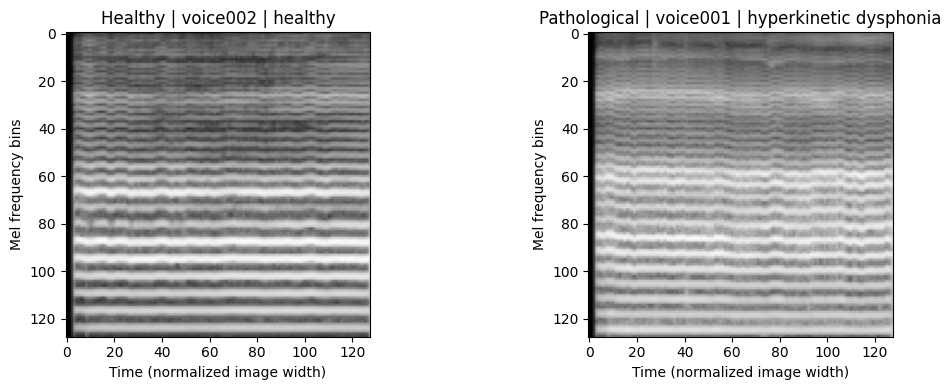

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, lab in zip(axes, [0,1]):
    s = image_manifest.loc[image_manifest.label==lab].iloc[0]
    ax.imshow(Image.open(s.image_path), cmap='gray', origin='upper', vmin=0, vmax=255)
    ax.set_title(f'{LABEL_NAME[lab]} | {s.subject_id} | {s.diagnosis}')
    ax.set_xlabel('Time (normalized image width)')
    ax.set_ylabel('Mel frequency bins')
plt.tight_layout()
plt.savefig(OUT / 'example_spectrograms.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Extract only image-based handcrafted features

**HOG** captures image edges/structures; **LBP** captures local texture; **GLCM** captures co-occurrence texture; band statistics capture row-wise (frequency) image intensity. All classifiers receive the *same* features. No diagnosis, subject ID, age, sex, or audio-derived clinical metadata enters the model.

In [ ]:
def image_features(img_path, include_hog=True):
    if isinstance(img_path, np.ndarray):
        a = np.asarray(Image.fromarray(np.asarray(img_path, dtype=np.uint8)).convert('L').resize(IMAGE_SIZE), dtype=np.uint8)
    elif isinstance(img_path, Image.Image):
        a = np.asarray(img_path.convert('L').resize(IMAGE_SIZE), dtype=np.uint8)
    else:
        a = np.asarray(Image.open(img_path).convert('L').resize(IMAGE_SIZE), dtype=np.uint8)
    h = np.empty(0, dtype=np.float32)
    if include_hog:
        h = hog(a, orientations=9, pixels_per_cell=(16,16), cells_per_block=(2,2),
                block_norm='L2-Hys', feature_vector=True)
    lbp = local_binary_pattern(a, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp, bins=np.arange(0, 11), range=(0,10), density=False)
    lbp_hist = lbp_hist.astype(np.float32) / max(1, lbp_hist.sum())
    q16 = np.minimum((a // 16).astype(np.uint8), 15)
    glcm = graycomatrix(q16, distances=[1,2], angles=[0,np.pi/4,np.pi/2,3*np.pi/4],
                        levels=16, symmetric=True, normed=True)
    props = []
    for key in ['contrast','dissimilarity','homogeneity','energy','correlation','ASM']:
        v = graycoprops(glcm, key).ravel()
        props.extend([float(np.mean(v)), float(np.std(v))])
    # Energy/structure per frequency band, as represented in the PNG.
    bands = np.array_split(a.astype(np.float32)/255.0, 8, axis=0)
    band_stats = np.array([v for b in bands for v in (b.mean(), b.std())])
    stats = np.percentile(a.astype(np.float32)/255.0, [10,25,50,75,90])
    global_stats = np.array([a.mean()/255., a.std()/255., *stats])
    out = np.concatenate([h, lbp_hist, props, band_stats, global_stats]).astype(np.float32)
    if not np.isfinite(out).all():
        raise ValueError(f'Nonfinite image features: {img_path}')
    return out

X = np.vstack([image_features(p) for p in image_manifest.image_path])
y = image_manifest.label.to_numpy(dtype=int)
groups = image_manifest.subject_id.to_numpy(dtype=str)
feature_columns = [f'img_feature_{k:04d}' for k in range(X.shape[1])]
features_csv = pd.DataFrame(X, columns=feature_columns)
features_csv.insert(0, 'subject_id', groups)
features_csv.insert(1, 'label', y)
features_csv.to_csv(OUT / 'image_features.csv', index=False)
print('Image feature matrix:', X.shape)

Image feature matrix: (208, 1809)


## 8. Strict subject-independent hold-out and internal cross-validation

The first split from a reproducible **5-fold stratified-group partition** is held out permanently as an approximate 20% test set. Hyperparameters are selected by **4-fold subject-grouped CV on the remaining 80% only**. No spectrogram windows, images, or recordings from a test subject enter training. Class balancing and PCA use only the training fold through the fitted pipeline.

In [ ]:
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer_cv.split(X, y, groups))
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
g_train, g_test = groups[train_idx], groups[test_idx]
assert set(g_train).isdisjoint(set(g_test)), 'SUBJECT LEAKAGE DETECTED'
print('Train:', len(train_idx), 'Test:', len(test_idx))
print('Train class counts:', np.bincount(y_train))
print('Test  class counts:', np.bincount(y_test))
print('Train subjects:', len(set(g_train)), 'Test subjects:', len(set(g_test)))
assert len(set(y_test)) == 2, 'Both classes must occur in the test partition.'

internal_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
for k,(ti,vi) in enumerate(internal_cv.split(X_train,y_train,g_train),1):
    assert not set(g_train[ti]).intersection(g_train[vi])
    assert len(set(y_train[ti]))==2 and len(set(y_train[vi]))==2, f'Fold {k} has a single class.'
    print('CV fold',k,'train=',len(ti),'validation=',len(vi))

pd.DataFrame({'subject_id': groups, 'label': y,
              'partition': ['train' if i in set(train_idx) else 'test' for i in range(len(y))]
             }).to_csv(OUT / 'subject_split.csv', index=False)

Train: 166 Test: 42
Train class counts: [ 46 120]
Test  class counts: [11 31]
Train subjects: 166 Test subjects: 42
CV fold 1 train= 125 validation= 41
CV fold 2 train= 124 validation= 42
CV fold 3 train= 124 validation= 42
CV fold 4 train= 125 validation= 41


## 9. Fit SVM, Random Forest and XGBoost (same image features)

Selection uses **CV macro-F1**, which gives the two clinical classes equal importance even though the dataset is imbalanced. Results are **not invented**; every reported score below is computed from the downloaded recordings.

In [ ]:
models = {
    'SVM': (
        SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=SEED),
        {'clf__C':[0.1,1,10], 'clf__gamma':['scale',0.01]}
    ),
    'Random Forest': (
        RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                               random_state=SEED, n_jobs=1),
        {'clf__min_samples_leaf':[1,3], 'clf__max_features':['sqrt',0.5]}
    ),
    'XGBoost': (
        XGBClassifier(objective='binary:logistic', eval_metric='logloss',
                      tree_method='hist', random_state=SEED, n_jobs=1,
                      subsample=0.9, colsample_bytree=0.9,
                      reg_lambda=2.0,
                      scale_pos_weight=float((y_train==0).sum()/max(1,(y_train==1).sum()))),
        {'clf__max_depth':[2,3], 'clf__learning_rate':[0.03,0.1],
         'clf__n_estimators':[150,300]}
    )
}

fitted = {}
searches = {}
cv_rows = []
for name,(clf,grid) in models.items():
    pipe = Pipeline([
        ('scale', StandardScaler()),
        ('pca', PCA(n_components=32, svd_solver='randomized', random_state=SEED)),
        ('clf', clf)
    ])
    search = GridSearchCV(pipe, param_grid=grid, scoring='f1_macro',
                          cv=internal_cv, n_jobs=-1, refit=True,
                          error_score='raise', return_train_score=False)
    print(f'\nOptimizing {name} ...')
    search.fit(X_train, y_train, groups=g_train)
    searches[name] = search
    fitted[name] = search.best_estimator_
    cv_rows.append({'Model':name, 'CV Macro-F1':search.best_score_,
                    'CV SD':search.cv_results_['std_test_score'][search.best_index_],
                    'Best parameters':json.dumps(search.best_params_)})
    print('Best CV macro-F1:', round(search.best_score_,4))
    print('Best parameters:', search.best_params_)

cv_df = pd.DataFrame(cv_rows).sort_values('CV Macro-F1', ascending=False)
cv_df.to_csv(OUT / 'cv_model_selection.csv', index=False)
display(cv_df)


Optimizing SVM ...
Best CV macro-F1: 0.6191
Best parameters: {'clf__C': 1, 'clf__gamma': 'scale'}

Optimizing Random Forest ...
Best CV macro-F1: 0.5785
Best parameters: {'clf__max_features': 0.5, 'clf__min_samples_leaf': 3}

Optimizing XGBoost ...
Best CV macro-F1: 0.6483
Best parameters: {'clf__learning_rate': 0.03, 'clf__max_depth': 3, 'clf__n_estimators': 150}


,Model,CV Macro-F1,CV SD,Best parameters
2,XGBoost,0.648289,0.107630,"{""clf__learning_rate"": 0.03, ""clf__max_depth"":..."
0,SVM,0.619101,0.097457,"{""clf__C"": 1, ""clf__gamma"": ""scale""}"
1,Random Forest,0.578469,0.065859,"{""clf__max_features"": 0.5, ""clf__min_samples_l..."


## 10. Evaluate all three classifiers on the untouched test subjects

In [ ]:
test_rows = []
test_predictions = pd.DataFrame({'subject_id':g_test, 'true_label':y_test})
for name, model in fitted.items():
    predictions = model.predict(X_test).astype(int)
    proba = model.predict_proba(X_test)[:,1]
    test_predictions[f'{name}_pred'] = predictions
    test_predictions[f'{name}_pathological_probability'] = proba
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0,1]).ravel()
    test_rows.append({
        'Model':name,
        'Accuracy':accuracy_score(y_test,predictions),
        'Balanced accuracy':balanced_accuracy_score(y_test,predictions),
        'Sensitivity':recall_score(y_test,predictions,pos_label=1,zero_division=0),
        'Specificity':tn/max(1,tn+fp),
        'Precision':precision_score(y_test,predictions,pos_label=1,zero_division=0),
        'Macro-F1':f1_score(y_test,predictions,average='macro'),
        'MCC':matthews_corrcoef(y_test,predictions),
        'AUROC':roc_auc_score(y_test,proba),
        'TN':int(tn), 'FP':int(fp), 'FN':int(fn), 'TP':int(tp),
    })
    print('\n==',name,'==')
    print(classification_report(y_test,predictions,labels=[0,1],
                                target_names=['Healthy','Pathological'],zero_division=0))
results = pd.DataFrame(test_rows)
results.to_csv(OUT / 'test_model_comparison.csv', index=False)
test_predictions.to_csv(OUT / 'held_out_test_predictions.csv', index=False)
display(results[['Model','Accuracy','Balanced accuracy','Sensitivity','Specificity',
                 'Precision','Macro-F1','MCC','AUROC']].round(4))


== SVM ==
              precision    recall  f1-score   support

     Healthy       0.35      0.64      0.45        11
Pathological       0.82      0.58      0.68        31

    accuracy                           0.60        42
   macro avg       0.58      0.61      0.57        42
weighted avg       0.70      0.60      0.62        42


== Random Forest ==
              precision    recall  f1-score   support

     Healthy       0.25      0.09      0.13        11
Pathological       0.74      0.90      0.81        31

    accuracy                           0.69        42
   macro avg       0.49      0.50      0.47        42
weighted avg       0.61      0.69      0.63        42


== XGBoost ==
              precision    recall  f1-score   support

     Healthy       0.20      0.09      0.12        11
Pathological       0.73      0.87      0.79        31

    accuracy                           0.67        42
   macro avg       0.46      0.48      0.46        42
weighted avg       0.59    

,Model,Accuracy,Balanced accuracy,Sensitivity,Specificity,Precision,Macro-F1,MCC,AUROC
0,SVM,0.5952,0.6085,0.5806,0.6364,0.8182,0.5654,0.1910,0.6334
1,Random Forest,0.6905,0.4971,0.9032,0.0909,0.7368,0.4725,-0.0088,0.5396
2,XGBoost,0.6667,0.4809,0.8710,0.0909,0.7297,0.4596,-0.0518,0.5865


## 11. Comparative figures: model performance, confusion matrices, ROC and PR curves

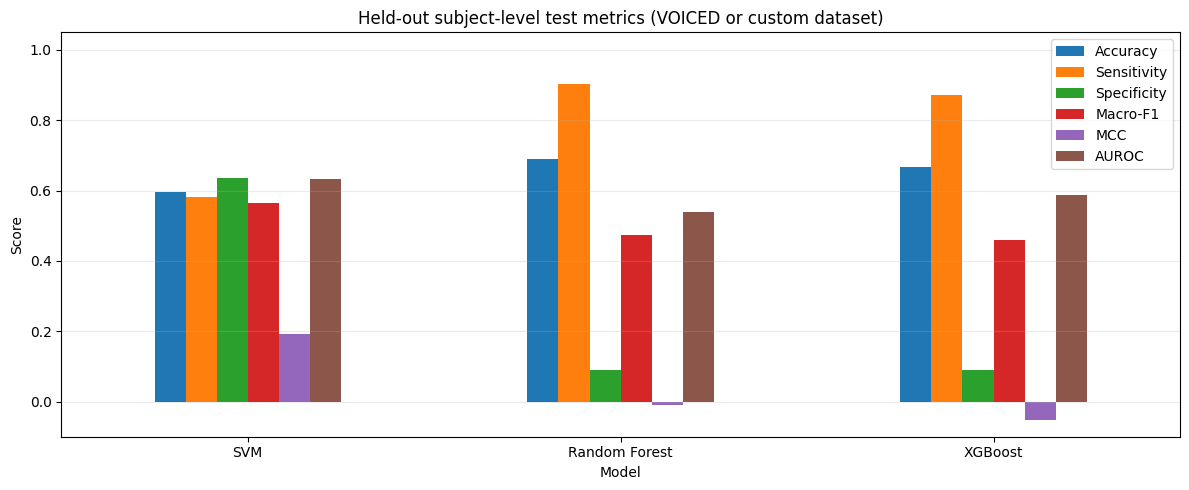

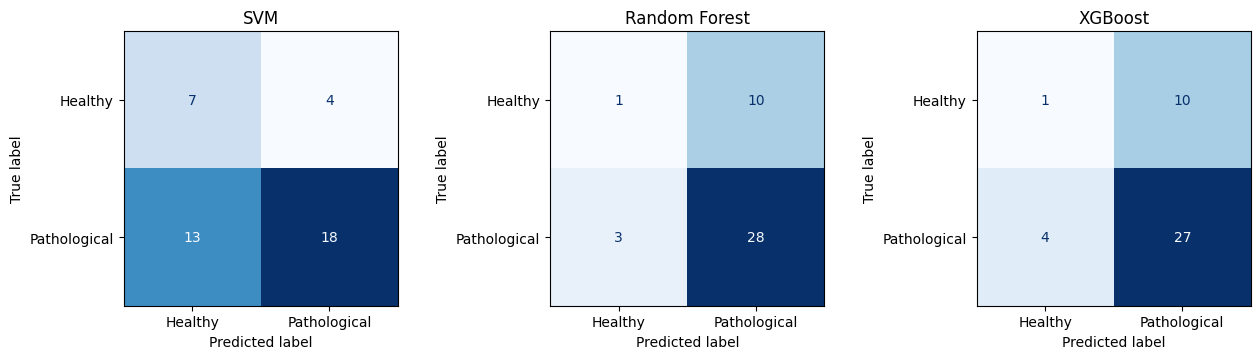

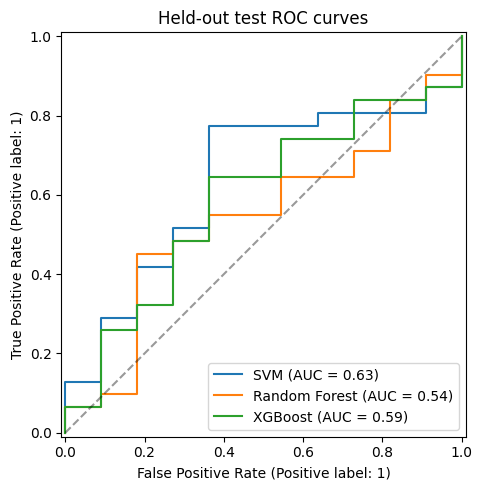

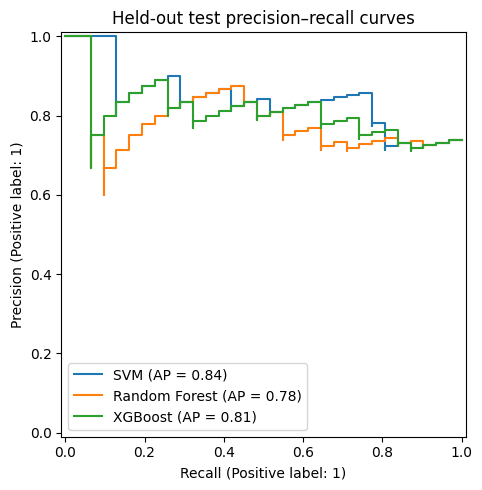

In [ ]:
ax = results.set_index('Model')[['Accuracy','Sensitivity','Specificity','Macro-F1','MCC','AUROC']].plot(
    kind='bar', figsize=(12,5), rot=0, ylim=(-0.1,1.05))
ax.set_title('Held-out subject-level test metrics (VOICED or custom dataset)')
ax.set_ylabel('Score')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / 'comparative_bar_chart.png',dpi=300,bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1,3,figsize=(13,3.7))
for ax,(name,model) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test),
       labels=[0,1], display_labels=['Healthy','Pathological'],
       ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name)
plt.tight_layout()
plt.savefig(OUT/'test_confusion_matrices.png',dpi=300,bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(6,5))
for name, model in fitted.items():
    RocCurveDisplay.from_estimator(model, X_test,y_test,ax=ax,name=name)
ax.plot([0,1],[0,1],'k--',alpha=.4)
ax.set_title('Held-out test ROC curves')
plt.tight_layout()
plt.savefig(OUT/'test_roc_curves.png',dpi=300,bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(6,5))
for name, model in fitted.items():
    PrecisionRecallDisplay.from_estimator(model,X_test,y_test,ax=ax,name=name)
ax.set_title('Held-out test precision–recall curves')
plt.tight_layout()
plt.savefig(OUT/'test_pr_curves.png',dpi=300,bbox_inches='tight')
plt.show()

## 12. Bootstrap uncertainty on the held-out subjects

95% intervals resample **held-out subjects**, not spectrogram pixels. With only about 20% of 208 VOICED participants in the test set, these confidence intervals may be wide. They reflect sampling uncertainty within the evaluated dataset; they do **not** establish performance on another language or hospital.

In [ ]:
def bootstrap_ci(y_true, pred, prob, metric, iterations=1000, seed=42):
    rng = np.random.default_rng(seed)
    idx = np.arange(len(y_true))
    values = []
    for _ in range(iterations):
        b = rng.choice(idx, size=len(idx), replace=True)
        if metric=='AUROC' and len(np.unique(y_true[b]))<2:
            continue
        if metric=='Accuracy': value=accuracy_score(y_true[b],pred[b])
        elif metric=='Macro-F1': value=f1_score(y_true[b],pred[b],average='macro')
        elif metric=='AUROC': value=roc_auc_score(y_true[b],prob[b])
        else: raise ValueError(metric)
        values.append(value)
    return np.percentile(values,[2.5,97.5])

ci_rows=[]
for name, model in fitted.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:,1]
    for metric in ['Accuracy','Macro-F1','AUROC']:
        lo,hi = bootstrap_ci(y_test,pred,prob,metric,seed=SEED)
        ci_rows.append({'Model':name,'Metric':metric,'Lower 95%':lo,'Upper 95%':hi})
ci_df=pd.DataFrame(ci_rows)
ci_df.to_csv(OUT/'bootstrap_confidence_intervals.csv',index=False)
display(ci_df.round(4))

,Model,Metric,Lower 95%,Upper 95%
0,SVM,Accuracy,0.4524,0.7381
1,SVM,Macro-F1,0.4071,0.7117
2,SVM,AUROC,0.4375,0.8114
3,Random Forest,Accuracy,0.5476,0.8095
4,Random Forest,Macro-F1,0.3636,0.6112
5,Random Forest,AUROC,0.3347,0.7334
6,XGBoost,Accuracy,0.5238,0.8095
7,XGBoost,Macro-F1,0.3538,0.6064
8,XGBoost,AUROC,0.3783,0.7806


## 13. Explainability I — global feature-family reliance across SVM, RF and XGBoost

We compute **grouped permutation importance** on the held-out test subjects. For each model, all columns belonging to one feature family are shuffled *together*, preserving their joint internal structure and retaining exactly the same fitted estimator. This is an interpretability analysis, **not model selection**. Negative values are possible because test scores are noisy. Permuted feature combinations may be unrealistic; use these results cautiously, especially when feature groups are correlated.

HOG = spectrogram edge patterns; LBP = local image texture; GLCM = texture co-occurrence; Mel-band statistics = intensity patterns by vertical frequency band; Global statistics = overall grayscale distribution. This does **not** directly identify a vocal pathology or anatomical lesion.

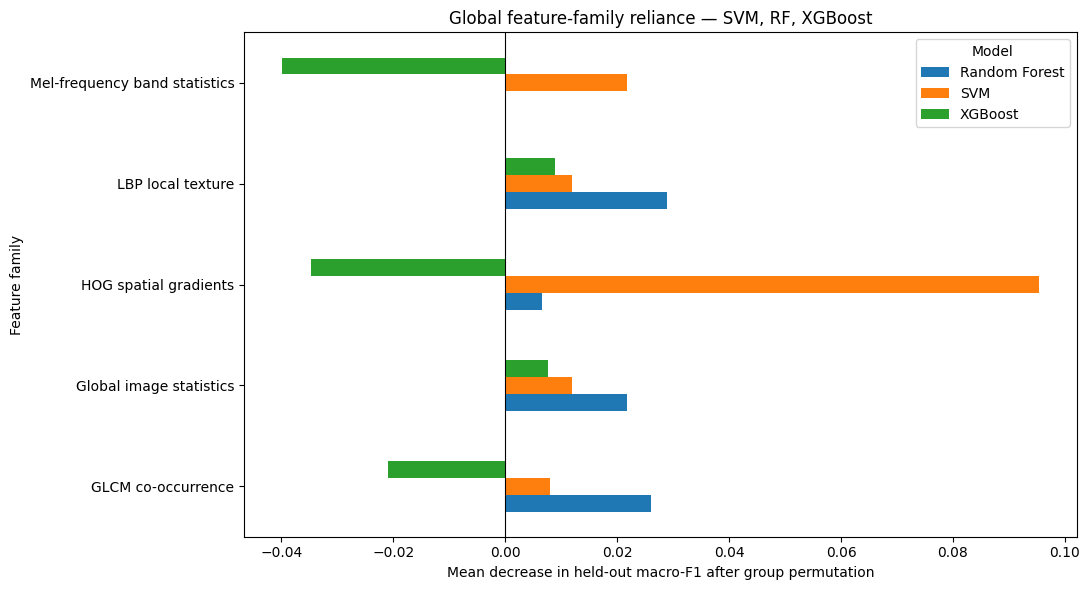

,Model,Feature family,Baseline macro-F1,Mean macro-F1 reduction,SD,Repetitions
0,SVM,HOG spatial gradients,0.5654,0.0954,0.0740,10
1,SVM,LBP local texture,0.5654,0.0119,0.0102,10
2,SVM,GLCM co-occurrence,0.5654,0.0079,0.0102,10
3,SVM,Mel-frequency band statistics,0.5654,0.0217,0.0112,10
4,SVM,Global image statistics,0.5654,0.0119,0.0102,10
5,Random Forest,HOG spatial gradients,0.4725,0.0066,0.0668,10
6,Random Forest,LBP local texture,0.4725,0.0290,0.0374,10
7,Random Forest,GLCM co-occurrence,0.4725,0.0261,0.0365,10
8,Random Forest,Mel-frequency band statistics,0.4725,0.0000,0.0000,10
9,Random Forest,Global image statistics,0.4725,0.0217,0.0350,10


In [ ]:
from sklearn.metrics import f1_score

# Must agree with the exact order of concatenation in image_features().
HOG_DIM = len(hog(np.zeros((IMAGE_SIZE[1], IMAGE_SIZE[0]), dtype=np.uint8),
                  orientations=9, pixels_per_cell=(16,16), cells_per_block=(2,2),
                  block_norm='L2-Hys', feature_vector=True))
FEATURE_GROUPS = {
    'HOG spatial gradients': slice(0, HOG_DIM),
    'LBP local texture': slice(HOG_DIM, HOG_DIM+10),
    'GLCM co-occurrence': slice(HOG_DIM+10, HOG_DIM+22),
    'Mel-frequency band statistics': slice(HOG_DIM+22, HOG_DIM+38),
    'Global image statistics': slice(HOG_DIM+38, HOG_DIM+45),
}
assert HOG_DIM + 45 == X.shape[1], (HOG_DIM, X.shape[1])

GROUP_PERM_REPEATS = 10   # Increase to 30 for a manuscript, if compute budget permits.
rng = np.random.default_rng(SEED)
perm_rows = []
for model_name, estimator in fitted.items():
    baseline = f1_score(y_test, estimator.predict(X_test), average='macro')
    for feature_group, subset in FEATURE_GROUPS.items():
        drops=[]
        for _ in range(GROUP_PERM_REPEATS):
            permuted = X_test.copy()
            permuted[:, subset] = X_test[rng.permutation(len(X_test)), subset]
            shuffled_score = f1_score(y_test, estimator.predict(permuted), average='macro')
            drops.append(baseline - shuffled_score)
        perm_rows.append({'Model':model_name, 'Feature family':feature_group,
                          'Baseline macro-F1':baseline,
                          'Mean macro-F1 reduction':float(np.mean(drops)),
                          'SD':float(np.std(drops,ddof=1)),
                          'Repetitions':GROUP_PERM_REPEATS})

perm_df = pd.DataFrame(perm_rows)
perm_df.to_csv(OUT/'explainability_grouped_permutation.csv', index=False)
plot_df = perm_df.pivot(index='Feature family',columns='Model',values='Mean macro-F1 reduction')
ax=plot_df.plot.barh(figsize=(11,6))
ax.axvline(0, color='black',lw=0.8)
ax.set_xlabel('Mean decrease in held-out macro-F1 after group permutation')
ax.set_title('Global feature-family reliance — SVM, RF, XGBoost')
plt.tight_layout()
plt.savefig(OUT/'explainability_grouped_permutation.png',dpi=300,bbox_inches='tight')
plt.show()
display(perm_df.round(4))

## 14. Explainability II — interpretable XGBoost ablation + Tree SHAP

The original three-model comparison applies **PCA** to all 1,809 image descriptors. SHAP on those PCA coordinates would explain *abstract principal components*, not directly identifiable image statistics. For readable attributions, we therefore train a **supplementary XGBoost feature-family ablation** on the 45 non-HOG descriptors (10 LBP bins, 12 GLCM summaries, 16 frequency-band statistics, and 7 global image statistics) **without PCA**.

This is a separately cross-validated **XGBoost ablation**, not a performance replacement for the original three-way comparison. The held-out subjects remain untouched until evaluation. Tree SHAP values explain **model log-odds for class 1 (pathological voice)**, not causal or medically established biomarkers. The XGBoost native `pred_contribs=True` gives exact tree contributions without a fragile external SHAP dependency.

In [ ]:
import xgboost as xgb
from scipy.special import expit

COMPACT_START = HOG_DIM
X_train_compact = X_train[:, COMPACT_START:]
X_test_compact = X_test[:, COMPACT_START:]
GLCM_KEYS = ['contrast','dissimilarity','homogeneity','energy','correlation','ASM']
compact_feature_names = (
    [f'LBP_uniform_bin_{i}' for i in range(10)] +
    [f'GLCM_{k}_{stat}' for k in GLCM_KEYS for stat in ['mean','sd']] +
    [f'Mel_band_high_to_low_{i+1}_{stat}' for i in range(8) for stat in ['mean','sd']] +
    ['Image_mean','Image_sd','Image_q10','Image_q25','Image_q50','Image_q75','Image_q90']
)
assert X_train_compact.shape[1] == len(compact_feature_names) == 45

interpretable_clf = XGBClassifier(
    objective='binary:logistic',eval_metric='logloss',tree_method='hist',
    random_state=SEED,n_jobs=1,subsample=0.9,colsample_bytree=0.9,
    reg_lambda=2.0,
    scale_pos_weight=float((y_train==0).sum()/max(1,(y_train==1).sum()))
)
compact_search = GridSearchCV(
    interpretable_clf,
    param_grid={'max_depth':[2,3], 'learning_rate':[0.03,0.1], 'n_estimators':[100,200]},
    scoring='f1_macro', cv=internal_cv, n_jobs=-1,refit=True,error_score='raise'
)
compact_search.fit(X_train_compact, y_train,groups=g_train)
compact_clf=compact_search.best_estimator_
compact_pred=compact_clf.predict(X_test_compact).astype(int)
compact_proba=compact_clf.predict_proba(X_test_compact)[:,1]
compact_cm=confusion_matrix(y_test,compact_pred,labels=[0,1])
compact_report={
    'Model':'XGBoost (45 interpretable features; supplementary ablation)',
    'CV macro-F1':float(compact_search.best_score_),
    'Held-out accuracy':accuracy_score(y_test,compact_pred),
    'Held-out macro-F1':f1_score(y_test,compact_pred,average='macro'),
    'Held-out MCC':matthews_corrcoef(y_test,compact_pred),
    'Held-out AUROC':roc_auc_score(y_test,compact_proba),
    'TN':int(compact_cm[0,0]), 'FP':int(compact_cm[0,1]),
    'FN':int(compact_cm[1,0]), 'TP':int(compact_cm[1,1]),
    'Parameters':str(compact_search.best_params_)
}
pd.DataFrame([compact_report]).to_csv(OUT/'explainability_compact_xgboost_ablation.csv', index=False)
joblib.dump(compact_clf,OUT/'explainability_compact_xgboost.joblib')
print('This is a separate, compact-feature XGBoost ablation:')
display(pd.DataFrame([compact_report]).T)

This is a separate, compact-feature XGBoost ablation:


,0
Model,XGBoost (45 interpretable features; supplement...
CV macro-F1,0.570311
Held-out accuracy,0.690476
Held-out macro-F1,0.629831
Held-out MCC,0.268044
Held-out AUROC,0.715543
TN,6
FP,5
FN,8
TP,23


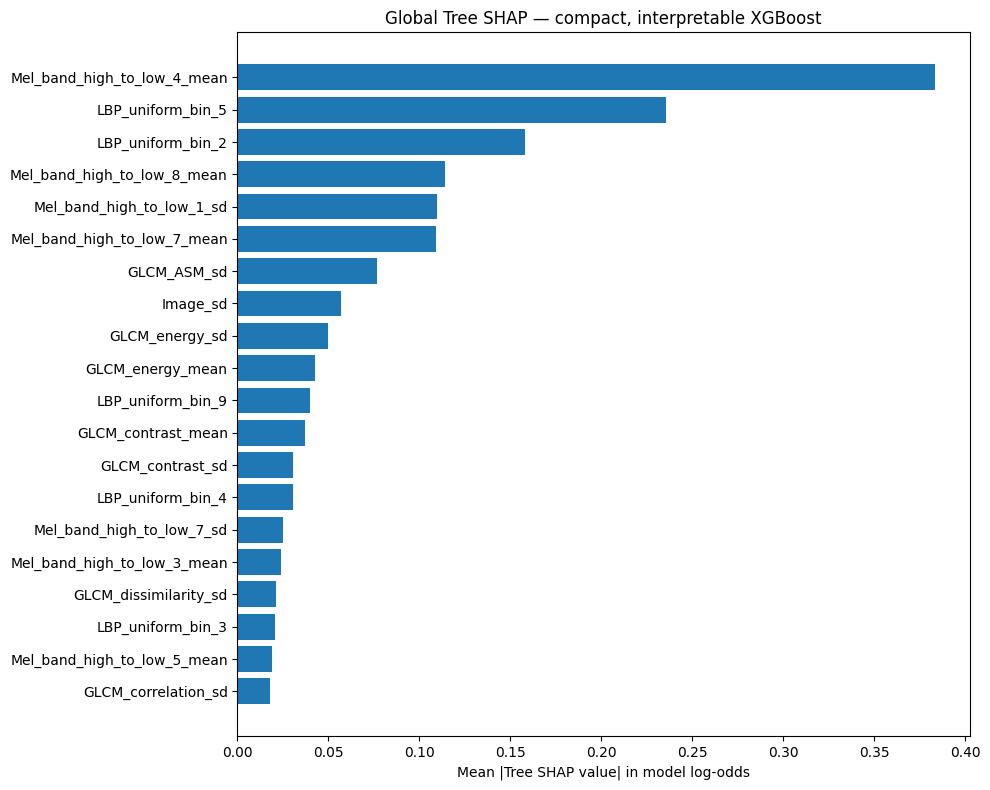

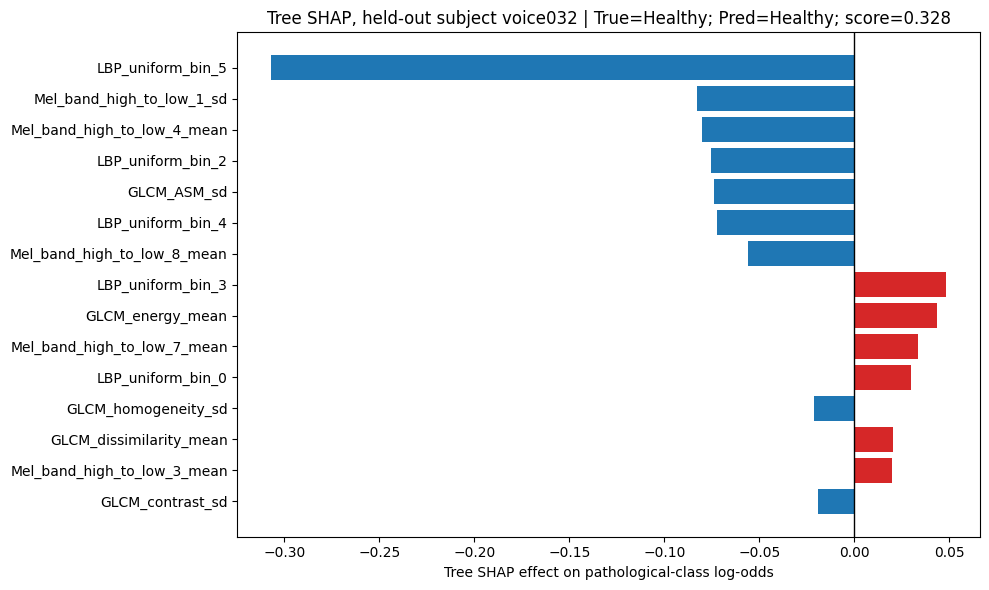

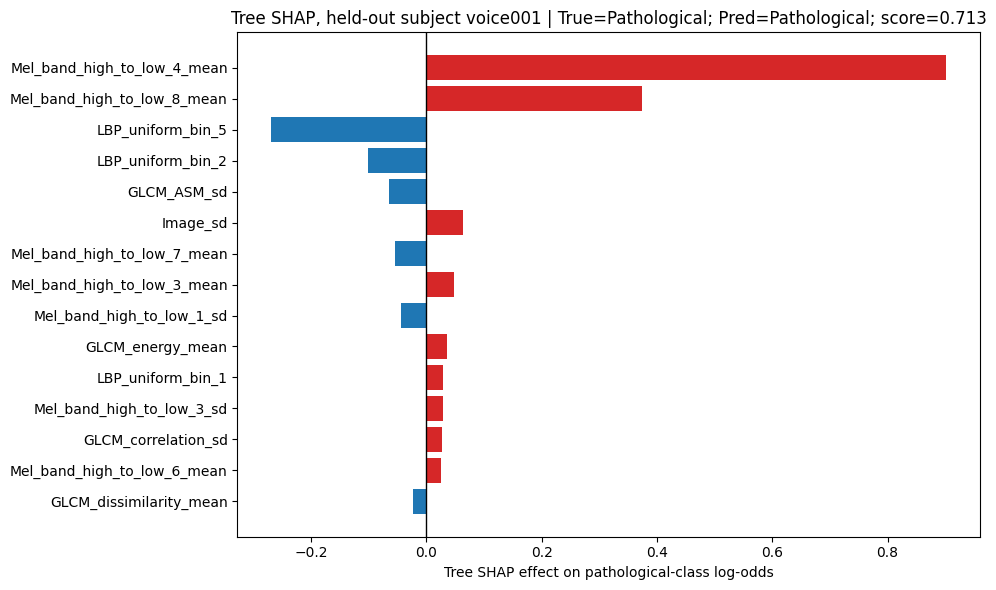

,Feature,Mean absolute Tree SHAP (log-odds)
28,Mel_band_high_to_low_4_mean,0.383553
5,LBP_uniform_bin_5,0.235881
2,LBP_uniform_bin_2,0.158236
36,Mel_band_high_to_low_8_mean,0.113917
23,Mel_band_high_to_low_1_sd,0.109826
34,Mel_band_high_to_low_7_mean,0.109429
21,GLCM_ASM_sd,0.076465
39,Image_sd,0.056841
17,GLCM_energy_sd,0.049684
16,GLCM_energy_mean,0.042738


In [ ]:
# XGBoost native Tree SHAP: last column is the expected-value/bias term.
dtest=xgb.DMatrix(X_test_compact) # Order is identical to compact_feature_names.
contributions=compact_clf.get_booster().predict(dtest,pred_contribs=True)
assert contributions.shape==(len(X_test_compact),len(compact_feature_names)+1)
shap_values=contributions[:,:-1]
bias_terms=contributions[:,-1]
assert np.allclose(expit(contributions.sum(axis=1)), compact_proba,atol=2e-5)

shap_export=pd.DataFrame(shap_values, columns=compact_feature_names)
shap_export.insert(0,'subject_id',g_test)
shap_export.insert(1,'label',y_test)
shap_export.insert(2,'predicted_class',compact_pred)
shap_export.insert(3,'model_score_pathological',compact_proba)
shap_export.to_csv(OUT/'explainability_shap_local_values.csv',index=False)

shap_importance=np.abs(shap_values).mean(axis=0)
feature_ranking=pd.DataFrame({'Feature':compact_feature_names,
                              'Mean absolute Tree SHAP (log-odds)':shap_importance})
feature_ranking=feature_ranking.sort_values('Mean absolute Tree SHAP (log-odds)',ascending=False)
feature_ranking.to_csv(OUT/'explainability_shap_global_ranking.csv',index=False)

top=feature_ranking.head(20).iloc[::-1]
fig,ax=plt.subplots(figsize=(10,8))
ax.barh(top['Feature'],top['Mean absolute Tree SHAP (log-odds)'])
ax.set_xlabel('Mean |Tree SHAP value| in model log-odds')
ax.set_title('Global Tree SHAP — compact, interpretable XGBoost')
plt.tight_layout()
plt.savefig(OUT/'explainability_shap_global.png',dpi=300,bbox_inches='tight')
plt.show()

# One deterministic explanation per ground-truth class, preferring correctly classified subjects.
example_test_positions=[]
for wanted_label in [0,1]:
    candidates=np.where((y_test==wanted_label)&(compact_pred==y_test))[0]
    if len(candidates)==0:
        candidates=np.where(y_test==wanted_label)[0]
    example_test_positions.append(int(candidates[0]))

for pos in example_test_positions:
    local=shap_values[pos]
    selected=np.argsort(np.abs(local))[-15:]
    fig,ax=plt.subplots(figsize=(10,6))
    colors=['tab:red' if v>0 else 'tab:blue' for v in local[selected]]
    ax.barh([compact_feature_names[i] for i in selected], local[selected],color=colors)
    ax.axvline(0,linewidth=1,color='black')
    ax.set_xlabel('Tree SHAP effect on pathological-class log-odds')
    ax.set_title(f'Tree SHAP, held-out subject {g_test[pos]} | True={LABEL_NAME[y_test[pos]]}; '
                 f'Pred={LABEL_NAME[compact_pred[pos]]}; score={compact_proba[pos]:.3f}')
    plt.tight_layout()
    plt.savefig(OUT/f'explainability_shap_local_test_{pos}.png',dpi=300,bbox_inches='tight')
    plt.show()

display(feature_ranking.head(15))

## 15. Explainability III — spectrogram occlusion heatmaps (SVM, RF or XGBoost)

This analysis attributes each model's prediction to locations in the **original 128×128 log-Mel spectrogram**, including for models that use HOG, PCA, or other non-differentiable transformations. A held-out spectrogram is divided into an 8×8 grid; each patch is replaced, in turn, with the **median corresponding pixels from TRAINING subjects only**. We re-extract *all* image descriptors and measure the decrease in the model's score for the predicted class.

These are **perturbation-sensitivity maps**, not neural-network Grad-CAM maps or proof of anatomical disease markers. Blurring/resizing into a 128×128 image causes relative-time alignment rather than second-by-second alignment. A dark/bright area is useful only to understand the fitted classifier and should not be described as a clinical lesion.

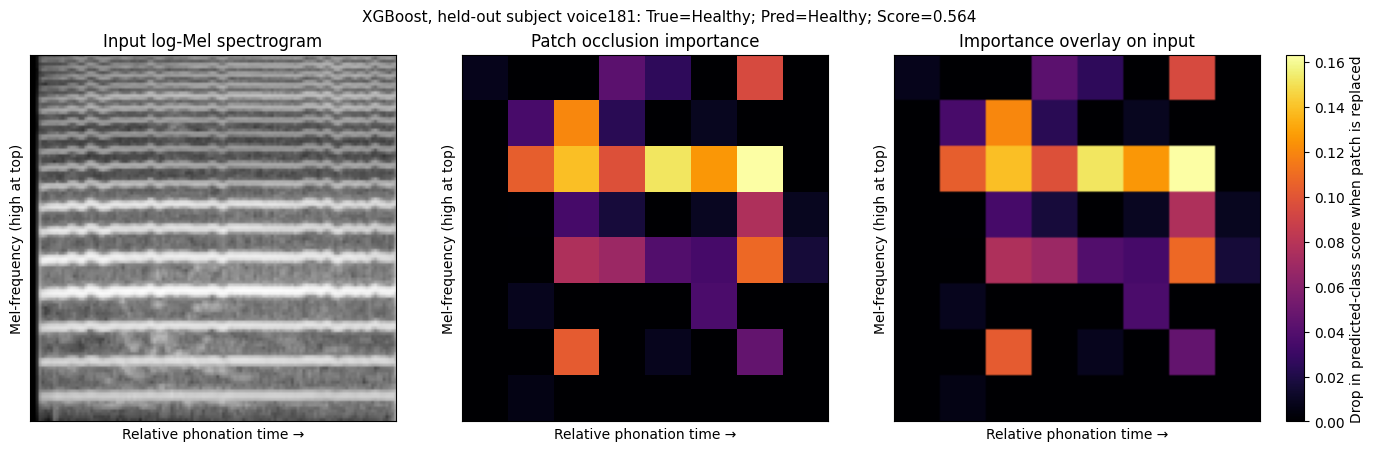

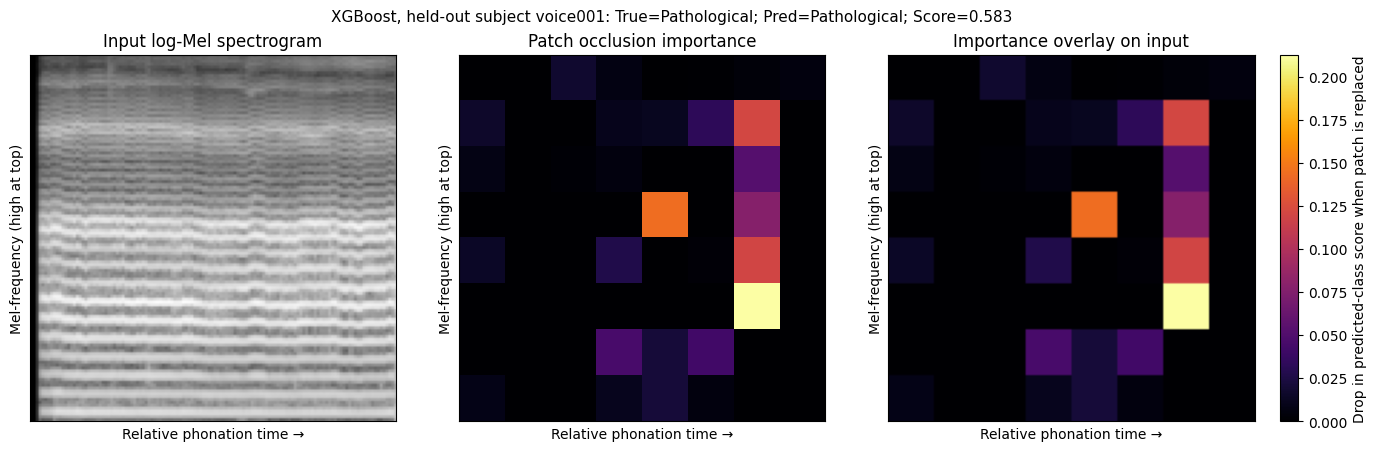

Interpretability files saved. These maps identify regions influencing model output, not diagnoses.


In [ ]:
# Reference patch template from TRAINING spectra only; no labels or test pixels included.
train_images=np.stack([
    np.asarray(Image.open(image_manifest.iloc[i].image_path).convert('L').resize(IMAGE_SIZE),dtype=np.uint8)
    for i in train_idx
],axis=0)
reference_image=np.median(train_images,axis=0).astype(np.uint8)
Image.fromarray(reference_image).save(OUT/'explainability_training_reference_spectrogram.png')
del train_images

OCCLUSION_GRID = (8,8)

def occlusion_grid(model, image_array, baseline_img, grid_shape=(8,8)):
    """Positive grid values mean the region supports the ORIGINAL predicted class."""
    height,width=image_array.shape
    nrows,ncols=grid_shape
    assert height % nrows == 0 and width % ncols == 0
    original_features=image_features(image_array).reshape(1,-1)
    pred=int(model.predict(original_features)[0])
    original_score=float(model.predict_proba(original_features)[0,pred])
    grid=np.zeros((nrows,ncols),dtype=float)
    for r in range(nrows):
        y0,y1=r*(height//nrows),(r+1)*(height//nrows)
        for c in range(ncols):
            x0,x1=c*(width//ncols),(c+1)*(width//ncols)
            masked=image_array.copy()
            masked[y0:y1,x0:x1]=baseline_img[y0:y1,x0:x1]
            p=float(model.predict_proba(image_features(masked).reshape(1,-1))[0,pred])
            grid[r,c]=original_score-p
    return pred,original_score,grid

# Select two examples without using model probability to cherry-pick.
selected_model_name=str(cv_df.iloc[0]['Model'])
selected_model=fitted[selected_model_name]  # Selected using TRAINING CV, not test performance.
selected_model_predictions=selected_model.predict(X_test).astype(int)
selected_positions=[]
for desired_label in [0,1]:
    correct=np.where((y_test==desired_label)&(selected_model_predictions==y_test))[0]
    if len(correct)==0:
        correct=np.where(y_test==desired_label)[0]
    selected_positions.append(int(correct[0]))

occlusion_rows=[]
for pos in selected_positions:
    img=np.asarray(Image.open(image_manifest.iloc[test_idx[pos]].image_path).convert('L').resize(IMAGE_SIZE),dtype=np.uint8)
    pred,original_score,importance=occlusion_grid(selected_model,img,reference_image,OCCLUSION_GRID)
    for r in range(importance.shape[0]):
        for c in range(importance.shape[1]):
            occlusion_rows.append({'model':selected_model_name,'test_position':pos,
                                   'subject_id':g_test[pos], 'true_label':int(y_test[pos]),
                                   'predicted_label':pred, 'predicted_class_score':original_score,
                                   'high_to_low_frequency_row':r,'relative_time_column':c,
                                   'change_in_predicted_class_score':importance[r,c]})
    upsampled=np.kron(np.clip(importance,0,None),np.ones((16,16),dtype=float))
    fig,axes=plt.subplots(1,3,figsize=(14,4.4),constrained_layout=True)
    axes[0].imshow(img,cmap='gray',vmin=0,vmax=255)
    axes[0].set_title('Input log-Mel spectrogram')
    im=axes[1].imshow(importance,cmap='inferno',interpolation='nearest',vmin=0,
                      vmax=max(float(np.max(upsampled)),1e-8))
    axes[1].set_title('Patch occlusion importance')
    axes[2].imshow(img,cmap='gray',vmin=0,vmax=255)
    axes[2].imshow(upsampled,cmap='inferno',vmin=0,
                   vmax=max(float(np.max(upsampled)),1e-8),
                   alpha=np.where(upsampled>0,0.55,0.0))
    axes[2].set_title('Importance overlay on input')
    for a in axes:
        a.set_xlabel('Relative phonation time →')
        a.set_ylabel('Mel-frequency (high at top)')
        a.set_xticks([]); a.set_yticks([])
    fig.colorbar(im,ax=axes.ravel().tolist(),fraction=0.017,pad=0.02,
                 label='Drop in predicted-class score when patch is replaced')
    fig.suptitle(f'{selected_model_name}, held-out subject {g_test[pos]}: '
                 f'True={LABEL_NAME[y_test[pos]]}; Pred={LABEL_NAME[pred]}; '
                 f'Score={original_score:.3f}',fontsize=11)
    fig.savefig(OUT/f'explainability_occlusion_subject_{pos}.png',dpi=300,bbox_inches='tight')
    plt.show()

pd.DataFrame(occlusion_rows).to_csv(OUT/'explainability_occlusion_values.csv',index=False)
print('Interpretability files saved. These maps identify regions influencing model output, not diagnoses.')

### Manuscript interpretation and validation cautions

- **Global:** Grouped permutation indicates which **image descriptor families** influence each algorithm; it cannot establish causal relevance. Correlated features may reduce or distort a family's apparent importance.
- **Local (feature-level):** Tree SHAP quantifies the signed contributions of named texture/band descriptors to the **compact XGBoost model's pathological-class log-odds**. Positive SHAP indicates higher pathological-class score; negative indicates lower, conditional on the model and chosen SHAP baseline.
- **Local (image-level):** Occlusion sensitivity identifies frequency–time patches whose replacement reduces the predicted-class score. The heatmap is a model explanation of spectrogram image processing, *not* direct evidence of a biological acoustic marker.
- **Validation:** Subject-disjoint partitioning must precede feature or image augmentation, and independent Arabic data are needed to claim Arabic-language transfer. Explainability quality should ideally be examined by a speech-language clinician and tested for stability across seeds or recording conditions.

**Suggested figure set:** Figure A — original spectrogram / occlusion map / overlay (healthy and disordered participants); Figure B — global SHAP ranking; Figure C — grouped-permutation importance across SVM, RF, XGBoost. Use only actual computed images in the manuscript, not illustrative images.


## 16. Save final model and run an optional new WAV file

Select the winner **by training-only CV macro-F1**, not by test performance. The example prediction only applies to recordings resembling the training task (approximately five seconds of sustained vowel `/a/`). It is **not a clinical diagnosis**.

In [ ]:
best_name = cv_df.iloc[0]['Model']
best_model = fitted[best_name]
joblib.dump(best_model, OUT / 'best_image_classifier.joblib')
with open(OUT/'model_metadata.json','w') as f:
    json.dump({
        'dataset_mode':DATASET_MODE,
        'class_names':LABEL_NAME,
        'positive_class':1,
        'selected_by':'4-fold training-only subject-grouped CV macro-F1',
        'selected_model':best_name,
        'n_train':len(train_idx), 'n_test':len(test_idx),
        'n_unique_train_subjects':len(set(g_train)),
        'n_unique_test_subjects':len(set(g_test)),
        'target_sampling_rate':TARGET_SR,
        'image_size':IMAGE_SIZE,
        'n_mels':N_MELS,'n_fft':N_FFT,'hop_length':HOP_LENGTH,
        'caution':'Do not interpret as disorder diagnosis or assume Arabic/language transfer without external validation'
    }, f, indent=2)
print('Model selected from cross-validation:', best_name)
print('Saved:', OUT/'best_image_classifier.joblib')

Model selected from cross-validation: XGBoost
Saved: /content/voice_image_ml/results/best_image_classifier.joblib


In [ ]:
# OPTIONAL INFERENCE: uncomment the following lines to upload a sustained-vowel WAV.
# from google.colab import files
# uploaded = files.upload()
# wav_path = next(iter(uploaded))
# audio, sr = librosa.load(wav_path, sr=TARGET_SR, mono=True)
# img = audio_to_spectrogram_image(audio, sr)
# example_path = OUT / 'new_voice_spectrogram.png'
# img.save(example_path)
# feat = image_features(example_path).reshape(1,-1)
# score = float(best_model.predict_proba(feat)[0,1])
# print(f'Model score for pathological class: {score:.3f}')
# print('This score is not a calibrated clinical probability or a diagnosis.')
# display(img)

## 17. Compare spectrogram features with voice-quality measures

The earlier high-dimensional image experiment uses an individual holdout. This follow-up uses the same five outer folds across all nine combinations of feature sets and classifiers. Each participant has one feature vector. If a participant supplied repeated sustained vowels, the notebook takes the median per feature. Four inner folds select model hyperparameters by balanced accuracy. Imputation, scaling and class weighting are computed during fitting within each training split. The majority-class baseline predicts the most frequent training label.

| Feature set | Descriptors |
|---|---|
| Spectrogram | 45 named texture and Mel-band descriptors from Section 14 |
| Voice quality | Eight acoustic descriptors measured from the sustained vowel |
| Fusion | All 53 descriptors |

Praat measures the central three seconds at the same sampling rate used for the spectrogram. The features include median and variability of F0 and harmonics-to-noise ratio (HNR), voiced-frame fraction, local jitter, local shimmer, and smoothed cepstral peak prominence (CPPS). CPPS uses a 60–330 Hz peak search range and a 4 kHz analysis limit at the VOICED sampling rate. Undefined values are reported and imputed within training folds. [Praat CPPS documentation](https://praat.org/manual/PowerCepstrogram__Get_CPPS___.html)

These folds estimate performance within the same dataset. The follow-up was designed after examining the first holdout results, so treat it as exploratory. For custom data, use comparable sustained-vowel recordings and independently established labels.

In [ ]:
import parselmouth
from parselmouth.praat import call as praat_call

PITCH_FLOOR = 60
PITCH_CEILING = 450
ANALYSIS_SECONDS = 3.0


def voice_quality_features(signal, sr):
    """Measure sustained phonation from the central three seconds, or the full shorter clip."""
    width = min(len(signal), round(ANALYSIS_SECONDS * sr))
    start = (len(signal) - width) // 2
    snd = parselmouth.Sound(signal[start:start + width], sampling_frequency=sr)
    pitch = snd.to_pitch(time_step=0.01, pitch_floor=PITCH_FLOOR, pitch_ceiling=PITCH_CEILING)
    f0 = pitch.selected_array['frequency']
    voiced_f0 = f0[f0 > 0]
    harmonicity = snd.to_harmonicity_cc(time_step=0.01, minimum_pitch=PITCH_FLOOR)
    hnr = harmonicity.values.ravel()
    hnr = hnr[hnr > -200]  # Praat's undefined frames are represented by -200 dB.
    pulses = praat_call(snd, 'To PointProcess (periodic, cc)', PITCH_FLOOR, PITCH_CEILING)
    period_settings = (0.0, 0.0, 1 / PITCH_CEILING, 1 / PITCH_FLOOR, 1.3)
    jitter = praat_call(pulses, 'Get jitter (local)', *period_settings)
    shimmer = praat_call([snd, pulses], 'Get shimmer (local)', *period_settings, 1.6)
    cepstrum = praat_call(snd, 'To PowerCepstrogram', PITCH_FLOOR, 0.002, min(sr / 2, 5000), 50.0)
    cpps = praat_call(cepstrum, 'Get CPPS', False, 0.01, 0.001,
                      PITCH_FLOOR, 330.0, 0.05, 'Parabolic', 0.001, 0.0, 'Straight', 'Robust')
    features = {
        'f0_median_hz': np.median(voiced_f0) if len(voiced_f0) else np.nan,
        'f0_iqr_hz': np.subtract(*np.percentile(voiced_f0, [75, 25])) if len(voiced_f0) else np.nan,
        'voiced_frame_fraction': len(voiced_f0) / len(f0) if len(f0) else np.nan,
        'hnr_median_db': np.median(hnr) if len(hnr) else np.nan,
        'hnr_iqr_db': np.subtract(*np.percentile(hnr, [75, 25])) if len(hnr) else np.nan,
        'jitter_local_percent': 100 * jitter,
        'shimmer_local_percent': 100 * shimmer,
        'cpps_db': cpps,
    }
    return {name: value if np.isfinite(value) else np.nan for name, value in features.items()}


quality_rows = []
for count, row in enumerate(manifest.itertuples(index=False), start=1):
    quality_rows.append(voice_quality_features(*load_voice(row)))
    if count % 50 == 0 or count == len(manifest):
        print(f'Measured voice quality for {count}/{len(manifest)} recordings', flush=True)
quality = pd.DataFrame(quality_rows)
quality.insert(0, 'sample_id', image_manifest.sample_id.to_numpy())
quality.insert(1, 'subject_id', image_manifest.subject_id.to_numpy())
quality.insert(2, 'label', image_manifest.label.to_numpy())
quality.to_csv(OUT / 'voice_quality_features.csv', index=False)
quality_names = quality.columns[3:].tolist()
print('Undefined voice-quality values per feature:')
display(quality[quality_names].isna().sum().to_frame('Missing recordings'))

Measured voice quality for 50/208 recordings
Measured voice quality for 100/208 recordings
Measured voice quality for 150/208 recordings
Measured voice quality for 200/208 recordings
Measured voice quality for 208/208 recordings
Undefined voice-quality values per feature:


,Missing recordings
f0_median_hz,0
f0_iqr_hz,0
voiced_frame_fraction,0
hnr_median_db,0
hnr_iqr_db,0
jitter_local_percent,0
shimmer_local_percent,0
cpps_db,0


In [ ]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight

# Compact image descriptors use the same names and ordering as the earlier Tree SHAP section.
record_features = pd.DataFrame(X[:, HOG_DIM:], columns=compact_feature_names)
record_features[quality_names] = quality[quality_names].to_numpy()
record_features['subject_id'] = groups
record_features['label'] = y

# For repeated sustained vowels from a participant, use the median per descriptor.
# The label consistency check earlier in the notebook applies here as well.
subject_features = record_features.groupby(['subject_id', 'label'], as_index=False).median()
subject_y = subject_features.label.to_numpy(dtype=int)
subject_ids = subject_features.subject_id.to_numpy(dtype=str)
feature_sets = {
    'Spectrogram': compact_feature_names,
    'Voice quality': quality_names,
    'Fusion': compact_feature_names + quality_names,
}
subject_features.to_csv(OUT / 'nested_cv_participant_features.csv', index=False)
outer_splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
                    .split(subject_ids, subject_y))


class BalancedXGBClassifier(XGBClassifier):
    def fit(self, X, y, **kwargs):
        return super().fit(X, y, sample_weight=compute_sample_weight('balanced', y), **kwargs)


nested_models = {
    'SVM': (SVC(class_weight='balanced'),
            {'model__kernel': ['linear', 'rbf'], 'model__C': [0.1, 1, 10]}),
    'Random Forest': (
        RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEED, n_jobs=1),
        {'model__max_depth': [3, None], 'model__min_samples_leaf': [2, 5]}),
    'XGBoost': (
        BalancedXGBClassifier(objective='binary:logistic', eval_metric='logloss',
                              tree_method='hist', n_estimators=160,
                              random_state=SEED, n_jobs=1),
        {'model__max_depth': [1, 2, 3], 'model__learning_rate': [0.03, 0.10]}),
}


def binary_metrics(labels, predictions):
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    return {
        'Accuracy': accuracy_score(labels, predictions),
        'Balanced accuracy': balanced_accuracy_score(labels, predictions),
        'Sensitivity': tp / (tp + fn),
        'Specificity': tn / (tn + fp),
        'Macro-F1': f1_score(labels, predictions, labels=[0, 1], average='macro'),
        'MCC': matthews_corrcoef(labels, predictions),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }


def model_score(estimator, features):
    if hasattr(estimator, 'decision_function'):
        return estimator.decision_function(features)
    return estimator.predict_proba(features)[:, 1]


nested_predictions = []
nested_metrics = []
nested_contributions = []
for fold, (fit_idx, eval_idx) in enumerate(outer_splits, start=1):
    fit_y, eval_y = subject_y[fit_idx], subject_y[eval_idx]
    assert set(subject_ids[fit_idx]).isdisjoint(subject_ids[eval_idx])
    inner = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED + fold)

    def save_evaluation(name, feature_set, estimator, eval_x, parameters):
        predictions = estimator.predict(eval_x)
        scores = model_score(estimator, eval_x)
        metrics = binary_metrics(eval_y, predictions)
        metrics['AUROC'] = roc_auc_score(eval_y, scores)
        metrics['Average precision'] = average_precision_score(eval_y, scores)
        nested_metrics.append({'Fold': fold, 'Features': feature_set, 'Model': name,
                               'Parameters': json.dumps(parameters), **metrics})
        nested_predictions.append(pd.DataFrame({
            'Fold': fold, 'Features': feature_set, 'Model': name,
            'subject_id': subject_ids[eval_idx], 'True label': eval_y,
            'Prediction': predictions, 'Pathology score': scores,
        }))

    baseline_x = np.zeros((len(fit_idx), 1))
    baseline = DummyClassifier(strategy='most_frequent').fit(baseline_x, fit_y)
    save_evaluation('Majority class', 'None', baseline, np.zeros((len(eval_idx), 1)), {})

    for feature_set, columns in feature_sets.items():
        features = subject_features[columns].to_numpy(dtype=float)
        fit_x, eval_x = features[fit_idx], features[eval_idx]
        for name, (classifier, parameter_grid) in nested_models.items():
            pipeline = Pipeline([
                ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                ('scale', StandardScaler() if name == 'SVM' else 'passthrough'),
                ('model', clone(classifier)),
            ])
            search = GridSearchCV(pipeline, parameter_grid, cv=inner, scoring='balanced_accuracy',
                                  n_jobs=2, error_score='raise')
            search.fit(fit_x, fit_y)
            estimator = search.best_estimator_
            save_evaluation(name, feature_set, estimator, eval_x, search.best_params_)

            if name == 'XGBoost' and feature_set == 'Fusion':
                imputed = estimator[:-1].transform(eval_x)
                booster = estimator.named_steps['model'].get_booster()
                matrix = xgb.DMatrix(imputed)
                shap_with_bias = booster.predict(matrix, pred_contribs=True)
                np.testing.assert_allclose(shap_with_bias.sum(axis=1),
                                           booster.predict(matrix, output_margin=True), atol=2e-5)
                contributions = pd.DataFrame(shap_with_bias[:, :-1], columns=columns)
                contributions.insert(0, 'subject_id', subject_ids[eval_idx])
                contributions.insert(1, 'Fold', fold)
                contributions.insert(2, 'Bias log-odds', shap_with_bias[:, -1])
                nested_contributions.append(contributions)
    print(f'Completed outer fold {fold}/{len(outer_splits)}', flush=True)

fold_results = pd.DataFrame(nested_metrics)
oof_predictions = pd.concat(nested_predictions, ignore_index=True)
oof_shap = pd.concat(nested_contributions, ignore_index=True)
assert oof_predictions.groupby(['Features', 'Model']).subject_id.nunique().eq(len(subject_y)).all()
assert not oof_predictions.duplicated(['Features', 'Model', 'subject_id']).any()
fold_results.to_csv(OUT / 'nested_cv_fold_metrics.csv', index=False)
oof_predictions.to_csv(OUT / 'nested_cv_oof_predictions.csv', index=False)
oof_shap.to_csv(OUT / 'nested_cv_fusion_xgboost_shap.csv', index=False)

Completed outer fold 1/5
Completed outer fold 2/5
Completed outer fold 3/5
Completed outer fold 4/5
Completed outer fold 5/5


### Read the results and explanations

Balanced accuracy averages sensitivity and specificity, giving the two classes equal weight. The table reports means across the five outer test folds. The confusion matrices pool the single out-of-fold prediction per participant for each XGBoost configuration. Compare spectrogram, voice-quality, and fusion results on the same folds to assess the contribution of each feature set. Fold standard deviations summarize variation across folds.

The Tree SHAP plot summarizes the fusion XGBoost model fitted in each fold using held-out participants. The individual signed values are exported in log-odds units with the fold and baseline. They describe model behavior for the features and recordings in this experiment.

Accuracy  Balanced accuracy  Sensitivity  \
Features      Model                                                      
Fusion        Random Forest      0.635              0.572        0.708   
              SVM                0.577              0.591        0.555   
              XGBoost            0.649              0.633        0.669   
None          Majority class     0.726              0.500        1.000   
Spectrogram   Random Forest      0.620              0.586        0.662   
              SVM                0.582              0.611        0.542   
              XGBoost            0.630              0.616        0.649   
Voice quality Random Forest      0.625              0.555        0.709   
              SVM                0.544              0.608        0.464   
              XGBoost            0.563              0.536        0.597   

                              Specificity  Macro-F1    MCC  AUROC  \
Features      Model                                                 
Fusion        Random Forest         0.436     0.564  0.135  0.637   
              SVM                   0.626     0.546  0.167  0.599   
              XGBoost               0.597     0.606  0.243  0.664   
None          Majority class        0.000     0.421  0.000  0.500   
Spectrogram   Random Forest         0.509     0.569  0.157  0.635   
              SVM                   0.680     0.557  0.206  0.595   
              XGBoost               0.582     0.588  0.210  0.662   
Voice quality Random Forest         0.402     0.552  0.108  0.643   
              SVM                   0.752     0.529  0.195  0.649   
              XGBoost               0.476     0.511  0.065  0.600   

                              Average precision  
Features      Model                              
Fusion        Random Forest               0.838  
              SVM                         0.817  
              XGBoost                     0.855  
None          Majority class              0.726  
Spectrogram   Random Forest               0.840  
              SVM                         0.821  
              XGBoost                     0.854  
Voice quality Random Forest               0.841  
              SVM                         0.842  
              XGBoost                     0.830

The table averages metrics over the five outer folds.
Fold standard deviations are saved separately as descriptive variability.


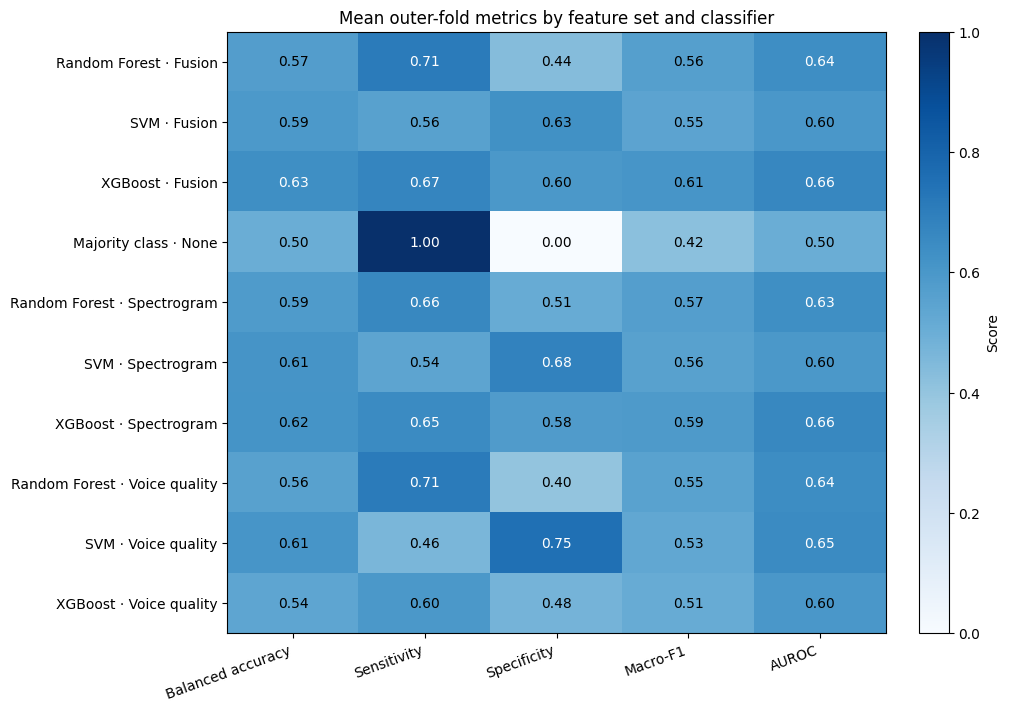

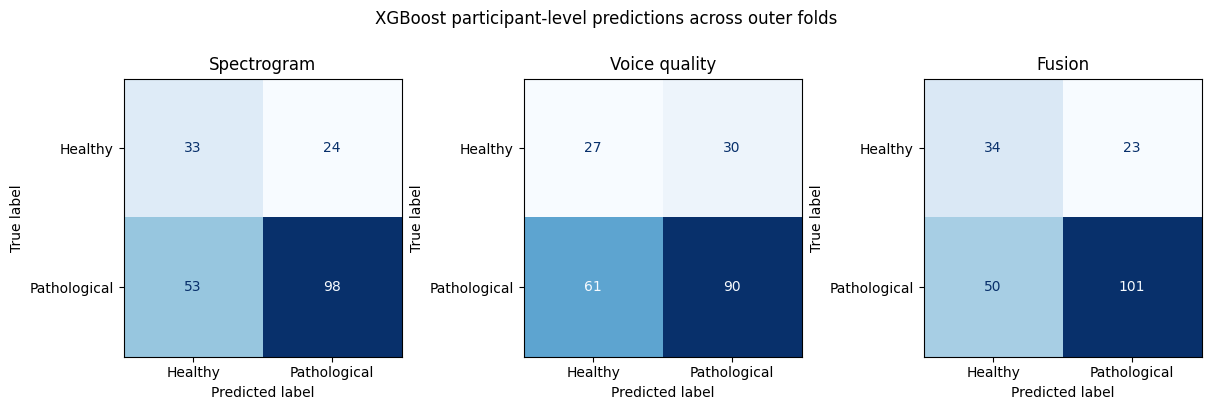

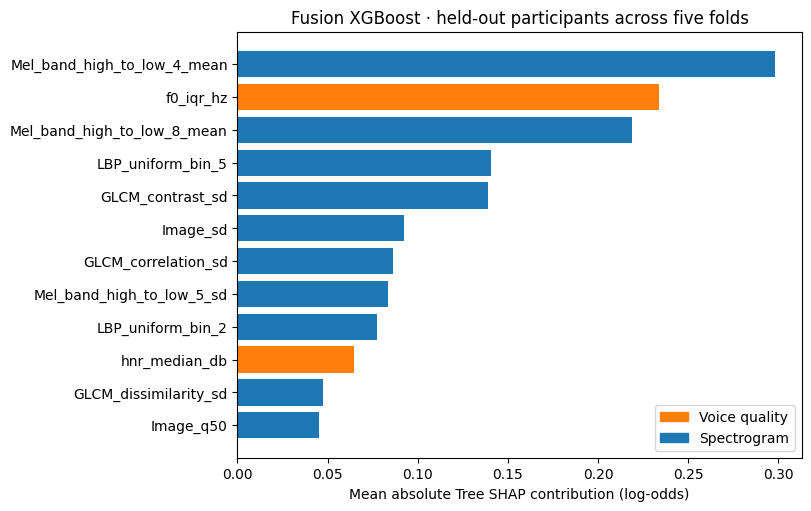

In [ ]:
summary_metrics = ['Accuracy', 'Balanced accuracy', 'Sensitivity', 'Specificity',
                   'Macro-F1', 'MCC', 'AUROC', 'Average precision']
cv_summary = fold_results.groupby(['Features', 'Model'])[summary_metrics].mean()
cv_spread = fold_results.groupby(['Features', 'Model'])[summary_metrics].std()
cv_summary.to_csv(OUT / 'nested_cv_mean_metrics.csv')
cv_spread.to_csv(OUT / 'nested_cv_fold_sd.csv')

display(cv_summary.round(3))
print('The table averages metrics over the five outer folds.')
print('Fold standard deviations are saved separately as descriptive variability.')

view_metrics = ['Balanced accuracy', 'Sensitivity', 'Specificity', 'Macro-F1', 'AUROC']
plot_data = cv_summary[view_metrics]
fig, ax = plt.subplots(figsize=(10, 7), layout='constrained')
image = ax.imshow(plot_data, cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(view_metrics)), view_metrics, rotation=20, ha='right')
ax.set_yticks(range(len(plot_data)), [f'{model} · {features}' for features, model in plot_data.index])
for row, values in enumerate(plot_data.to_numpy()):
    for column, value in enumerate(values):
        ax.text(column, row, f'{value:.2f}', ha='center', va='center',
                color='white' if value > 0.63 else 'black')
ax.set_title('Mean outer-fold metrics by feature set and classifier')
fig.colorbar(image, ax=ax, label='Score')
fig.savefig(OUT / 'nested_cv_comparison.png', dpi=300)
plt.show()

fig, axes = plt.subplots(1, len(feature_sets), figsize=(12, 4), layout='constrained')
xgb_predictions = oof_predictions[oof_predictions.Model == 'XGBoost']
for ax, feature_set in zip(axes, feature_sets):
    subset = xgb_predictions[xgb_predictions.Features == feature_set]
    ConfusionMatrixDisplay.from_predictions(
        subset['True label'], subset.Prediction, labels=[0, 1],
        display_labels=['Healthy', 'Pathological'], colorbar=False, cmap='Blues', ax=ax,
    )
    ax.set_title(feature_set)
fig.suptitle('XGBoost participant-level predictions across outer folds')
fig.savefig(OUT / 'nested_cv_xgboost_confusion.png', dpi=300)
plt.show()

# Each contribution comes from the fitted outer-fold model for that participant.
shap_rank = oof_shap[feature_sets['Fusion']].abs().mean().sort_values(ascending=False)
shap_rank.rename('Mean absolute Tree SHAP (log-odds)').to_csv(
    OUT / 'nested_cv_fusion_xgboost_shap_ranking.csv')
top = shap_rank.head(12).sort_values()
fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
ax.barh(top.index, top.to_numpy(), color=['tab:orange' if name in quality_names else 'tab:blue'
                                        for name in top.index])
ax.set(xlabel='Mean absolute Tree SHAP contribution (log-odds)',
       title='Fusion XGBoost · held-out participants across five folds')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='tab:orange', label='Voice quality'),
                   Patch(color='tab:blue', label='Spectrogram')], loc='lower right')
fig.savefig(OUT / 'nested_cv_fusion_xgboost_shap.png', dpi=300)
plt.show()

## 18. Compact phonation SVM and CPU benchmark

This experiment keeps time on a fixed 10 ms frame grid. A 64 ms Hann window is used for the spectral and autocorrelation estimates. A relative energy threshold trims the outer quiet regions and retains pauses inside the active interval. A recording is represented by nine numbers.

| Descriptor group | Measurements |
|---|---|
| Periodicity | 10th percentile of normalized autocorrelation peak strength, 90th percentile of adjacent-frame change, fraction of frames below the voicing criterion |
| Pitch variability | Interquartile range in semitones, 90th percentile of changes between adjacent voiced frames |
| Harmonic organization | Median fraction of band energy near estimated pitch harmonics in the 500–1,500 Hz and 1,500–3,800 Hz bands |
| Level and spectral change | 90th percentile of adjacent-frame level changes and log-Mel spectral flux |

The classifier is an RBF SVM with inverse-frequency class weights. Imputation, scaling and selection of the regularization parameter use only the training data in each split. The compact model uses the same participant folds as Section 17 and generates one prediction per held-out participant. For repeated recordings, the evaluation aggregates per-descriptor medians within participants.

This is an exploratory model developed while reviewing results on VOICED. Use a separate, independent cohort for a confirmatory comparison. Report the absolute percentage-point gain and the relative percentage gain separately, alongside specificity and macro-F1. The speed benchmark times both pipelines on the same recordings, with one CPU thread, after warm-up. It includes decoding, feature extraction and prediction. Serialized size covers the fitted preprocessing and classifier; the libraries and feature-extraction source are separate. Median-replacement explanations describe changes in the fitted SVM's decision margin.

In [ ]:
from time import perf_counter
from numpy.lib.stride_tricks import sliding_window_view
from scipy import fft, signal as scipy_signal

PHONATION_SR = 8000
FRAME_SAMPLES = 512
HOP_SAMPLES = 80
FFT_SAMPLES = 1024
TINY = 1e-10
TAPER = scipy_signal.windows.hann(FRAME_SAMPLES, sym=False)
FREQUENCIES = fft.rfftfreq(FFT_SAMPLES, 1 / PHONATION_SR)
PITCH_LAGS = np.arange(round(PHONATION_SR / 450), round(PHONATION_SR / 60) + 1)
TAPER_CORRELATION = fft.irfft(np.abs(fft.rfft(TAPER, n=FFT_SAMPLES)) ** 2, n=FFT_SAMPLES)
TAPER_CORRECTION = TAPER_CORRELATION[PITCH_LAGS] / TAPER_CORRELATION[0]

frequency_mels = 2595 * np.log10(1 + FREQUENCIES / 700)
mel_edges = np.linspace(2595 * np.log10(1 + 60 / 700), frequency_mels[-1], 34)
mel_widths = np.diff(mel_edges)
MEL_WEIGHTS = np.maximum(0, np.minimum(
    (frequency_mels - mel_edges[:-2, None]) / mel_widths[:-1, None],
    (mel_edges[2:, None] - frequency_mels) / mel_widths[1:, None],
))
MEL_WEIGHTS /= MEL_WEIGHTS.sum(axis=1, keepdims=True)


def percentile_or_nan(values, percentile):
    return float(np.percentile(values, percentile)) if values.size else np.nan


def compact_phonation_features(audio, sr):
    """Summarize harmonic organization and changes during one sustained vowel."""
    audio = np.asarray(audio, dtype=np.float64)
    if sr != PHONATION_SR or audio.ndim != 1 or len(audio) < FRAME_SAMPLES:
        raise ValueError('Provide mono audio at 8 kHz with at least 64 ms of samples.')
    audio = audio - np.mean(audio)
    peak = np.max(np.abs(audio))
    if not np.isfinite(peak) or peak < TINY:
        raise ValueError('The recording needs a finite, measurable audio signal.')
    frames = sliding_window_view(audio / peak, FRAME_SAMPLES)[::HOP_SAMPLES]
    rms = np.sqrt(np.mean(frames ** 2, axis=1))
    active = np.flatnonzero(rms >= np.max(rms) * 10 ** (-30 / 20))
    active_interval = slice(active[0], active[-1] + 1)
    frames, rms = frames[active_interval], rms[active_interval]
    level = 20 * np.log10(np.maximum(rms, TINY))
    level -= np.max(level)

    power = np.abs(fft.rfft(frames * TAPER, n=FFT_SAMPLES, axis=1)) ** 2
    mel_power = power @ MEL_WEIGHTS.T
    mel_db = 10 * np.log10(np.maximum(mel_power / np.max(mel_power), TINY))
    mel_changes = np.diff(np.clip(mel_db, -80, 0), axis=0)
    spectral_flux = np.sqrt(np.mean(mel_changes ** 2, axis=1))

    centered = (frames - frames.mean(axis=1, keepdims=True)) * TAPER
    acf = fft.irfft(np.abs(fft.rfft(centered, n=FFT_SAMPLES, axis=1)) ** 2,
                    n=FFT_SAMPLES, axis=1)
    correlation = acf[:, PITCH_LAGS] / np.maximum(acf[:, :1], TINY)
    correlation = np.clip(correlation / TAPER_CORRECTION, 0, 1)
    interior_peaks = ((correlation[:, 1:-1] >= correlation[:, :-2]) &
                      (correlation[:, 1:-1] > correlation[:, 2:]))
    is_peak = np.pad(interior_peaks, ((0, 0), (1, 1)))
    peak_strengths = np.where(is_peak, correlation, 0)
    best_strength = peak_strengths.max(axis=1, keepdims=True)
    first_peak = np.argmax(peak_strengths >= 0.90 * best_strength, axis=1)
    frame_ids = np.arange(len(frames))
    periodicity = peak_strengths[frame_ids, first_peak]
    voiced = (periodicity >= 0.30) & (level >= -30)

    center = np.clip(first_peak, 1, len(PITCH_LAGS) - 2)
    left, middle, right = (correlation[frame_ids, center + d] for d in (-1, 0, 1))
    curvature = left - 2 * middle + right
    offset = np.divide(0.5 * (left - right), curvature, out=np.zeros_like(middle),
                       where=np.abs(curvature) > TINY)
    pitch_hz = sr / (PITCH_LAGS[first_peak] + np.clip(offset, -0.5, 0.5))
    semitones = 12 * np.log2(pitch_hz)
    pitch_changes = np.abs(np.diff(semitones))[voiced[:-1] & voiced[1:]]

    harmonic_order = FREQUENCIES[None, :] / pitch_hz[:, None]
    harmonic_distance = np.abs(FREQUENCIES[None, :] -
                               np.round(harmonic_order) * pitch_hz[:, None])
    near_harmonic = (harmonic_distance <= 1.5 * sr / FRAME_SAMPLES) & (harmonic_order >= 0.5)

    def harmonic_concentration(low, high):
        band = (FREQUENCIES >= low) & (FREQUENCIES < high)
        band_power = power[:, band]
        concentration = ((band_power * near_harmonic[:, band]).sum(axis=1) /
                         np.maximum(band_power.sum(axis=1), TINY))
        return percentile_or_nan(concentration[voiced], 50)

    pitch_iqr = percentile_or_nan(semitones[voiced], 75) - percentile_or_nan(semitones[voiced], 25)
    return {
        'periodicity_p10': percentile_or_nan(periodicity, 10),
        'periodicity_change_p90': percentile_or_nan(np.abs(np.diff(periodicity)), 90),
        'pitch_iqr_semitones': pitch_iqr,
        'pitch_change_p90_semitones': percentile_or_nan(pitch_changes, 90),
        'harmonic_concentration_mid': harmonic_concentration(500, 1500),
        'harmonic_concentration_high': harmonic_concentration(1500, 3800),
        'level_change_p90_db': percentile_or_nan(np.abs(np.diff(level)), 90),
        'unvoiced_frame_fraction': float(1 - voiced.mean()),
        'spectral_flux_p90': percentile_or_nan(spectral_flux, 90),
    }


phonation_rows = []
for row in manifest.itertuples(index=False):
    phonation_rows.append({'subject_id': str(row.subject_id), 'label': row.label,
                           **compact_phonation_features(*load_voice(row))})
phonation_records = pd.DataFrame(phonation_rows)
phonation_subjects = phonation_records.groupby(['subject_id', 'label'], as_index=False).median()
assert np.array_equal(phonation_subjects.subject_id.to_numpy(dtype=str), subject_ids)
assert np.array_equal(phonation_subjects.label.to_numpy(dtype=int), subject_y)
phonation_names = phonation_subjects.columns[2:].tolist()
phonation_x = phonation_subjects[phonation_names].to_numpy(dtype=float)
phonation_subjects.to_csv(OUT / 'compact_phonation_features.csv', index=False)

Accuracy  Balanced accuracy  \
Features                   Model                                         
Nine phonation descriptors Phonation SVM     0.5672             0.6521   
Fusion                     XGBoost           0.6492             0.6332   
Spectrogram                XGBoost           0.6302             0.6156   
                           SVM               0.5818             0.6113   
Voice quality              SVM               0.5437             0.6077   
Fusion                     SVM               0.5770             0.5906   
Spectrogram                Random Forest     0.6204             0.5855   
Fusion                     Random Forest     0.6346             0.5724   
Voice quality              Random Forest     0.6251             0.5554   
                           XGBoost           0.5627             0.5362   
None                       Majority class    0.7260             0.5000   

                                           Sensitivity  Specificity  Macro-F1  \
Features                   Model                                                
Nine phonation descriptors Phonation SVM        0.4632       0.8409    0.5610   
Fusion                     XGBoost              0.6695       0.5970    0.6064   
Spectrogram                XGBoost              0.6495       0.5818    0.5884   
                           SVM                  0.5424       0.6803    0.5572   
Voice quality              SVM                  0.4639       0.7515    0.5294   
Fusion                     SVM                  0.5555       0.6258    0.5457   
Spectrogram                Random Forest        0.6619       0.5091    0.5693   
Fusion                     Random Forest        0.7084       0.4364    0.5638   
Voice quality              Random Forest        0.7092       0.4015    0.5517   
                           XGBoost              0.5966       0.4758    0.5112   
None                       Majority class       1.0000       0.0000    0.4206   

                                              MCC   AUROC  
Features                   Model                           
Nine phonation descriptors Phonation SVM   0.2822  0.6643  
Fusion                     XGBoost         0.2432  0.6644  
Spectrogram                XGBoost         0.2101  0.6615  
                           SVM             0.2055  0.5950  
Voice quality              SVM             0.1953  0.6490  
Fusion                     SVM             0.1669  0.5986  
Spectrogram                Random Forest   0.1571  0.6348  
Fusion                     Random Forest   0.1353  0.6369  
Voice quality              Random Forest   0.1080  0.6428  
                           XGBoost         0.0654  0.5996  
None                       Majority class  0.0000  0.5000

Mean paired fold differences versus fusion XGBoost (absolute metric units):


,0
Accuracy,-0.0820
Balanced accuracy,0.0189
Sensitivity,-0.2062
Specificity,0.2439
Macro-F1,-0.0454
MCC,0.0390
AUROC,-0.0000


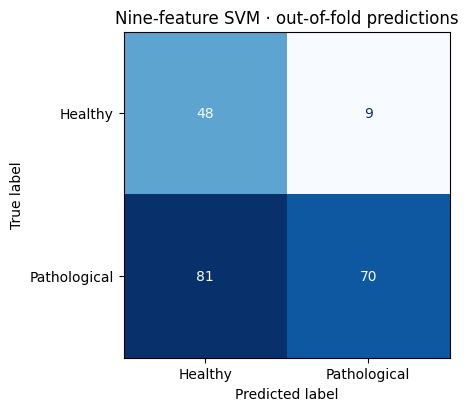

In [ ]:
from threadpoolctl import threadpool_limits

COMPACT_MODEL = 'Phonation SVM'
compact_fold_rows = []
compact_oof = []
compact_fold_models = {}
C_GRID = [0.01, 0.1, 1, 10]
for fold, (fit_idx, eval_idx) in enumerate(outer_splits, start=1):
    compact_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scale', StandardScaler()),
        ('model', SVC(kernel='rbf', class_weight='balanced')),
    ])
    search = GridSearchCV(
        compact_pipeline, {'model__C': C_GRID},
        cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED + fold),
        scoring='balanced_accuracy', n_jobs=1, error_score='raise',
    )
    search.fit(phonation_x[fit_idx], subject_y[fit_idx])
    fitted_fold = search.best_estimator_
    compact_fold_models[fold] = fitted_fold
    held_out = phonation_x[eval_idx]
    predicted = fitted_fold.predict(held_out)
    scores = fitted_fold.decision_function(held_out)
    labels = subject_y[eval_idx]
    metrics = binary_metrics(labels, predicted)
    metrics['AUROC'] = roc_auc_score(labels, scores)
    compact_fold_rows.append({'Fold': fold, 'Model': COMPACT_MODEL, 'Features': 'Nine phonation descriptors',
                              'Parameters': json.dumps(search.best_params_), **metrics})
    compact_oof.append(pd.DataFrame({'Fold': fold, 'subject_id': subject_ids[eval_idx],
                                     'True label': labels, 'Prediction': predicted,
                                     'Pathology score': scores}))

compact_fold_results = pd.DataFrame(compact_fold_rows)
compact_predictions = pd.concat(compact_oof, ignore_index=True)
assert len(compact_predictions) == len(subject_ids) and compact_predictions.subject_id.is_unique
compact_fold_results.to_csv(OUT / 'compact_phonation_fold_metrics.csv', index=False)
compact_predictions.to_csv(OUT / 'compact_phonation_oof_predictions.csv', index=False)
comparison_columns = ['Accuracy', 'Balanced accuracy', 'Sensitivity', 'Specificity', 'Macro-F1', 'MCC', 'AUROC']
compact_comparison = (
    pd.concat([fold_results, compact_fold_results], ignore_index=True)
    .groupby(['Features', 'Model'])[comparison_columns].mean()
    .sort_values('Balanced accuracy', ascending=False)
)
compact_comparison.to_csv(OUT / 'compact_phonation_comparison.csv')
display(compact_comparison.round(4))

fused_reference = fold_results[(fold_results.Features == 'Fusion') & (fold_results.Model == 'XGBoost')]
paired_folds = compact_fold_results.set_index('Fold')[comparison_columns].subtract(
    fused_reference.set_index('Fold')[comparison_columns])
paired_folds.to_csv(OUT / 'compact_phonation_paired_fold_differences.csv')
print('Mean paired fold differences versus fusion XGBoost (absolute metric units):')
display(paired_folds.mean().round(4))

fig, ax = plt.subplots(figsize=(5, 4), layout='constrained')
ConfusionMatrixDisplay.from_predictions(
    compact_predictions['True label'], compact_predictions.Prediction,
    labels=[0, 1], display_labels=['Healthy', 'Pathological'], colorbar=False, cmap='Blues', ax=ax,
)
ax.set_title('Nine-feature SVM · out-of-fold predictions')
fig.savefig(OUT / 'compact_phonation_confusion.png', dpi=300)
plt.show()

# Replace one descriptor at a time with its outer-training median and re-score each held-out sample.
replacement_rows = []
for fold, (fit_idx, eval_idx) in enumerate(outer_splits, start=1):
    fitted_fold = compact_fold_models[fold]
    features = phonation_x[eval_idx]
    scores = fitted_fold.decision_function(features)
    training_medians = fitted_fold.named_steps['impute'].statistics_
    for j, name in enumerate(phonation_names):
        perturbed = features.copy()
        perturbed[:, j] = training_medians[j]
        change = scores - fitted_fold.decision_function(perturbed)
        replacement_rows.append(pd.DataFrame({'Fold': fold, 'subject_id': subject_ids[eval_idx],
                                              'Feature': name, 'Margin difference': change}))
replacement_effects = pd.concat(replacement_rows, ignore_index=True)
replacement_effects.to_csv(OUT / 'compact_phonation_descriptor_replacement.csv', index=False)

In [ ]:
import io
import platform

# Benchmark the first outer fold on the same 20 held-out recordings for both pipelines.
# Include resampling/decoding, feature extraction, and scoring. Exclude rendering and model loading.
first_fit, first_eval = outer_splits[0]
first_fold_people = set(subject_ids[first_eval])
benchmark_rows = [row for row in manifest.itertuples(index=False)
                  if str(row.subject_id) in first_fold_people][:20]

fusion_columns = feature_sets['Fusion']
fusion_first = fused_reference.loc[fused_reference.Fold == 1].iloc[0]
fusion_params = json.loads(fusion_first.Parameters)
fusion_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('model', clone(nested_models['XGBoost'][0])),
]).set_params(**fusion_params)
fusion_pipeline.fit(subject_features[fusion_columns].to_numpy(dtype=float)[first_fit],
                    subject_y[first_fit])
compact_first = compact_fold_models[1]


def score_compact_record(row):
    audio, sr = load_voice(row)
    features = compact_phonation_features(audio, sr)
    return compact_first.decision_function([[features[name] for name in phonation_names]])


def score_fusion_record(row):
    audio, sr = load_voice(row)
    image = audio_to_spectrogram_image(audio, sr)
    descriptors = image_features(image, include_hog=False)
    voice_measures = voice_quality_features(audio, sr)
    features = np.r_[descriptors, [voice_measures[name] for name in quality_names]]
    return fusion_pipeline.predict_proba(features.reshape(1, -1))[:, 1]


runtime_rows = []
with threadpool_limits(limits=1):
    for name, model, score_record, feature_count in (
        (COMPACT_MODEL, compact_first, score_compact_record, len(phonation_names)),
        ('Fusion XGBoost', fusion_pipeline, score_fusion_record, len(fusion_columns)),
    ):
        score_record(benchmark_rows[0])
        duration_ms = []
        for row in benchmark_rows:
            start = perf_counter()
            score_record(row)
            duration_ms.append(1000 * (perf_counter() - start))
        storage = io.BytesIO()
        joblib.dump(model, storage, compress=0)
        runtime_rows.append({
            'Model': name, 'Features': feature_count, 'Timed recordings': len(duration_ms),
            'Median audio-to-score ms': np.median(duration_ms),
            'P90 audio-to-score ms': np.percentile(duration_ms, 90),
            'Serialized pipeline bytes': storage.tell(),
            'CPU architecture': platform.machine(),
        })
runtime_table = pd.DataFrame(runtime_rows)
runtime_table.to_csv(OUT / 'compact_phonation_cpu_benchmark.csv', index=False)
display(runtime_table.round(2))

,Model,Features,Timed recordings,Median audio-to-score ms,P90 audio-to-score ms,Serialized pipeline bytes,CPU architecture
0,Phonation SVM,9,20,12.89,16.27,16253,x86_64
1,Fusion XGBoost,53,20,354.78,394.75,133590,x86_64


## 19. Compare a small spectrogram CNN with two CNN–SVM pipelines

This section uses PyTorch on CPU. If the runtime cannot import PyTorch, run `%pip install torch` in a separate cell. Run Sections 1–18 first.

| Model | Classifier input |
|---|---|
| CNN only | A 64 × 64 log-Mel spectrogram, classified by the CNN's linear output layer |
| CNN + SVM | The same CNN's 16 learned features, classified by a class-weighted RBF SVM |
| CNN + phonation + SVM | The 16 learned features plus the nine phonation descriptors, classified by a class-weighted RBF SVM |

The encoder uses three convolutional blocks. Pooling retains four frequency bands and averages over time. Within each outer fold, the CNN trains for 30 epochs using training participants, class and speaker weights, and narrow time masking. The CNN is frozen while both SVMs are fitted. The epoch count and SVM configuration are fixed for this comparison. Scaling and imputation are fitted within each training fold. Repeated recordings are combined by taking medians for each participant. These settings use the same outer participants as the fusion XGBoost and phonation SVM comparisons.

The benchmark measures one-thread CPU audio-to-score latency on the same first-fold recordings used in Section 18. The serialized size covers CNN weights and the fitted classifier where applicable. The exploratory design was developed on VOICED. An independent cohort is needed to confirm a gain.

In [ ]:
import io
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

CNN_DEVICE = torch.device('cpu')
CNN_SIZE = (64, 64)
CNN_EPOCHS = 30
CNN_EMBEDDING = 16
CNN_BATCH = 32
HYBRID_NAMES = ('CNN only', 'CNN + SVM', 'CNN + phonation + SVM')


def cnn_pixels(image):
    pixels = np.asarray(image.convert('L').resize(CNN_SIZE, Image.Resampling.BILINEAR),
                        dtype=np.float32)
    return pixels[None] / 255.0


class SpectrogramCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=5, padding=2), nn.BatchNorm2d(8), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 24, kernel_size=3, padding=1), nn.BatchNorm2d(24), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.embedding = nn.Sequential(nn.Flatten(), nn.Linear(96, CNN_EMBEDDING), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(p=0.2), nn.Linear(CNN_EMBEDDING, 1))

    def encode(self, images):
        maps = self.conv(images)
        # Pool over time while retaining four coarse Mel-frequency bands.
        pooled = nn.functional.adaptive_avg_pool2d(maps, (4, 1))
        return self.embedding(pooled)

    def forward(self, images):
        return self.head(self.encode(images)).squeeze(1)


def fit_spectrogram_cnn(images, labels, speaker_weights, seed):
    torch.manual_seed(seed)
    shuffle_rng = torch.Generator().manual_seed(seed)
    aug_rng = np.random.default_rng(seed)
    cnn = SpectrogramCNN().to(CNN_DEVICE)
    optimizer = torch.optim.AdamW(cnn.parameters(), lr=0.001, weight_decay=0.01)
    train_data = TensorDataset(torch.from_numpy(images),
                               torch.tensor(labels, dtype=torch.float32),
                               torch.tensor(speaker_weights, dtype=torch.float32))
    train_batches = DataLoader(train_data, batch_size=CNN_BATCH, shuffle=True, generator=shuffle_rng)
    cnn.train()
    for _ in range(CNN_EPOCHS):
        for batch, target, weights in train_batches:
            batch = batch.to(CNN_DEVICE)
            target, weights = target.to(CNN_DEVICE), weights.to(CNN_DEVICE)
            # One narrow, training-only time mask preserves the frequency bands.
            width = int(aug_rng.integers(0, 6))
            if width:
                start = int(aug_rng.integers(0, batch.shape[-1] - width + 1))
                batch[..., start:start + width] = 0
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.binary_cross_entropy_with_logits(cnn(batch), target, reduction='none')
            (loss * weights).mean().backward()
            optimizer.step()
    return cnn.eval()


@torch.inference_mode()
def cnn_outputs(cnn, images):
    embeddings, logits = [], []
    for batch in torch.from_numpy(images).split(CNN_BATCH):
        embedding = cnn.encode(batch.to(CNN_DEVICE))
        embeddings.append(embedding.cpu().numpy())
        logits.append(cnn.head(embedding).squeeze(1).cpu().numpy())
    return np.concatenate(embeddings), np.concatenate(logits)


def subject_medians(values, recording_subjects, participant_order):
    by_subject = pd.DataFrame(values, index=pd.Index(recording_subjects, name='subject'))
    return by_subject.groupby(level=0).median().loc[participant_order].to_numpy()


def fit_hybrid_svm(features, labels):
    # A fixed head configuration avoids choosing hyperparameters on the outer folds.
    return Pipeline([
        ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scale', StandardScaler()),
        ('model', SVC(C=1.0, kernel='rbf', class_weight='balanced')),
    ]).fit(features, labels)


cnn_record_subjects = image_manifest.subject_id.to_numpy(dtype=str)
cnn_record_labels = image_manifest.label.to_numpy(dtype=int)
cnn_inputs = []
for path in image_manifest.image_path:
    with Image.open(path) as image:
        cnn_inputs.append(cnn_pixels(image))
cnn_inputs = np.stack(cnn_inputs)

cnn_rows, cnn_oof_rows = [], []
cnn_benchmark_models = {}
cnn_parameter_count = sum(parameter.numel() for parameter in SpectrogramCNN().parameters())
print(f'Trainable CNN parameters: {cnn_parameter_count:,}', flush=True)
previous_threads = torch.get_num_threads()
torch.set_num_threads(2)
try:
    for fold, (fit_idx, eval_idx) in enumerate(outer_splits, start=1):
        train_subjects, eval_subjects = subject_ids[fit_idx], subject_ids[eval_idx]
        fit_y, eval_y = subject_y[fit_idx], subject_y[eval_idx]
        fit_rows = np.isin(cnn_record_subjects, train_subjects)
        eval_rows = np.isin(cnn_record_subjects, eval_subjects)
        assert set(cnn_record_subjects[fit_rows]).isdisjoint(cnn_record_subjects[eval_rows])
        recording_subjects = cnn_record_subjects[fit_rows]
        recordings_per_subject = pd.Series(recording_subjects).value_counts()
        class_counts = np.bincount(fit_y)
        weights = 1.0 / (class_counts[cnn_record_labels[fit_rows]] *
                         recordings_per_subject.loc[recording_subjects].to_numpy())
        weights /= weights.mean()
        cnn = fit_spectrogram_cnn(cnn_inputs[fit_rows], cnn_record_labels[fit_rows],
                                  weights, seed=SEED + fold)
        train_embeddings, _ = cnn_outputs(cnn, cnn_inputs[fit_rows])
        eval_embeddings, eval_logits = cnn_outputs(cnn, cnn_inputs[eval_rows])
        train_z = subject_medians(train_embeddings, recording_subjects, train_subjects)
        eval_z = subject_medians(eval_embeddings, cnn_record_subjects[eval_rows], eval_subjects)
        direct_scores = subject_medians(eval_logits[:, None], cnn_record_subjects[eval_rows],
                                        eval_subjects).ravel()

        image_head = fit_hybrid_svm(train_z, fit_y)
        train_fused = np.column_stack((train_z, phonation_x[fit_idx]))
        eval_fused = np.column_stack((eval_z, phonation_x[eval_idx]))
        fused_head = fit_hybrid_svm(train_fused, fit_y)
        fold_scores = {
            'CNN only': direct_scores,
            'CNN + SVM': image_head.decision_function(eval_z),
            'CNN + phonation + SVM': fused_head.decision_function(eval_fused),
        }
        fold_predictions = {
            'CNN only': (direct_scores >= 0).astype(int),
            'CNN + SVM': image_head.predict(eval_z),
            'CNN + phonation + SVM': fused_head.predict(eval_fused),
        }
        for name in HYBRID_NAMES:
            scores = fold_scores[name]
            predicted = fold_predictions[name]
            metrics = binary_metrics(eval_y, predicted)
            metrics['AUROC'] = roc_auc_score(eval_y, scores)
            cnn_rows.append({'Fold': fold, 'Model': name, **metrics})
            cnn_oof_rows.append(pd.DataFrame({
                'Fold': fold, 'Model': name, 'subject_id': eval_subjects, 'True label': eval_y,
                'Prediction': predicted, 'Pathology score': scores,
            }))
        if fold == 1:
            cnn_benchmark_models = {'encoder': cnn, 'image_head': image_head, 'fused_head': fused_head}
        print(f'Completed CNN and hybrid training for outer fold {fold}/{len(outer_splits)}', flush=True)
finally:
    torch.set_num_threads(previous_threads)

cnn_fold_results = pd.DataFrame(cnn_rows)
cnn_oof_predictions = pd.concat(cnn_oof_rows, ignore_index=True)
assert not cnn_oof_predictions.duplicated(['Model', 'subject_id']).any()
assert cnn_oof_predictions.groupby('Model').subject_id.nunique().eq(len(subject_ids)).all()
cnn_fold_results.to_csv(OUT / 'hybrid_cnn_fold_metrics.csv', index=False)
cnn_oof_predictions.to_csv(OUT / 'hybrid_cnn_oof_predictions.csv', index=False)

Trainable CNN parameters: 6,521
Completed CNN and hybrid training for outer fold 1/5
Completed CNN and hybrid training for outer fold 2/5
Completed CNN and hybrid training for outer fold 3/5
Completed CNN and hybrid training for outer fold 4/5
Completed CNN and hybrid training for outer fold 5/5


,Accuracy,Balanced accuracy,Sensitivity,Specificity,Macro-F1,MCC,AUROC
Model,,,,,,,
Phonation SVM,0.5672,0.6521,0.4632,0.8409,0.5610,0.2822,0.6643
Fusion XGBoost,0.6492,0.6332,0.6695,0.5970,0.6064,0.2432,0.6644
CNN only,0.5396,0.5912,0.4703,0.7121,0.5149,0.1827,0.6278
CNN + SVM,0.6012,0.5665,0.6422,0.4909,0.5486,0.1214,0.5832
CNN + phonation + SVM,0.5772,0.5441,0.6155,0.4727,0.5239,0.0809,0.5599


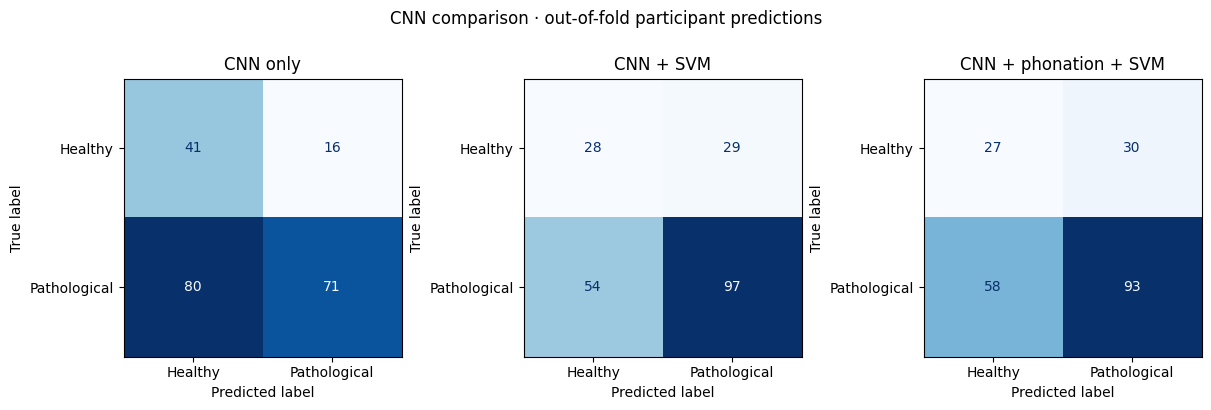

,Model,Features,Timed recordings,Median audio-to-score ms,P90 audio-to-score ms,Serialized pipeline bytes,CPU architecture
0,Phonation SVM,9,20,12.89,16.27,16253,x86_64
1,Fusion XGBoost,53,20,354.78,394.75,133590,x86_64
2,CNN only,16,20,5.92,6.33,34392,x86_64
3,CNN + SVM,16,20,6.22,6.40,48021,x86_64
4,CNN + phonation + SVM,25,20,18.05,19.22,55141,x86_64


In [ ]:
cnn_reference = fused_reference.assign(Model='Fusion XGBoost')
cnn_comparison = (
    pd.concat([cnn_reference, compact_fold_results, cnn_fold_results], ignore_index=True)
    .groupby('Model')[comparison_columns].mean()
    .sort_values('Balanced accuracy', ascending=False)
)
cnn_comparison.to_csv(OUT / 'hybrid_cnn_comparison.csv')
display(cnn_comparison.round(4))

paired_cnn = cnn_fold_results.pivot(index='Fold', columns='Model', values='Balanced accuracy')
paired_cnn['Fusion XGBoost'] = cnn_reference.set_index('Fold')['Balanced accuracy']
paired_cnn[COMPACT_MODEL] = compact_fold_results.set_index('Fold')['Balanced accuracy']
paired_cnn.to_csv(OUT / 'hybrid_cnn_paired_balanced_accuracy.csv')

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
for ax, name in zip(axes, HYBRID_NAMES):
    subset = cnn_oof_predictions.loc[cnn_oof_predictions.Model == name]
    ConfusionMatrixDisplay.from_predictions(
        subset['True label'], subset.Prediction, labels=[0, 1],
        display_labels=['Healthy', 'Pathological'], colorbar=False, cmap='Blues', ax=ax,
    )
    ax.set_title(name)
fig.suptitle('CNN comparison · out-of-fold participant predictions')
fig.savefig(OUT / 'hybrid_cnn_confusion.png', dpi=300)
plt.show()

bench_encoder = cnn_benchmark_models['encoder']
bench_image_head = cnn_benchmark_models['image_head']
bench_fused_head = cnn_benchmark_models['fused_head']


def score_cnn_record(row, model_name):
    audio, sr = load_voice(row)
    pixels = cnn_pixels(audio_to_spectrogram_image(audio, sr))[None]
    embedding, logits = cnn_outputs(bench_encoder, pixels)
    if model_name == 'CNN only':
        return logits
    if model_name == 'CNN + SVM':
        return bench_image_head.decision_function(embedding)
    phonation = compact_phonation_features(audio, sr)
    combined = np.r_[embedding.ravel(), [phonation[name] for name in phonation_names]]
    return bench_fused_head.decision_function(combined.reshape(1, -1))


cnn_state = io.BytesIO()
torch.save(bench_encoder.state_dict(), cnn_state)
head_by_name = {'CNN + SVM': bench_image_head, 'CNN + phonation + SVM': bench_fused_head}
cnn_runtime = []
previous_threads = torch.get_num_threads()
torch.set_num_threads(1)
try:
    with threadpool_limits(limits=1):
        for model_name in HYBRID_NAMES:
            score_cnn_record(benchmark_rows[0], model_name)
            durations = []
            for row in benchmark_rows:
                start = perf_counter()
                score_cnn_record(row, model_name)
                durations.append(1000 * (perf_counter() - start))
            classifier_state = io.BytesIO()
            if model_name in head_by_name:
                joblib.dump(head_by_name[model_name], classifier_state, compress=0)
            cnn_runtime.append({
                'Model': model_name, 'Timed recordings': len(durations),
                'Features': {'CNN only': CNN_EMBEDDING, 'CNN + SVM': CNN_EMBEDDING,
                             'CNN + phonation + SVM': CNN_EMBEDDING + len(phonation_names)}[model_name],
                'Median audio-to-score ms': np.median(durations),
                'P90 audio-to-score ms': np.percentile(durations, 90),
                'Serialized pipeline bytes': cnn_state.tell() + classifier_state.tell(),
                'CPU architecture': platform.machine(),
            })
finally:
    torch.set_num_threads(previous_threads)
hybrid_runtime_table = pd.concat([runtime_table, pd.DataFrame(cnn_runtime)], ignore_index=True)
hybrid_runtime_table.to_csv(OUT / 'hybrid_cnn_cpu_benchmark.csv', index=False)
display(hybrid_runtime_table.round(2))

### Inspect what changes the hybrid prediction

Each example shows the effect of replacing a small spectrogram region with the training images' median pixels while holding the nine phonation descriptors fixed. The bar chart shows the effect of replacing each phonation descriptor with its training median while holding the spectrogram embedding fixed. Positive differences indicate support for the pathological-class decision margin relative to the replacement. The plots explain two held-out recordings from the first fold.

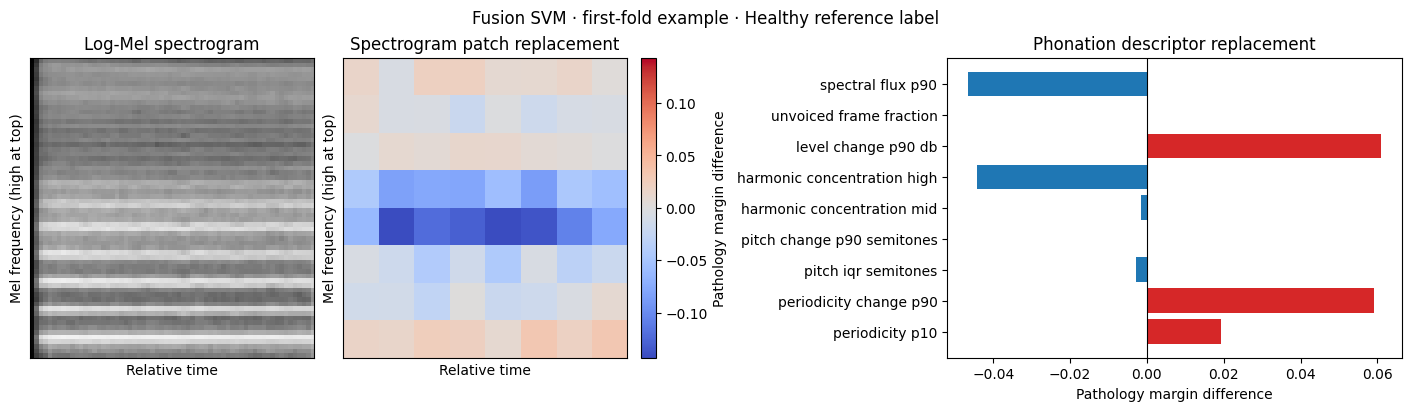

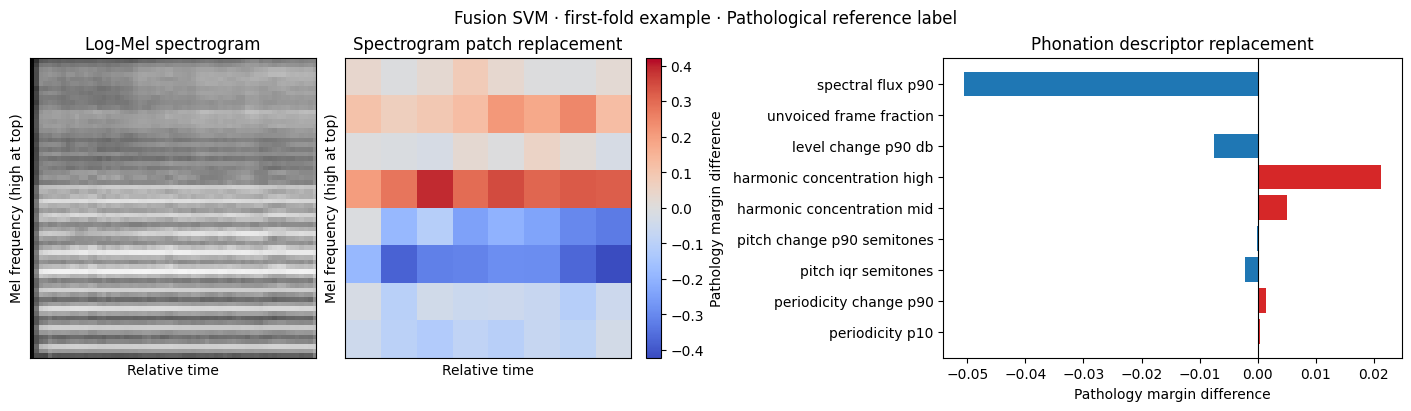

In [ ]:
# Explain the first recording from one held-out participant per class in outer fold 1.
first_fold_train, first_fold_test = outer_splits[0]
train_image_rows = np.isin(cnn_record_subjects, subject_ids[first_fold_train])
reference_pixels = np.median(cnn_inputs[train_image_rows], axis=0)
phonation_reference = bench_fused_head.named_steps['impute'].statistics_[-len(phonation_names):]
record_explanations = []

for true_class in (0, 1):
    first_subject = next(subject_ids[i] for i in first_fold_test if subject_y[i] == true_class)
    recording = int(np.flatnonzero(cnn_record_subjects == first_subject)[0])
    pixels = cnn_inputs[recording]
    subject_index = int(np.flatnonzero(subject_ids == first_subject)[0])
    descriptors = phonation_x[subject_index]
    participant_recordings = cnn_inputs[cnn_record_subjects == first_subject]
    if len(participant_recordings) != 1:
        # Score this recording separately when the evaluation aggregated several recordings.
        audio, sr = load_voice(manifest.iloc[recording])
        measures = compact_phonation_features(audio, sr)
        descriptors = np.array([measures[name] for name in phonation_names])
    embedding, _ = cnn_outputs(bench_encoder, pixels[None])
    fused = np.column_stack((embedding, descriptors[None]))
    margin = bench_fused_head.decision_function(fused)[0]

    grid = 8
    patch_size = CNN_SIZE[0] // grid
    masked = np.repeat(pixels[None], grid ** 2, axis=0)
    for index, image in enumerate(masked):
        row, column = divmod(index, grid)
        region = (slice(None), slice(row * patch_size, (row + 1) * patch_size),
                  slice(column * patch_size, (column + 1) * patch_size))
        image[region] = reference_pixels[region]
    masked_embeddings, _ = cnn_outputs(bench_encoder, masked)
    masked_fused = np.column_stack((masked_embeddings,
                                   np.broadcast_to(descriptors, (len(masked), len(descriptors)))))
    differences = (margin - bench_fused_head.decision_function(masked_fused)).reshape(grid, grid)

    replaced = np.repeat(fused, len(phonation_names), axis=0)
    acoustic_cols = CNN_EMBEDDING + np.arange(len(phonation_names))
    replaced[np.arange(len(phonation_names)), acoustic_cols] = phonation_reference
    descriptor_changes = margin - bench_fused_head.decision_function(replaced)
    record_explanations.append(pd.DataFrame({
        'subject_id': first_subject, 'Feature': phonation_names,
        'Pathology margin': margin, 'Margin difference': descriptor_changes,
    }))

    fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout='constrained',
                             gridspec_kw={'width_ratios': [1, 1, 1.6]})
    axes[0].imshow(pixels[0], cmap='gray', vmin=0, vmax=1, aspect='auto')
    axes[0].set_title('Log-Mel spectrogram')
    limit = max(float(np.abs(differences).max()), 1e-8)
    heatmap = axes[1].imshow(differences, cmap='coolwarm', vmin=-limit, vmax=limit, aspect='auto')
    axes[1].set_title('Spectrogram patch replacement')
    fig.colorbar(heatmap, ax=axes[1], label='Pathology margin difference')
    for ax in axes[:2]:
        ax.set(xticks=[], yticks=[], xlabel='Relative time', ylabel='Mel frequency (high at top)')
    axes[2].barh([name.replace('_', ' ') for name in phonation_names], descriptor_changes,
                 color=['tab:red' if value >= 0 else 'tab:blue' for value in descriptor_changes])
    axes[2].axvline(0, color='black', linewidth=0.8)
    axes[2].set(title='Phonation descriptor replacement', xlabel='Pathology margin difference')
    fig.suptitle(f'Fusion SVM · first-fold example · {LABEL_NAME[true_class]} reference label')
    fig.savefig(OUT / f'hybrid_cnn_explanation_class_{true_class}.png', dpi=300)
    plt.show()

pd.concat(record_explanations, ignore_index=True).to_csv(
    OUT / 'hybrid_cnn_phonation_explanations.csv', index=False)

## 20. Evaluate a frozen audio CNN and phonation features

[Google YAMNet v1](https://www.tensorflow.org/tutorials/audio/transfer_learning_audio) is a MobileNetV1 audio CNN trained on AudioSet. This experiment uses its [pinned ONNX conversion](https://huggingface.co/audiomagic/yamnet-onnx/tree/f25b741c2f0bdc6d7e6db24b5fddda23347dbafd), checks the file digest, and runs on CPU. The waveform is resampled from 8 to 16 kHz for the encoder. This preserves the source bandwidth. The encoder computes its own log-Mel representation and yields one 1,024-element embedding about every 0.48 seconds. The final padded window is omitted when a complete window is available.

| Configuration | Inputs |
|---|---|
| Frozen YAMNet + SVM | Compact projection of the pooled YAMNet embeddings |
| Feature fusion | The compact projection and nine phonation descriptors in one SVM |
| Score fusion | Equal-weight average of separately trained YAMNet and phonation SVM scores |
| Phonation SVM | Nine phonation descriptors |
| Fusion XGBoost | The Section 17 baseline with a threshold selected by the same training procedure |

Each outer training set selects an SVM kernel, regularization, and (where applicable) pooling and PCA dimensions using four inner folds and AUROC. The pooling choices are mean, mean and standard deviation, and mean absolute change between adjacent embeddings. The CNN weights stay frozen. Scaling, PCA, imputation and margin normalization use training data. The threshold is set to reach at least 80% sensitivity in cross-fitted training predictions for the selected configuration, then fixed for outer evaluation. Held-out sensitivity can differ from that target. ROC specificity at 80% sensitivity is a descriptive ranking measure calculated on each outer fold. It is distinct from the specificity attained by the fixed screening thresholds.

This comparison is exploratory on VOICED. The paired intervals resample participants within each outer fold and class while keeping the fitted models and thresholds fixed. They describe test-sample variation conditional on the fitted folds. Independent recordings are needed to confirm a performance gain.

In [ ]:
import hashlib
from shutil import copyfileobj
from urllib.request import urlopen
from scipy.signal import resample_poly
import onnxruntime as ort

# Google YAMNet v1 weights in a pinned ONNX conversion.
YAMNET_URL = (
    'https://huggingface.co/audiomagic/yamnet-onnx/resolve/'
    'f25b741c2f0bdc6d7e6db24b5fddda23347dbafd/yamnet.onnx'
)
YAMNET_SHA256 = 'd3835ffbbd4a1bb3e777f0ca217b5007907f5171dd5d17c4236b95b2af8f908e'
YAMNET_FILE = ROOT / 'yamnet-v1.onnx'
YAMNET_DIM = 1024
YAMNET_RATE = 16000
YAMNET_FULL_PATCH = 15600  # 96 Mel frames, including the last analysis window.
YAMNET_PATCH_STEP = 7680


def sha256_file(path):
    with path.open('rb') as handle:
        return hashlib.file_digest(handle, 'sha256').hexdigest()


def load_yamnet_session(path):
    if not path.is_file() or sha256_file(path) != YAMNET_SHA256:
        temporary = path.with_suffix('.part')
        try:
            print('Downloading the frozen YAMNet v1 encoder (16.1 MB) ...', flush=True)
            with urlopen(YAMNET_URL, timeout=60) as response, temporary.open('wb') as output:
                copyfileobj(response, output)
            if sha256_file(temporary) != YAMNET_SHA256:
                raise ValueError('YAMNet download failed the SHA-256 check.')
            temporary.replace(path)
        finally:
            temporary.unlink(missing_ok=True)

    options = ort.SessionOptions()
    options.intra_op_num_threads = 1
    options.inter_op_num_threads = 1
    return ort.InferenceSession(str(path), sess_options=options, providers=['CPUExecutionProvider'])


yamnet_session = load_yamnet_session(YAMNET_FILE)


def yamnet_frames(audio, sr):
    if sr != TARGET_SR or TARGET_SR * 2 != YAMNET_RATE:
        raise ValueError('Load the recording through the notebook’s 8 kHz preprocessing first.')
    samples = np.asarray(audio, dtype=np.float32)
    samples = resample_poly(samples - samples.mean(), 2, 1)
    peak = np.max(np.abs(samples))
    if not np.isfinite(peak) or peak < 1e-10:
        raise ValueError('YAMNet requires a finite waveform with measurable audio.')
    waveform = np.ascontiguousarray(samples * (0.95 / peak), dtype=np.float32)
    embeddings = yamnet_session.run(['output_1'], {'waveform': waveform})[0]
    complete_frames = 1 + max(0, (len(waveform) - YAMNET_FULL_PATCH) // YAMNET_PATCH_STEP)
    result = embeddings[:complete_frames]
    if result.shape != (complete_frames, YAMNET_DIM) or not np.isfinite(result).all():
        raise ValueError('Unexpected YAMNet output shape or nonfinite features.')
    return result


def pool_yamnet(embeddings):
    change = (np.mean(np.abs(np.diff(embeddings, axis=0)), axis=0)
              if len(embeddings) > 1 else np.zeros(YAMNET_DIM, dtype=embeddings.dtype))
    return np.concatenate((embeddings.mean(axis=0), embeddings.std(axis=0), change))


yamnet_record_values = []
yamnet_start = perf_counter()
for recording in manifest.itertuples(index=False):
    yamnet_record_values.append(pool_yamnet(yamnet_frames(*load_voice(recording))))
yamnet_record_values = np.stack(yamnet_record_values)
yamnet_record_subjects = manifest.subject_id.to_numpy(dtype=str)
yamnet_subject_values = subject_medians(yamnet_record_values, yamnet_record_subjects, subject_ids)
assert yamnet_subject_values.shape == (len(subject_ids), 3 * YAMNET_DIM)
print(f'Extracted frozen audio features for {len(yamnet_record_values)} recordings '
      f'in {perf_counter() - yamnet_start:.1f} s.')

Extracted frozen audio features for 208 recordings in 4.7 s.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import roc_curve
from sklearn.linear_model import LogisticRegression

TARGET_SENSITIVITY = 0.80
YAMNET_ONLY = 'Frozen YAMNet + SVM'
YAMNET_EARLY = 'YAMNet + phonation (feature fusion)'
YAMNET_LATE = 'YAMNet + phonation (score fusion)'
SCORE_FUSION_WEIGHTS = (0.5, 0.5)
PHONATION_REFERENCE = 'Phonation SVM (AUROC tuning)'
XGB_REFERENCE = 'Fusion XGBoost'
transfer_features = np.column_stack((yamnet_subject_values, phonation_x))
xgb_features = subject_features[feature_sets['Fusion']].to_numpy(dtype=float)


def transfer_pipeline(mode):
    feature_slices = []
    head_grid = {'model__C': [0.1, 1.0, 10.0], 'model__kernel': ['linear', 'rbf']}
    if mode in ('phonation', 'early'):
        feature_slices.append(('phonation', Pipeline([
            ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('scale', StandardScaler()),
        ]), slice(3 * YAMNET_DIM, None)))

    if mode == 'phonation':
        preprocessing = ColumnTransformer(feature_slices)
        grid = head_grid
    else:
        def select_pooling(audio_columns, dimensions):
            return ColumnTransformer([
                ('audio', Pipeline([
                    ('pca', PCA(n_components=dimensions, svd_solver='randomized', random_state=SEED)),
                    ('scale', StandardScaler()),
                ]), audio_columns),
                *feature_slices,
            ])
        pooling_columns = (slice(0, YAMNET_DIM), slice(0, 2 * YAMNET_DIM),
                           slice(2 * YAMNET_DIM, 3 * YAMNET_DIM))
        preprocessing = select_pooling(pooling_columns[0], 8)
        grid = dict(head_grid, features=[select_pooling(columns, dimensions)
                                        for columns in pooling_columns for dimensions in (8, 16, 32)])

    return Pipeline([
        ('features', preprocessing),
        ('model', SVC(class_weight='balanced')),
    ]), grid


def raw_screening_score(estimator, features):
    if hasattr(estimator, 'decision_function'):
        return np.asarray(estimator.decision_function(features), dtype=float)
    return np.asarray(estimator.predict_proba(features)[:, 1], dtype=float)


def margin_center_scale(estimator, train_x):
    margins = raw_screening_score(estimator, train_x)
    center = np.median(margins)
    spread = np.subtract(*np.percentile(margins, [75, 25]))
    return center, spread if spread > 1e-8 else 1.0


def rescaled_margin(estimator, features, center_scale):
    center, spread = center_scale
    return (raw_screening_score(estimator, features) - center) / spread


def fit_and_score_transfer(estimator, parameters, fit_x, fit_y, eval_x, inner_folds):
    crossfit_scores = np.empty(len(fit_y))
    for inner_train, inner_validation in inner_folds:
        local = clone(estimator).set_params(**parameters)
        local.fit(fit_x[inner_train], fit_y[inner_train])
        center_scale = margin_center_scale(local, fit_x[inner_train])
        crossfit_scores[inner_validation] = rescaled_margin(local, fit_x[inner_validation], center_scale)
    model = clone(estimator).set_params(**parameters).fit(fit_x, fit_y)
    center_scale = margin_center_scale(model, fit_x)
    return crossfit_scores, rescaled_margin(model, eval_x, center_scale), model, center_scale


def screening_threshold(scores, labels, target):
    pathological = np.sort(scores[labels == 1])[::-1]
    count = int(np.ceil(len(pathological) * target))
    return float(pathological[count - 1])



def evaluate_transfer_folds(splits, seed, xgb_reference_settings=None, retain_fits=False):
    """Fit and evaluate each pipeline using only the training participants in each split."""
    transfer_rows, transfer_predictions = [], []
    retained_folds = {}
    for fold, (fit_idx, eval_idx) in enumerate(splits, start=1):
        fit_y, eval_y = subject_y[fit_idx], subject_y[eval_idx]
        assert set(subject_ids[fit_idx]).isdisjoint(subject_ids[eval_idx])
        inner_folds = list(StratifiedKFold(4, shuffle=True, random_state=seed + fold)
                           .split(fit_idx, fit_y))
        branches = {}
        descriptions = {}
        for name, mode in ((YAMNET_ONLY, 'yamnet'), (YAMNET_EARLY, 'early'),
                           (PHONATION_REFERENCE, 'phonation')):
            estimator, grid = transfer_pipeline(mode)
            search = GridSearchCV(estimator, grid, cv=inner_folds, scoring='roc_auc',
                                  n_jobs=1, error_score='raise')
            search.fit(transfer_features[fit_idx], fit_y)
            # Clone the search winner so replacement transformers are always fitted afresh.
            branches[name] = fit_and_score_transfer(
                search.best_estimator_, {}, transfer_features[fit_idx], fit_y,
                transfer_features[eval_idx], inner_folds,
            )
            prep = search.best_estimator_.named_steps['features']
            audio_step = prep.named_transformers_.get('audio')
            if audio_step is not None:
                audio_slice = next(cols for key, _, cols in prep.transformers_ if key == 'audio')
                pooling = {YAMNET_DIM: 'mean', 2 * YAMNET_DIM: 'mean + SD',
                           3 * YAMNET_DIM: 'mean absolute frame change'}[audio_slice.stop]
                components = audio_step.named_steps['pca'].n_components_
            else:
                pooling, components = 'None', 0
            descriptions[name] = {'pooling': pooling, 'pca_components': int(components),
                                  'kernel': search.best_estimator_.named_steps['model'].kernel,
                                  'C': search.best_estimator_.named_steps['model'].C}
        xgb_estimator = Pipeline([
            ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('model', clone(nested_models['XGBoost'][0])),
        ])
        if xgb_reference_settings is None:
            xgb_search = GridSearchCV(xgb_estimator, nested_models['XGBoost'][1], cv=inner_folds,
                                      scoring='balanced_accuracy', n_jobs=1, error_score='raise')
            xgb_search.fit(xgb_features[fit_idx], fit_y)
            xgb_params = xgb_search.best_params_
        else:
            xgb_params = xgb_reference_settings[fold]
        branches[XGB_REFERENCE] = fit_and_score_transfer(
            xgb_estimator, xgb_params, xgb_features[fit_idx], fit_y,
            xgb_features[eval_idx], inner_folds,
        )
        descriptions[XGB_REFERENCE] = xgb_params
        audio_weight, phonation_weight = SCORE_FUSION_WEIGHTS
        blend_train = audio_weight * branches[YAMNET_ONLY][0] + phonation_weight * branches[PHONATION_REFERENCE][0]
        blend_test = audio_weight * branches[YAMNET_ONLY][1] + phonation_weight * branches[PHONATION_REFERENCE][1]
        scores_to_evaluate = {name: branch[:2] for name, branch in branches.items()}
        scores_to_evaluate[YAMNET_LATE] = (blend_train, blend_test)
        descriptions[YAMNET_LATE] = {'yamnet_weight': audio_weight, 'phonation_weight': phonation_weight}

        for name, (inner_scores, held_out_scores) in scores_to_evaluate.items():
            threshold = screening_threshold(inner_scores, fit_y, TARGET_SENSITIVITY)
            predictions = (held_out_scores >= threshold).astype(int)
            calibrator = LogisticRegression(C=1.0, max_iter=1000)
            calibrator.fit(inner_scores.reshape(-1, 1), fit_y)
            held_out_probability = calibrator.predict_proba(held_out_scores.reshape(-1, 1))[:, 1]
            metrics = binary_metrics(eval_y, predictions)
            metrics['AUROC'] = roc_auc_score(eval_y, held_out_scores)
            metrics['Average precision'] = average_precision_score(eval_y, held_out_scores)
            fpr, tpr, _ = roc_curve(eval_y, held_out_scores, drop_intermediate=False)
            metrics['ROC specificity at >=80% sensitivity'] = float(np.max(1 - fpr[tpr >= TARGET_SENSITIVITY]))
            transfer_rows.append({'Fold': fold, 'Model': name, 'Threshold': threshold,
                                  'Settings': json.dumps(descriptions[name]), **metrics})
            transfer_predictions.append(pd.DataFrame({
                'Fold': fold, 'Model': name, 'subject_id': subject_ids[eval_idx],
                'True label': eval_y, 'Prediction': predictions, 'Score': held_out_scores,
                'Threshold': threshold, 'Probability': held_out_probability,
                'Training prevalence': fit_y.mean(),
            }))
            if retain_fits:
                entry = {'threshold': threshold, 'training_scores': inner_scores.copy(),
                         'calibrator': calibrator}
                if name in branches:
                    entry.update(model=branches[name][2], center_scale=branches[name][3])
                retained_folds.setdefault(fold, {})[name] = entry
        print(f'Completed pretrained CNN evaluation for fold {fold}/{len(splits)}', flush=True)

    return pd.DataFrame(transfer_rows), pd.concat(transfer_predictions, ignore_index=True), retained_folds


original_xgb_settings = {int(row.Fold): json.loads(row.Parameters)
                         for row in fused_reference.itertuples(index=False)}
transfer_fold_metrics, transfer_oof, transfer_fitted_folds = evaluate_transfer_folds(
    outer_splits, SEED, xgb_reference_settings=original_xgb_settings, retain_fits=True)
transfer_benchmark = transfer_fitted_folds[1]
assert not transfer_oof.duplicated(['Model', 'subject_id']).any()
assert transfer_oof.groupby('Model').subject_id.nunique().eq(len(subject_ids)).all()
transfer_fold_metrics.to_csv(OUT / 'pretrained_cnn_fold_metrics.csv', index=False)
transfer_oof.to_csv(OUT / 'pretrained_cnn_oof_predictions.csv', index=False)
transfer_summary = transfer_fold_metrics.groupby('Model')[comparison_columns + ['Average precision', 'ROC specificity at >=80% sensitivity']].mean()
transfer_summary = transfer_summary.sort_values('AUROC', ascending=False)
transfer_summary.to_csv(OUT / 'pretrained_cnn_mean_metrics.csv')
display(transfer_summary.round(4))

Completed pretrained CNN evaluation for fold 1/5
Completed pretrained CNN evaluation for fold 2/5
Completed pretrained CNN evaluation for fold 3/5
Completed pretrained CNN evaluation for fold 4/5
Completed pretrained CNN evaluation for fold 5/5


,Accuracy,Balanced accuracy,Sensitivity,Specificity,Macro-F1,MCC,AUROC,Average precision,ROC specificity at >=80% sensitivity
Model,,,,,,,,,
YAMNet + phonation (score fusion),0.6727,0.5823,0.7813,0.3833,0.5800,0.1662,0.6923,0.8719,0.3833
Frozen YAMNet + SVM,0.6776,0.5573,0.8206,0.2939,0.5469,0.1088,0.6827,0.8740,0.3485
YAMNet + phonation (feature fusion),0.6920,0.5773,0.8273,0.3273,0.5698,0.1583,0.6698,0.8421,0.3833
Fusion XGBoost,0.6826,0.5743,0.8138,0.3348,0.5758,0.1647,0.6644,0.8546,0.4061
Phonation SVM (AUROC tuning),0.6630,0.5682,0.7742,0.3621,0.5640,0.1362,0.6540,0.8477,0.3515


In [ ]:
# Paired participant bootstrap within each outer fold and class.
# Keep fitted models and their training-selected thresholds fixed.
rng = np.random.default_rng(SEED)
BOOTSTRAP_REPEATS = 2000
bootstrap_metrics = ('AUROC', 'Balanced accuracy')
transfer_delta_rows = []
for candidate in (YAMNET_ONLY, YAMNET_EARLY, YAMNET_LATE):
    draw_differences = {metric: [] for metric in bootstrap_metrics}
    observed_differences = {metric: [] for metric in bootstrap_metrics}
    for fold in range(1, len(outer_splits) + 1):
        in_fold = transfer_oof[transfer_oof.Fold == fold]
        test = in_fold[in_fold.Model == candidate].set_index('subject_id')
        reference = in_fold[in_fold.Model == XGB_REFERENCE].set_index('subject_id').loc[test.index]
        np.testing.assert_array_equal(test['True label'], reference['True label'])
        positives = test['True label'].to_numpy() == 1
        negatives = ~positives

        def rank_pairs(scores):
            delta = scores[positives, None] - scores[None, negatives]
            return (delta > 0).astype(float) + 0.5 * (delta == 0)

        pos_draws = rng.integers(positives.sum(), size=(BOOTSTRAP_REPEATS, positives.sum()))
        neg_draws = rng.integers(negatives.sum(), size=(BOOTSTRAP_REPEATS, negatives.sum()))
        rank_diff = rank_pairs(test.Score.to_numpy()) - rank_pairs(reference.Score.to_numpy())
        predictions_diff = test.Prediction.to_numpy() - reference.Prediction.to_numpy()
        positive_diff = predictions_diff[positives]
        negative_diff = -predictions_diff[negatives]
        draw_differences['AUROC'].append(rank_diff[pos_draws[:, :, None], neg_draws[:, None, :]]
                                         .mean(axis=(1, 2)))
        draw_differences['Balanced accuracy'].append(
            (positive_diff[pos_draws].mean(axis=1) + negative_diff[neg_draws].mean(axis=1)) / 2)
        observed_differences['AUROC'].append(rank_diff.mean())
        observed_differences['Balanced accuracy'].append(
            (positive_diff.mean() + negative_diff.mean()) / 2)

    for metric in bootstrap_metrics:
        lower, upper = np.percentile(np.mean(draw_differences[metric], axis=0), [2.5, 97.5])
        transfer_delta_rows.append({'Model': candidate, 'Comparator': XGB_REFERENCE, 'Metric': metric,
                                    'Mean paired difference': np.mean(observed_differences[metric]),
                                    'Lower 95%': lower, 'Upper 95%': upper})

transfer_deltas = pd.DataFrame(transfer_delta_rows)
transfer_deltas.to_csv(OUT / 'pretrained_cnn_paired_differences.csv', index=False)
display(transfer_deltas.round(4))

,Model,Comparator,Metric,Mean paired difference,Lower 95%,Upper 95%
0,Frozen YAMNet + SVM,Fusion XGBoost,AUROC,0.0184,-0.0767,0.1094
1,Frozen YAMNet + SVM,Fusion XGBoost,Balanced accuracy,-0.0170,-0.0996,0.0691
2,YAMNet + phonation (feature fusion),Fusion XGBoost,AUROC,0.0054,-0.0738,0.0877
3,YAMNet + phonation (feature fusion),Fusion XGBoost,Balanced accuracy,0.0030,-0.0766,0.0816
4,YAMNet + phonation (score fusion),Fusion XGBoost,AUROC,0.0279,-0.0512,0.1006
5,YAMNet + phonation (score fusion),Fusion XGBoost,Balanced accuracy,0.0080,-0.0698,0.0852


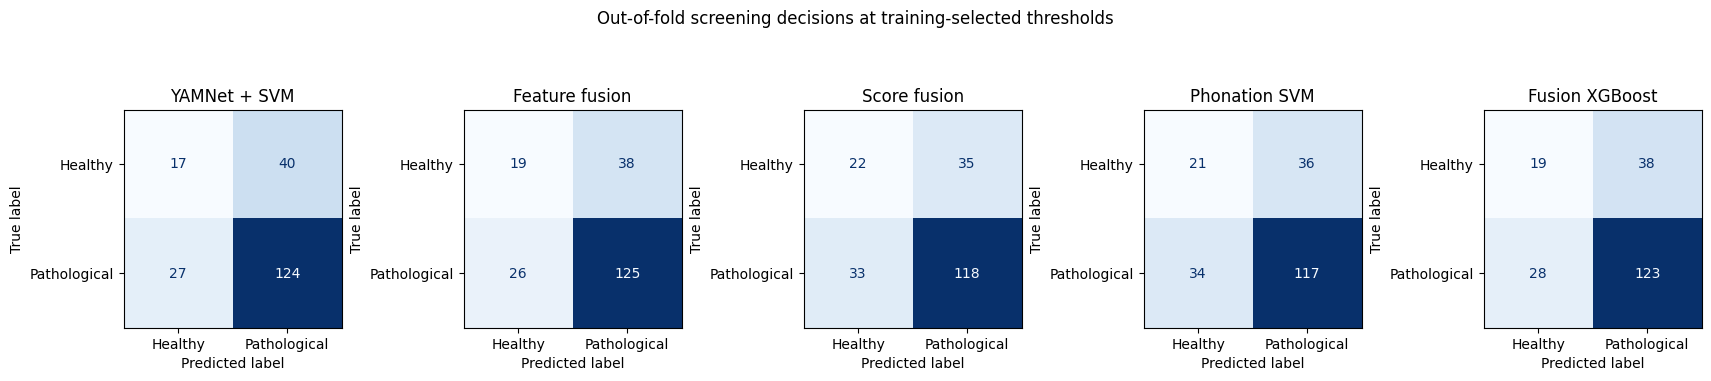

,Model,Timed recordings,Median audio-to-score ms,P90 audio-to-score ms,Encoder bytes,Fitted head bytes,CPU architecture
0,Frozen YAMNet + SVM,20,24.07,26.73,16093355,96534,x86_64
1,YAMNet + phonation (feature fusion),20,34.21,37.79,16093355,113302,x86_64
2,YAMNet + phonation (score fusion),20,35.68,37.94,16093355,121916,x86_64
3,Phonation SVM (AUROC tuning),20,13.30,14.80,0,25382,x86_64
4,Fusion XGBoost,20,352.97,491.33,0,133590,x86_64


In [ ]:
import io
import platform
from threadpoolctl import threadpool_limits

# Pool the out-of-fold predictions for counts; report mean fold metrics in the table above.
transfer_plot_order = [YAMNET_ONLY, YAMNET_EARLY, YAMNET_LATE, PHONATION_REFERENCE, XGB_REFERENCE]
plot_labels = ['YAMNet + SVM', 'Feature fusion', 'Score fusion', 'Phonation SVM', 'Fusion XGBoost']
fig, axes = plt.subplots(1, len(transfer_plot_order), figsize=(17, 4), layout='constrained')
for ax, name, label in zip(axes, transfer_plot_order, plot_labels):
    subset = transfer_oof[transfer_oof.Model == name]
    ConfusionMatrixDisplay.from_predictions(
        subset['True label'], subset.Prediction, labels=[0, 1],
        display_labels=['Healthy', 'Pathological'], colorbar=False, cmap='Blues', ax=ax,
    )
    ax.set_title(label)
fig.suptitle('Out-of-fold screening decisions at training-selected thresholds')
fig.savefig(OUT / 'pretrained_cnn_confusion.png', dpi=300)
plt.show()

audio_width = 3 * YAMNET_DIM


def score_transfer_record(record, name):
    audio, sr = load_voice(record)
    if name == XGB_REFERENCE:
        image = audio_to_spectrogram_image(audio, sr)
        image_stats = image_features(image, include_hog=False)
        measures = voice_quality_features(audio, sr)
        values = np.r_[image_stats, [measures[key] for key in quality_names]][None]
    else:
        audio_features = (np.zeros(audio_width) if name == PHONATION_REFERENCE
                          else pool_yamnet(yamnet_frames(audio, sr)))
        descriptors = ({} if name == YAMNET_ONLY else compact_phonation_features(audio, sr))
        values = np.r_[audio_features, [descriptors.get(key, np.nan) for key in phonation_names]][None]

    def branch_score(branch_name):
        fitted_branch = transfer_benchmark[branch_name]
        return rescaled_margin(fitted_branch['model'], values, fitted_branch['center_scale'])[0]

    if name == YAMNET_LATE:
        audio_weight, phonation_weight = SCORE_FUSION_WEIGHTS
        return (audio_weight * branch_score(YAMNET_ONLY) +
                phonation_weight * branch_score(PHONATION_REFERENCE))
    return branch_score(name)


def serialized_head_bytes(model):
    buffer = io.BytesIO()
    joblib.dump(model, buffer, compress=0)
    return buffer.tell()


transfer_runtime = []
with threadpool_limits(limits=1):
    for name in transfer_plot_order:
        score_transfer_record(benchmark_rows[0], name)  # Warm up decoder, features and classifier.
        times = []
        for row in benchmark_rows:
            start = perf_counter()
            score_transfer_record(row, name)
            times.append(1000 * (perf_counter() - start))
        branch_names = (YAMNET_ONLY, PHONATION_REFERENCE) if name == YAMNET_LATE else (name,)
        fitted_bytes = sum(serialized_head_bytes(transfer_benchmark[key]['model'])
                           for key in branch_names)
        encoder_bytes = YAMNET_FILE.stat().st_size if name in (YAMNET_ONLY, YAMNET_EARLY, YAMNET_LATE) else 0
        transfer_runtime.append({'Model': name, 'Timed recordings': len(times),
                                 'Median audio-to-score ms': np.median(times),
                                 'P90 audio-to-score ms': np.percentile(times, 90),
                                 'Encoder bytes': encoder_bytes, 'Fitted head bytes': fitted_bytes,
                                 'CPU architecture': platform.machine()})

transfer_runtime_table = pd.DataFrame(transfer_runtime)
transfer_runtime_table.to_csv(OUT / 'pretrained_cnn_cpu_benchmark.csv', index=False)
display(transfer_runtime_table.round(2))

### Inspect feature-fusion predictions

For one held-out recording from each class in the first fold, the plot shows how the feature-fusion SVM score changes when one embedding window is replaced with a training reference or one phonation descriptor is replaced with its training median. The effects describe model sensitivity to those replacements. The embedding windows overlap.

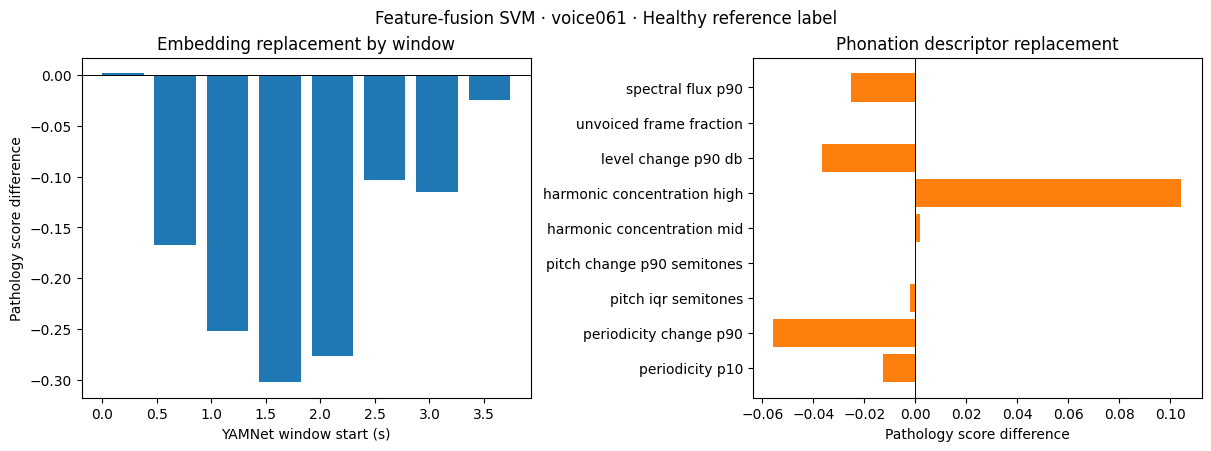

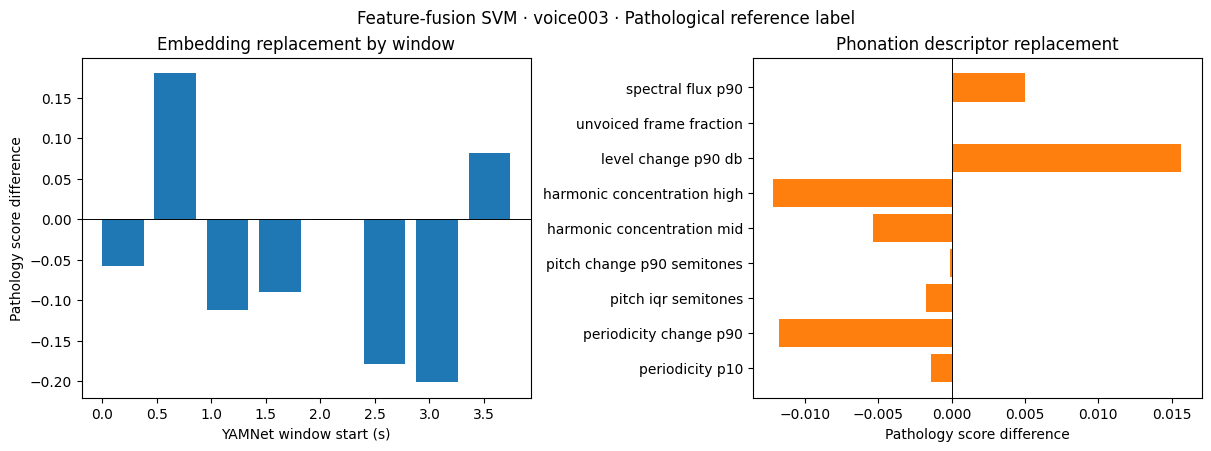

In [ ]:
# For each first-fold example, explain the feature-fusion SVM at recording level.
first_fit, first_test = outer_splits[0]
first_fusion = transfer_benchmark[YAMNET_EARLY]
fusion_model = first_fusion['model']
training_pool = yamnet_record_values[np.isin(yamnet_record_subjects, subject_ids[first_fit])]
embedding_baseline = np.median(training_pool[:, :YAMNET_DIM], axis=0)
phonation_baseline = (fusion_model.named_steps['features'].named_transformers_['phonation']
                      .named_steps['impute'].statistics_)
feature_effects, frame_effects = [], []

for wanted_label in (0, 1):
    person = next(subject_ids[i] for i in first_test if subject_y[i] == wanted_label)
    recording = next(row for row in manifest.itertuples(index=False) if str(row.subject_id) == person)
    waveform, rate = load_voice(recording)
    frames = yamnet_frames(waveform, rate)
    measures = compact_phonation_features(waveform, rate)
    descriptors = np.array([measures[name] for name in phonation_names])
    pooled = pool_yamnet(frames)
    values = np.r_[pooled, descriptors][None]
    score = rescaled_margin(fusion_model, values, first_fusion['center_scale'])[0]

    altered_windows = []
    for frame_index in range(len(frames)):
        altered = frames.copy()
        altered[frame_index] = embedding_baseline
        altered_windows.append(np.r_[pool_yamnet(altered), descriptors])
    temporal_change = score - rescaled_margin(
        fusion_model, np.stack(altered_windows), first_fusion['center_scale'])
    altered_features = np.repeat(values, len(descriptors), axis=0)
    altered_features[np.arange(len(descriptors)), audio_width + np.arange(len(descriptors))] = phonation_baseline
    acoustic_change = score - rescaled_margin(
        fusion_model, altered_features, first_fusion['center_scale'])

    starts = np.arange(len(frames)) * YAMNET_PATCH_STEP / YAMNET_RATE
    frame_effects.append(pd.DataFrame({'subject_id': person, 'Window start (s)': starts,
                                       'Score difference': temporal_change}))
    feature_effects.append(pd.DataFrame({'subject_id': person, 'Descriptor': phonation_names,
                                         'Score difference': acoustic_change}))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout='constrained')
    axes[0].bar(starts, temporal_change, width=0.38, align='edge', color='tab:blue')
    axes[0].set(xlabel='YAMNet window start (s)', ylabel='Pathology score difference',
                title='Embedding replacement by window')
    axes[0].axhline(0, color='black', linewidth=0.7)
    axes[1].barh([name.replace('_', ' ') for name in phonation_names],
                 acoustic_change, color='tab:orange')
    axes[1].set(xlabel='Pathology score difference', title='Phonation descriptor replacement')
    axes[1].axvline(0, color='black', linewidth=0.7)
    fig.suptitle(f'Feature-fusion SVM · {person} · {LABEL_NAME[wanted_label]} reference label')
    fig.savefig(OUT / f'pretrained_cnn_explanation_{wanted_label}.png', dpi=300)
    plt.show()

pd.concat(feature_effects, ignore_index=True).to_csv(
    OUT / 'pretrained_cnn_phonation_explanations.csv', index=False)
pd.concat(frame_effects, ignore_index=True).to_csv(
    OUT / 'pretrained_cnn_window_explanations.csv', index=False)

## 21. Statistical validation and reliability checks

The main comparison is score-fusion SVM versus fusion XGBoost. The primary metric is mean outer-fold AUROC. Balanced accuracy is the secondary metric. All comparisons are exploratory on VOICED. Each outer test set contains participants absent from fitting, feature selection, calibration and threshold selection for that split.

| Analysis | Outputs |
|---|---|
| Performance and uncertainty | Fold means and standard deviations, confusion counts, and 95% class-stratified participant-bootstrap intervals for accuracy, balanced accuracy, sensitivity, specificity, PPV, NPV, F1, MCC, AUROC, average precision, ROC specificity at the target sensitivity and probability metrics |
| Paired comparisons | Repeated 5-fold outer validation with four inner folds and three split seeds. Approximate Nadeau–Bengio corrected paired tests compare models on the same folds. Holm adjustment covers eight tests. Exact McNemar discordance tests on the primary out-of-fold decisions form a separate, descriptive family of four tests. |
| Calibration | A logistic calibrator is fitted to cross-fitted scores from the outer training participants. Held-out probability assessment includes Brier score, training-prevalence baseline, Brier skill, log loss, intercept, slope, and reliability plot. |
| Operating points | Thresholds for 70%, 80%, and 90% training sensitivity are fixed before evaluating the corresponding outer participants. |
| Recording robustness | Gain, additive noise, bandwidth reduction and trimming are applied to held-out recordings. The fitted fold models and thresholds stay fixed. Report class flips, agreement with clean predictions, score rank correlation, and the changes in discrimination. |
| Subgroup audit | Sensitivity, specificity, and Wilson intervals by recorded gender and age band when VOICED metadata are available. |
| Reproducibility | Split seeds, participant IDs, package versions and the pretrained encoder checksum are exported. |

Bootstrap intervals are conditional on the fitted outer models. The corrected paired tests account approximately for overlapping training folds. The agreement and subgroup intervals describe the available participants. Treat the audio checks as controlled perturbation robustness. Independent recordings from a second session are required for test–retest reliability, and an independent cohort is required for external validation.

[TRIPOD+AI reporting guidance](https://doi.org/10.1136/bmj-2023-078378) · [Clinical prediction model calibration](https://doi.org/10.1136/bmj-2023-078276) · [Corrected resampled tests](https://doi.org/10.1023/A:1024068626366)

,Model,Metric,Mean outer-fold estimate,Fold SD,Lower 95%,Upper 95%,Valid folds,Valid bootstrap draws
1,YAMNet + phonation (score fusion),Balanced accuracy,0.5823,0.0852,0.5176,0.6514,5,2000
2,YAMNet + phonation (score fusion),Sensitivity,0.7813,0.0772,0.7151,0.8475,5,2000
3,YAMNet + phonation (score fusion),Specificity,0.3833,0.1532,0.2758,0.5061,5,2000
9,YAMNet + phonation (score fusion),AUROC,0.6923,0.0880,0.6181,0.7664,5,2000
12,YAMNet + phonation (score fusion),Brier score,0.1867,0.0146,0.1751,0.1988,5,2000
17,Frozen YAMNet + SVM,Balanced accuracy,0.5573,0.0753,0.4990,0.6170,5,2000
18,Frozen YAMNet + SVM,Sensitivity,0.8206,0.0701,0.7548,0.8806,5,2000
19,Frozen YAMNet + SVM,Specificity,0.2939,0.1968,0.1894,0.3985,5,2000
25,Frozen YAMNet + SVM,AUROC,0.6827,0.0603,0.6100,0.7572,5,2000
28,Frozen YAMNet + SVM,Brier score,0.1897,0.0115,0.1795,0.1991,5,2000


,TN,FP,FN,TP
Model,,,,
Frozen YAMNet + SVM,17,40,27,124
Fusion XGBoost,19,38,28,123
Phonation SVM (AUROC tuning),21,36,34,117
YAMNet + phonation (feature fusion),19,38,26,125
YAMNet + phonation (score fusion),22,35,33,118


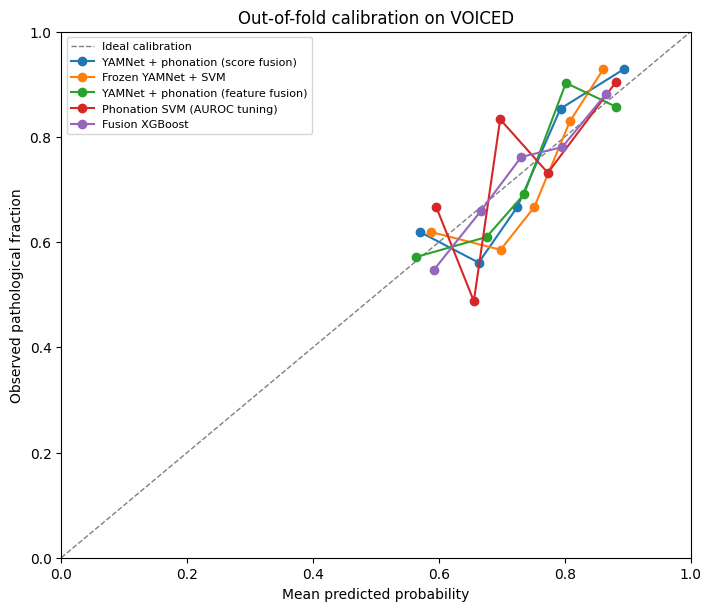

,Model,Participants,Observed prevalence,Mean predicted probability,Calibration intercept (offset),Calibration slope
0,YAMNet + phonation (score fusion),208,0.726,0.7290,-0.0162,0.6844
1,Frozen YAMNet + SVM,208,0.726,0.7412,-0.0825,1.0554
2,YAMNet + phonation (feature fusion),208,0.726,0.7313,-0.0292,0.5834
3,Phonation SVM (AUROC tuning),208,0.726,0.7207,0.0277,0.5013
4,Fusion XGBoost,208,0.726,0.7300,-0.0216,1.0722


In [ ]:
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.metrics import brier_score_loss, log_loss

STAT_BOOTSTRAPS = 2000
STAT_MODELS = [YAMNET_LATE, YAMNET_ONLY, YAMNET_EARLY, PHONATION_REFERENCE, XGB_REFERENCE]


def divide_or_nan(numerator, denominator):
    numerator, denominator = np.broadcast_arrays(numerator, denominator)
    return np.divide(numerator, denominator, out=np.full(numerator.shape, np.nan, dtype=float),
                     where=denominator != 0)


def metric_arrays(labels, predictions, score, probability, prevalence, indices):
    """Compute one row of each metric per resample. Inputs are aligned by participant."""
    observed = labels[indices]
    predicted = predictions[indices]
    correct = observed == predicted
    positive = observed == 1
    tp = np.sum(correct & positive, axis=1)
    tn = np.sum(correct & ~positive, axis=1)
    fp = np.sum(~correct & ~positive, axis=1)
    fn = np.sum(~correct & positive, axis=1)
    sensitivity = divide_or_nan(tp, tp + fn)
    specificity = divide_or_nan(tn, tn + fp)
    ppv = divide_or_nan(tp, tp + fp)
    npv = divide_or_nan(tn, tn + fn)
    f1_positive = divide_or_nan(2 * tp, 2 * tp + fp + fn)
    f1_negative = divide_or_nan(2 * tn, 2 * tn + fp + fn)
    mcc = divide_or_nan(tp * tn - fp * fn, np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))

    # Sort once per bootstrap draw. At tied thresholds, integrate the PR and ROC curves by group.
    ranked_scores = score[indices]
    order = np.argsort(-ranked_scores, axis=1, kind='stable')
    sorted_score = np.take_along_axis(ranked_scores, order, axis=1)
    sorted_label = np.take_along_axis(observed, order, axis=1)
    endpoints = np.column_stack((np.diff(sorted_score, axis=1) != 0, np.ones(len(indices), dtype=bool)))
    cum_positive = np.cumsum(sorted_label, axis=1)
    cum_negative = np.arange(1, indices.shape[1] + 1) - cum_positive
    # Carry the end-of-tie cumulative counts to every position in that tie.
    position = np.broadcast_to(np.arange(indices.shape[1]), endpoints.shape)
    next_end = np.minimum.accumulate(np.where(endpoints, position, indices.shape[1])[:, ::-1],
                                    axis=1)[:, ::-1]
    end_tp = np.take_along_axis(cum_positive, next_end, axis=1)
    end_fp = np.take_along_axis(cum_negative, next_end, axis=1)
    tie_start = np.column_stack((np.ones(len(indices), dtype=bool), endpoints[:, :-1]))
    start_positions = np.maximum.accumulate(np.where(tie_start, position, 0), axis=1)
    preceding_neg = np.column_stack((np.zeros(len(indices)), cum_negative[:, :-1]))
    start_fp = np.take_along_axis(preceding_neg, start_positions, axis=1)
    total_pos, total_neg = cum_positive[:, -1], cum_negative[:, -1]
    roc_area = divide_or_nan(np.sum(sorted_label * (total_neg[:, None] - (start_fp + end_fp) / 2),
                                   axis=1), total_pos * total_neg)
    average_precision = divide_or_nan(np.sum(sorted_label * end_tp / (end_tp + end_fp), axis=1),
                                      total_pos)
    roc_specificity = np.max(np.where((end_tp >= TARGET_SENSITIVITY * total_pos[:, None]) & endpoints,
                                      1 - divide_or_nan(end_fp, total_neg[:, None]), 0), axis=1)
    p = np.clip(probability[indices], 1e-8, 1 - 1e-8)
    prevalence_brier = ((prevalence[indices] - observed) ** 2).mean(axis=1)
    brier = ((p - observed) ** 2).mean(axis=1)
    return {
        'Accuracy': correct.mean(axis=1), 'Balanced accuracy': (sensitivity + specificity) / 2,
        'Sensitivity': sensitivity, 'Specificity': specificity, 'Precision (PPV)': ppv,
        'NPV': npv, 'Positive-class F1': f1_positive, 'Macro-F1': (f1_positive + f1_negative) / 2,
        'MCC': mcc, 'AUROC': roc_area, 'Average precision': average_precision,
        'ROC specificity at target sensitivity': roc_specificity, 'Brier score': brier,
        'Prevalence-only Brier score': prevalence_brier,
        'Brier skill vs prevalence': 1 - divide_or_nan(brier, prevalence_brier),
        'Log loss': -(observed * np.log(p) + (1 - observed) * np.log1p(-p)).mean(axis=1),
    }


def summarize_resamples(draws):
    finite = draws[np.isfinite(draws)]
    if not finite.size:
        return np.nan, np.nan, 0
    lo, hi = np.percentile(finite, [2.5, 97.5])
    return float(lo), float(hi), int(finite.size)


rng = np.random.default_rng(SEED + 100)
metric_draws = {name: {} for name in STAT_MODELS}
metric_points = {name: {} for name in STAT_MODELS}
for fold in sorted(transfer_oof.Fold.unique()):
    by_fold = transfer_oof[transfer_oof.Fold == fold]
    anchor = by_fold[by_fold.Model == XGB_REFERENCE].sort_values('subject_id')
    ids = anchor.subject_id.to_numpy()
    y_fold = anchor['True label'].to_numpy(dtype=int)
    draw_blocks = [rng.choice(np.flatnonzero(y_fold == label),
                              size=(STAT_BOOTSTRAPS, np.sum(y_fold == label)), replace=True)
                   for label in (0, 1)]
    indices = np.arange(len(y_fold))[None]
    indices = np.vstack((indices, np.concatenate(draw_blocks, axis=1)))
    for name in STAT_MODELS:
        model_fold = by_fold[by_fold.Model == name].set_index('subject_id').loc[ids]
        np.testing.assert_array_equal(y_fold, model_fold['True label'].to_numpy())
        result = metric_arrays(y_fold, model_fold.Prediction.to_numpy(dtype=int),
                               model_fold.Score.to_numpy(), model_fold.Probability.to_numpy(),
                               model_fold['Training prevalence'].to_numpy(), indices)
        for metric, values in result.items():
            metric_points[name].setdefault(metric, []).append(values[0])
            metric_draws[name].setdefault(metric, []).append(values[1:])
        assert np.isclose(result['AUROC'][0], roc_auc_score(y_fold, model_fold.Score))
        assert np.isclose(result['Average precision'][0], average_precision_score(y_fold, model_fold.Score))
        assert np.isclose(result['Brier score'][0], brier_score_loss(y_fold, model_fold.Probability))
        assert np.isclose(result['Log loss'][0], log_loss(y_fold, model_fold.Probability))

stat_intervals = []
for name in STAT_MODELS:
    for metric, points in metric_points[name].items():
        valid_points = np.isfinite(points)
        estimate = np.mean(np.asarray(points)[valid_points]) if valid_points.any() else np.nan
        fold_sd = np.std(np.asarray(points)[valid_points], ddof=1) if valid_points.sum() > 1 else np.nan
        draws = np.asarray(metric_draws[name][metric])[valid_points]
        mean_draws = np.mean(draws, axis=0) if len(draws) else np.array([])
        lo, hi, n_valid = summarize_resamples(mean_draws)
        stat_intervals.append({'Model': name, 'Metric': metric, 'Mean outer-fold estimate': estimate,
                               'Fold SD': fold_sd, 'Lower 95%': lo, 'Upper 95%': hi,
                               'Valid folds': int(valid_points.sum()), 'Valid bootstrap draws': n_valid})
stat_intervals = pd.DataFrame(stat_intervals)
stat_intervals.to_csv(OUT / 'final_statistical_metrics_and_intervals.csv', index=False)
display(stat_intervals[stat_intervals.Metric.isin(['AUROC', 'Balanced accuracy', 'Sensitivity',
                                                  'Specificity', 'Brier score'])].round(4))

stat_counts = transfer_fold_metrics.groupby('Model')[['TN', 'FP', 'FN', 'TP']].sum()
stat_counts.to_csv(OUT / 'final_statistical_pooled_confusion_counts.csv')
display(stat_counts)

# Calibration intercept with the logit as a fixed offset and a separately estimated slope.
calibration_rows, all_calibration_bins = [], []
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
ax.plot([0, 1], [0, 1], '--', color='gray', linewidth=1, label='Ideal calibration')
for name in STAT_MODELS:
    frame = transfer_oof[transfer_oof.Model == name]
    probability = frame.Probability.to_numpy()
    observed = frame['True label'].to_numpy()
    offsets = logit(np.clip(probability, 1e-8, 1 - 1e-8))
    intercept = brentq(lambda value: expit(offsets + value).mean() - observed.mean(), -40, 40)
    # Detect complete or quasi-separation before fitting an unpenalized descriptive slope.
    negative, positive = offsets[observed == 0], offsets[observed == 1]
    separated = negative.max() <= positive.min() or positive.max() <= negative.min()
    slope = np.nan
    if np.ptp(offsets) > 1e-8 and not separated:
        recalibration = LogisticRegression(C=np.inf, max_iter=1000)
        recalibration.fit(offsets[:, None], observed)
        slope = float(recalibration.coef_[0, 0])
    calibration_rows.append({'Model': name, 'Participants': len(frame),
                             'Observed prevalence': observed.mean(), 'Mean predicted probability': probability.mean(),
                             'Calibration intercept (offset)': intercept, 'Calibration slope': slope})
    # Quantile bins expose counts and work with the small dataset.
    bins = pd.qcut(probability, 5, duplicates='drop', labels=False)
    if np.isnan(bins).all():
        bins = np.zeros(len(probability), dtype=int)
    plotted = pd.DataFrame({'Bin': bins, 'Probability': probability, 'Observed': observed})
    bins_table = plotted.groupby('Bin').agg(Mean_probability=('Probability', 'mean'),
                                           Observed_fraction=('Observed', 'mean'),
                                           Participants=('Observed', 'size')).reset_index()
    bins_table.insert(0, 'Model', name)
    ax.plot(bins_table.Mean_probability, bins_table.Observed_fraction, marker='o', label=name)
    all_calibration_bins.append(bins_table)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted probability', ylabel='Observed pathological fraction',
       title=f'Out-of-fold calibration on {DATASET_MODE}')
ax.legend(fontsize=8)
fig.savefig(OUT / 'final_calibration_plot.png', dpi=250)
plt.show()
calibration_report = pd.DataFrame(calibration_rows)
calibration_report.to_csv(OUT / 'final_calibration_intercept_slope.csv', index=False)
pd.concat(all_calibration_bins, ignore_index=True).to_csv(OUT / 'final_calibration_bins.csv', index=False)
display(calibration_report.round(4))

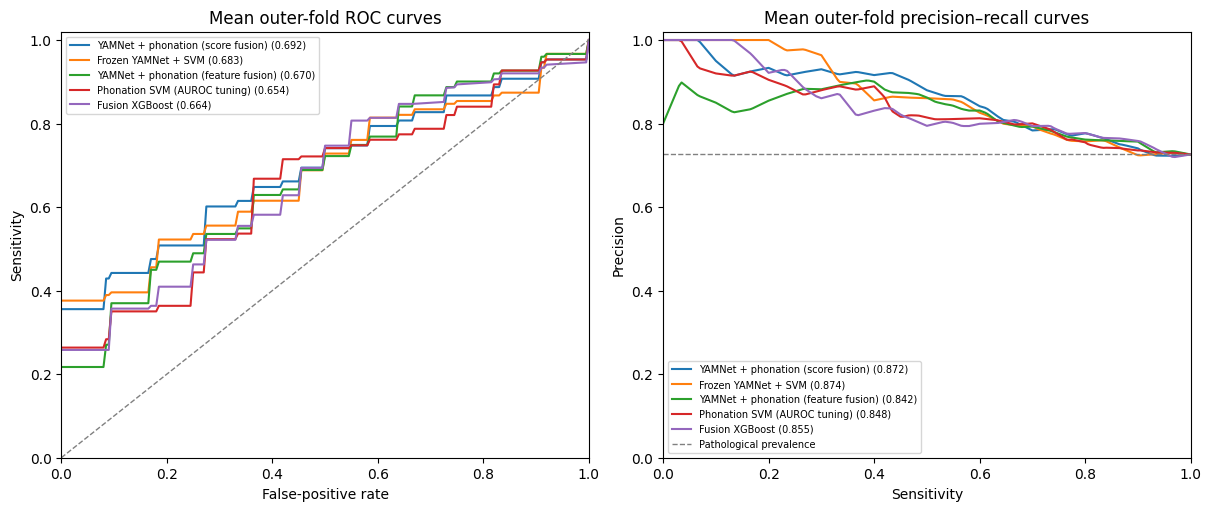

In [ ]:
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
x_axis = np.linspace(0, 1, 201)
for name in STAT_MODELS:
    roc_lines, pr_lines = [], []
    for _, frame in transfer_oof[transfer_oof.Model == name].groupby('Fold'):
        fpr, tpr, _ = roc_curve(frame['True label'], frame.Score)
        roc_lines.append(np.interp(x_axis, fpr, tpr))
        precision, recall, _ = precision_recall_curve(frame['True label'], frame.Score)
        # Precision-recall points use the empirical precision at each observed recall threshold.
        # Select the last threshold per duplicate recall for deterministic interpolation.
        unique_recall, start = np.unique(recall, return_index=True)
        pr_lines.append(np.interp(x_axis, unique_recall, precision[start]))
    auc = transfer_summary.loc[name, 'AUROC']
    ap = transfer_summary.loc[name, 'Average precision']
    axes[0].plot(x_axis, np.mean(roc_lines, axis=0), label=f'{name} ({auc:.3f})')
    axes[1].plot(x_axis, np.mean(pr_lines, axis=0), label=f'{name} ({ap:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[1].axhline(np.mean(subject_y), linestyle='--', color='gray', linewidth=1,
                label='Pathological prevalence')
axes[0].set(xlabel='False-positive rate', ylabel='Sensitivity', title='Mean outer-fold ROC curves')
axes[1].set(xlabel='Sensitivity', ylabel='Precision', title='Mean outer-fold precision–recall curves')
for ax in axes:
    ax.set(xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=7)
fig.savefig(OUT / 'final_oof_roc_and_precision_recall.png', dpi=250)
plt.show()

In [ ]:
# Compare the achieved operating points at several training sensitivity targets.
target_rows = []
for target in (0.70, TARGET_SENSITIVITY, 0.90):
    for (fold, name), frame in transfer_oof.groupby(['Fold', 'Model']):
        fit, _ = outer_splits[fold - 1]
        scores = transfer_fitted_folds[fold][name]['training_scores']
        threshold = screening_threshold(scores, subject_y[fit], target)
        predicted = (frame.Score.to_numpy() >= threshold).astype(int)
        if target == TARGET_SENSITIVITY:
            np.testing.assert_array_equal(predicted, frame.Prediction)
        metrics = binary_metrics(frame['True label'].to_numpy(), predicted)
        target_rows.append({'Training sensitivity target': target, 'Fold': fold,
                            'Model': name, 'Threshold': threshold,
                            'Achieved training sensitivity': np.mean(scores[subject_y[fit] == 1] >= threshold),
                            **metrics})
operating_results = pd.DataFrame(target_rows)
operating_results.to_csv(OUT / 'final_threshold_sensitivity_analysis.csv', index=False)

In [ ]:
from scipy.stats import t as student_t, binomtest

# The primary split uses seed 42. Each additional split repeats model selection and threshold fitting.
STAT_SPLIT_SEEDS = (SEED, SEED + 31, SEED + 59)
repeated_tables = [transfer_fold_metrics.assign(Seed=SEED)]
for split_seed in STAT_SPLIT_SEEDS[1:]:
    repeated_splits = list(StratifiedKFold(5, shuffle=True, random_state=split_seed)
                           .split(subject_ids, subject_y))
    metrics, _, _ = evaluate_transfer_folds(repeated_splits, split_seed)
    repeated_tables.append(metrics.assign(Seed=split_seed))
repeat_results = pd.concat(repeated_tables, ignore_index=True)
repeat_results.to_csv(OUT / 'final_repeat_fold_metrics.csv', index=False)
seed_means = repeat_results.groupby(['Seed', 'Model'], as_index=False)[
    ['AUROC', 'Balanced accuracy', 'Sensitivity', 'Specificity', 'Macro-F1', 'MCC']].mean()
seed_means.to_csv(OUT / 'final_seed_stability.csv', index=False)
display(seed_means.round(4))


def holm_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    adjusted = np.full(pvalues.shape, np.nan)
    valid = np.flatnonzero(np.isfinite(pvalues))
    order = valid[np.argsort(pvalues[valid])]
    adjusted[order] = np.minimum(1, np.maximum.accumulate(pvalues[order] * np.arange(len(order), 0, -1)))
    return adjusted


# The Nadeau–Bengio correction inflates the variance for overlapping training sets.
# AUROC is primary; balanced accuracy at the training-selected threshold is secondary.
corrected_rows = []
for candidate in (YAMNET_LATE, YAMNET_ONLY, YAMNET_EARLY, PHONATION_REFERENCE):
    for metric in ('AUROC', 'Balanced accuracy'):
        pivot = repeat_results.pivot(index=['Seed', 'Fold'], columns='Model', values=metric)
        differences = (pivot[candidate] - pivot[XGB_REFERENCE]).to_numpy()
        n = len(differences)
        fold_sizes = repeat_results[repeat_results.Model == XGB_REFERENCE][['TN','FP','FN','TP']].sum(axis=1).to_numpy()
        test_train_ratio = np.mean(fold_sizes / (len(subject_ids) - fold_sizes))
        average = differences.mean()
        corrected_se = np.sqrt((1 / n + test_train_ratio) * differences.var(ddof=1))
        test_stat = average / corrected_se if corrected_se > 0 else np.nan
        p_value = 2 * student_t.sf(abs(test_stat), n - 1) if np.isfinite(test_stat) else np.nan
        radius = student_t.ppf(0.975, n - 1) * corrected_se
        corrected_rows.append({'Model': candidate, 'Comparator': XGB_REFERENCE, 'Metric': metric,
                               'Paired folds': n, 'Mean difference': average,
                               'Corrected SE': corrected_se, 'Lower 95%': average - radius,
                               'Upper 95%': average + radius, 't': test_stat, 'df': n - 1,
                               'p': p_value})
corrected_tests = pd.DataFrame(corrected_rows)
corrected_tests['Holm p'] = holm_adjust(corrected_tests.p)
corrected_tests.to_csv(OUT / 'final_corrected_paired_tests.csv', index=False)
display(corrected_tests.round(4))

# McNemar uses each participant once from the primary OOF set, with fixed model thresholds.
# With overlapping CV training sets, this is an exploratory conditional disagreement test.
agreement_rows = []
reference = transfer_oof[transfer_oof.Model == XGB_REFERENCE].set_index('subject_id')
for candidate in (YAMNET_LATE, YAMNET_ONLY, YAMNET_EARLY, PHONATION_REFERENCE):
    challenger = transfer_oof[transfer_oof.Model == candidate].set_index('subject_id').loc[reference.index]
    truth = reference['True label'].to_numpy()
    np.testing.assert_array_equal(truth, challenger['True label'].to_numpy())
    reference_correct = reference.Prediction.to_numpy() == truth
    candidate_correct = challenger.Prediction.to_numpy() == truth
    candidate_only = int(np.sum(candidate_correct & ~reference_correct))
    reference_only = int(np.sum(reference_correct & ~candidate_correct))
    discordant = candidate_only + reference_only
    p_value = binomtest(candidate_only, discordant, 0.5).pvalue if discordant else 1.0
    agreement_rows.append({'Model': candidate, 'Comparator': XGB_REFERENCE,
                           'Participants': len(truth), 'Both correct': int((candidate_correct & reference_correct).sum()),
                           'Candidate only correct': candidate_only, 'Reference only correct': reference_only,
                           'Both incorrect': int((~candidate_correct & ~reference_correct).sum()),
                           'Paired accuracy difference': (candidate_only - reference_only) / len(truth),
                           'McNemar exact p': p_value})
mcnemar_report = pd.DataFrame(agreement_rows)
mcnemar_report['Holm p'] = holm_adjust(mcnemar_report['McNemar exact p'])
mcnemar_report.to_csv(OUT / 'final_mcnemar_disagreements.csv', index=False)
display(mcnemar_report.round(4))

Completed pretrained CNN evaluation for fold 1/5
Completed pretrained CNN evaluation for fold 2/5
Completed pretrained CNN evaluation for fold 3/5
Completed pretrained CNN evaluation for fold 4/5
Completed pretrained CNN evaluation for fold 5/5
Completed pretrained CNN evaluation for fold 1/5
Completed pretrained CNN evaluation for fold 2/5
Completed pretrained CNN evaluation for fold 3/5
Completed pretrained CNN evaluation for fold 4/5
Completed pretrained CNN evaluation for fold 5/5


,Seed,Model,AUROC,Balanced accuracy,Sensitivity,Specificity,Macro-F1,MCC
0,42,Frozen YAMNet + SVM,0.6827,0.5573,0.8206,0.2939,0.5469,0.1088
1,42,Fusion XGBoost,0.6644,0.5743,0.8138,0.3348,0.5758,0.1647
2,42,Phonation SVM (AUROC tuning),0.6540,0.5682,0.7742,0.3621,0.5640,0.1362
3,42,YAMNet + phonation (feature fusion),0.6698,0.5773,0.8273,0.3273,0.5698,0.1583
4,42,YAMNet + phonation (score fusion),0.6923,0.5823,0.7813,0.3833,0.5800,0.1662
5,73,Frozen YAMNet + SVM,0.6761,0.5958,0.7871,0.4045,0.5987,0.2150
6,73,Fusion XGBoost,0.6249,0.5598,0.7484,0.3712,0.5528,0.1171
7,73,Phonation SVM (AUROC tuning),0.6686,0.5727,0.7940,0.3515,0.5741,0.1585
8,73,YAMNet + phonation (feature fusion),0.6454,0.5792,0.7538,0.4045,0.5731,0.1653
9,73,YAMNet + phonation (score fusion),0.7102,0.6130,0.8002,0.4258,0.6138,0.2465


,Model,Comparator,Metric,Paired folds,Mean difference,Corrected SE,Lower 95%,Upper 95%,t,df,p,Holm p
0,YAMNet + phonation (score fusion),Fusion XGBoost,AUROC,15,0.0643,0.0551,-0.0538,0.1823,1.1671,14,0.2627,1.0
1,YAMNet + phonation (score fusion),Fusion XGBoost,Balanced accuracy,15,0.0369,0.0490,-0.0683,0.1421,0.7523,14,0.4643,1.0
2,Frozen YAMNet + SVM,Fusion XGBoost,AUROC,15,0.0396,0.0642,-0.0981,0.1774,0.6169,14,0.5472,1.0
3,Frozen YAMNet + SVM,Fusion XGBoost,Balanced accuracy,15,0.0220,0.0548,-0.0955,0.1396,0.4021,14,0.6937,1.0
4,YAMNet + phonation (feature fusion),Fusion XGBoost,AUROC,15,0.0243,0.0504,-0.0839,0.1325,0.4815,14,0.6376,1.0
5,YAMNet + phonation (feature fusion),Fusion XGBoost,Balanced accuracy,15,0.0155,0.0612,-0.1158,0.1468,0.2532,14,0.8038,1.0
6,Phonation SVM (AUROC tuning),Fusion XGBoost,AUROC,15,0.0162,0.0365,-0.0622,0.0945,0.4428,14,0.6647,1.0
7,Phonation SVM (AUROC tuning),Fusion XGBoost,Balanced accuracy,15,0.0111,0.0444,-0.0840,0.1063,0.2511,14,0.8054,1.0


,Model,Comparator,Participants,Both correct,Candidate only correct,Reference only correct,Both incorrect,Paired accuracy difference,McNemar exact p,Holm p
0,YAMNet + phonation (score fusion),Fusion XGBoost,208,120,20,22,46,-0.0096,0.8776,1.0
1,Frozen YAMNet + SVM,Fusion XGBoost,208,115,26,27,40,-0.0048,1.0000,1.0
2,YAMNet + phonation (feature fusion),Fusion XGBoost,208,120,24,22,42,0.0096,0.8830,1.0
3,Phonation SVM (AUROC tuning),Fusion XGBoost,208,116,22,26,44,-0.0192,0.6655,1.0


Completed repeatability check: Clean
Completed repeatability check: Gain −6 dB
Completed repeatability check: Noise 20 dB SNR
Completed repeatability check: Noise 10 dB SNR
Completed repeatability check: Low-pass 3 kHz
Completed repeatability check: Center 80%


,Condition,Model,Participants,Label flips,Flip fraction,Flip lower 95%,Flip upper 95%,Cohen kappa vs clean,Mean absolute probability change,AUROC,AUROC change,Balanced accuracy,Sensitivity,Specificity,Score rank correlation
0,Clean,YAMNet + phonation (score fusion),208,0,0.0000,0.0000,0.0181,1.0000,0.0000,0.6923,0.0000,0.5823,0.7813,0.3833,1.0000
1,Clean,Phonation SVM (AUROC tuning),208,0,0.0000,0.0000,0.0181,1.0000,0.0000,0.6540,0.0000,0.5682,0.7742,0.3621,1.0000
2,Gain −6 dB,YAMNet + phonation (score fusion),208,0,0.0000,0.0000,0.0181,1.0000,0.0000,0.6923,0.0000,0.5823,0.7813,0.3833,1.0000
3,Gain −6 dB,Phonation SVM (AUROC tuning),208,0,0.0000,0.0000,0.0181,1.0000,0.0000,0.6540,0.0000,0.5682,0.7742,0.3621,1.0000
4,Noise 20 dB SNR,YAMNet + phonation (score fusion),208,44,0.2115,0.1615,0.2720,0.3925,0.0541,0.6721,-0.0201,0.5665,0.8602,0.2727,0.8056
5,Noise 20 dB SNR,Phonation SVM (AUROC tuning),208,34,0.1635,0.1194,0.2197,0.4979,0.0403,0.6487,-0.0053,0.5523,0.9000,0.2045,0.8369
6,Noise 10 dB SNR,YAMNet + phonation (score fusion),208,59,0.2837,0.2267,0.3484,-0.0372,0.1032,0.5294,-0.1628,0.4983,0.9800,0.0167,0.4066
7,Noise 10 dB SNR,Phonation SVM (AUROC tuning),208,57,0.2740,0.2179,0.3383,-0.0189,0.1139,0.4915,-0.1625,0.5050,0.9933,0.0167,0.3103
8,Low-pass 3 kHz,YAMNet + phonation (score fusion),208,50,0.2404,0.1874,0.3028,0.4224,0.0499,0.6257,-0.0666,0.5813,0.7217,0.4409,0.8188
9,Low-pass 3 kHz,Phonation SVM (AUROC tuning),208,13,0.0625,0.0369,0.1040,0.8490,0.0099,0.6439,-0.0101,0.5814,0.7280,0.4348,0.9874


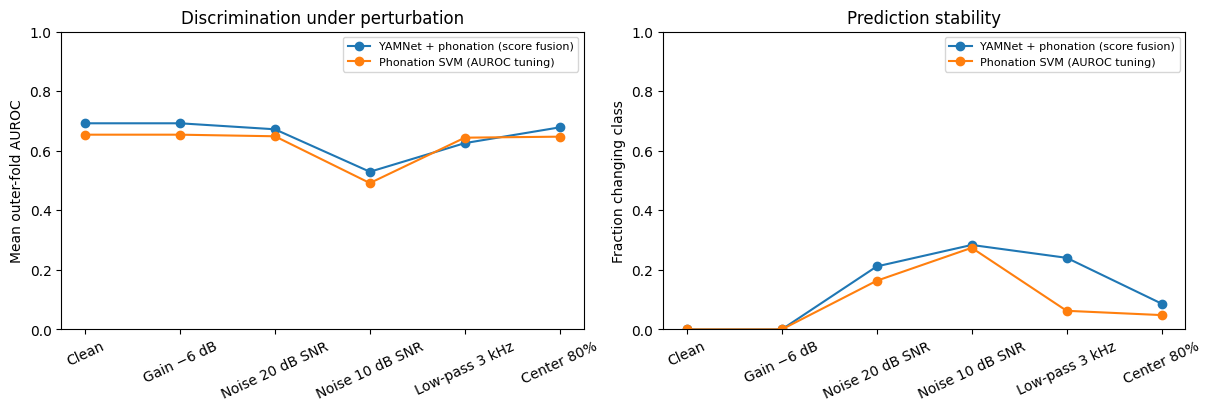

In [ ]:
from scipy.signal import butter, sosfiltfilt
from scipy.stats import spearmanr, norm
from sklearn.metrics import cohen_kappa_score
from threadpoolctl import threadpool_limits

ROBUSTNESS_MODELS = (YAMNET_LATE, PHONATION_REFERENCE)
AUDIO_CONDITIONS = ('Clean', 'Gain −6 dB', 'Noise 20 dB SNR', 'Noise 10 dB SNR',
                    'Low-pass 3 kHz', 'Center 80%')
lowpass = butter(4, 3000, fs=TARGET_SR, output='sos')


def apply_audio_condition(audio, condition, record_index):
    if condition == 'Clean':
        return audio
    if condition == 'Gain −6 dB':
        return audio * 10 ** (-6 / 20)
    if condition.startswith('Noise'):
        snr = float(condition.split()[1])
        generator = np.random.default_rng(np.random.SeedSequence([SEED, record_index]))
        noise = generator.standard_normal(len(audio))
        centered = audio - audio.mean()
        rms = np.sqrt(np.mean(centered ** 2))
        noise *= rms * 10 ** (-snr / 20) / np.sqrt(np.mean(noise ** 2))
        return audio + noise
    if condition == 'Low-pass 3 kHz':
        return sosfiltfilt(lowpass, audio)
    if condition == 'Center 80%':
        margin = len(audio) // 10
        return audio[margin:len(audio) - margin]
    raise ValueError(f'Unknown audio condition: {condition}')


def wilson_interval(successes, count):
    if count == 0:
        return np.nan, np.nan
    z = norm.ppf(0.975)
    p = successes / count
    center = (p + z ** 2 / (2 * count)) / (1 + z ** 2 / count)
    radius = z * np.sqrt(p * (1 - p) / count + z ** 2 / (4 * count ** 2)) / (1 + z ** 2 / count)
    return max(0, center - radius), min(1, center + radius)


def score_with_frozen_folds(values, model_names):
    rows = []
    for fold, (_, test_idx) in enumerate(outer_splits, start=1):
        held_out = values[test_idx]
        fitted = transfer_fitted_folds[fold]
        encoder = fitted[YAMNET_ONLY]
        phonation = fitted[PHONATION_REFERENCE]
        audio_score = rescaled_margin(encoder['model'], held_out, encoder['center_scale'])
        acoustic_score = rescaled_margin(phonation['model'], held_out, phonation['center_scale'])
        audio_weight, phonation_weight = SCORE_FUSION_WEIGHTS
        scores = {YAMNET_LATE: audio_weight * audio_score + phonation_weight * acoustic_score,
                  PHONATION_REFERENCE: acoustic_score}
        for name in model_names:
            score = scores[name]
            threshold = fitted[name]['threshold']
            probability = fitted[name]['calibrator'].predict_proba(score[:, None])[:, 1]
            rows.append(pd.DataFrame({
                'Fold': fold, 'Model': name, 'subject_id': subject_ids[test_idx],
                'True label': subject_y[test_idx], 'Score': score, 'Threshold': threshold,
                'Prediction': (score >= threshold).astype(int), 'Probability': probability,
            }))
    return pd.concat(rows, ignore_index=True)


audio_rows = [load_voice(row) for row in manifest.itertuples(index=False)]
perturbation_predictions = []
with threadpool_limits(limits=1):
    for condition in AUDIO_CONDITIONS:
        if condition == 'Clean':
            values = transfer_features
        else:
            record_vectors = []
            for idx, (audio, sr) in enumerate(audio_rows):
                perturbed = apply_audio_condition(audio, condition, idx)
                deep = pool_yamnet(yamnet_frames(perturbed, sr))
                phonation = compact_phonation_features(perturbed, sr)
                record_vectors.append(np.r_[deep, [phonation[key] for key in phonation_names]])
            values = subject_medians(np.stack(record_vectors), yamnet_record_subjects, subject_ids)
        prediction_frame = score_with_frozen_folds(values, ROBUSTNESS_MODELS)
        perturbation_predictions.append(prediction_frame.assign(Condition=condition))
        print(f'Completed repeatability check: {condition}', flush=True)

robust_oof = pd.concat(perturbation_predictions, ignore_index=True)
clean_scores = robust_oof[robust_oof.Condition == 'Clean'].set_index(['Model', 'subject_id']).sort_index()
existing = transfer_oof[transfer_oof.Model.isin(ROBUSTNESS_MODELS)].set_index(
    ['Model', 'subject_id']).sort_index()
np.testing.assert_allclose(clean_scores.Score, existing.Score, atol=1e-10)
robust_oof.to_csv(OUT / 'final_audio_robustness_oof.csv', index=False)

robust_rows = []
for (condition, name), changed in robust_oof.groupby(['Condition', 'Model'], sort=False):
    reference = clean_scores.loc[name].loc[changed.subject_id]
    flipped = changed.Prediction.to_numpy() != reference.Prediction.to_numpy()
    flip_lo, flip_hi = wilson_interval(int(flipped.sum()), len(flipped))
    fold_rows = []
    for fold, test in changed.groupby('Fold'):
        clean = reference.loc[test.subject_id]
        labels = test['True label'].to_numpy()
        performance = binary_metrics(labels, test.Prediction)
        rho = spearmanr(clean.Score, test.Score).statistic if test.Score.nunique() > 1 and clean.Score.nunique() > 1 else np.nan
        fold_rows.append({'AUROC': roc_auc_score(labels, test.Score),
                          'AUROC change': roc_auc_score(labels, test.Score) - roc_auc_score(labels, clean.Score),
                          'Balanced accuracy': performance['Balanced accuracy'],
                          'Sensitivity': performance['Sensitivity'], 'Specificity': performance['Specificity'],
                          'Score rank correlation': rho})
    robust_rows.append({'Condition': condition, 'Model': name, 'Participants': len(changed),
                        'Label flips': int(flipped.sum()), 'Flip fraction': flipped.mean(),
                        'Flip lower 95%': flip_lo, 'Flip upper 95%': flip_hi,
                        'Cohen kappa vs clean': cohen_kappa_score(reference.Prediction, changed.Prediction)
                        if len(np.unique(np.r_[reference.Prediction, changed.Prediction])) > 1 else np.nan,
                        'Mean absolute probability change': np.mean(np.abs(changed.Probability.to_numpy() -
                                                                          reference.Probability.to_numpy())),
                        **pd.DataFrame(fold_rows).mean().to_dict()})
robustness_report = pd.DataFrame(robust_rows)
robustness_report.to_csv(OUT / 'final_audio_robustness_summary.csv', index=False)
display(robustness_report.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for name, rows in robustness_report.groupby('Model', sort=False):
    axes[0].plot(rows.Condition, rows.AUROC, marker='o', label=name)
    axes[1].plot(rows.Condition, rows['Flip fraction'], marker='o', label=name)
for ax, title, ylabel in zip(axes, ('Discrimination under perturbation', 'Prediction stability'),
                             ('Mean outer-fold AUROC', 'Fraction changing class')):
    ax.set(title=title, ylabel=ylabel, ylim=(0, 1))
    ax.tick_params(axis='x', rotation=25)
    ax.legend(fontsize=8)
fig.savefig(OUT / 'final_audio_robustness.png', dpi=250)
plt.show()

In [ ]:
import hashlib
from importlib.metadata import version, PackageNotFoundError

# Only demographics explicitly released with VOICED are included in this audit.
if DATASET_MODE == 'VOICED':
    demographics = []
    for person in subject_ids:
        metadata = (RAW / f'{person}-info.txt').read_text(encoding='utf-8', errors='replace')
        age = re.search(r'^Age:[ \t]*(\d+)', metadata, re.IGNORECASE | re.MULTILINE)
        gender = re.search(r'^Gender:[ \t]*([mf])\b', metadata, re.IGNORECASE | re.MULTILINE)
        demographics.append({'subject_id': person, 'Age': int(age[1]) if age else np.nan,
                             'Recorded gender': {'f': 'Female', 'm': 'Male'}.get(
                                 gender[1].lower() if gender else '', 'Unspecified')})
    metadata_table = pd.DataFrame(demographics)
    metadata_table['Age group'] = pd.cut(metadata_table.Age, [0, 39, 54, np.inf],
                                          labels=['Under 40', '40–54', '55 and over']).astype('string').fillna('Unspecified')
    joined = transfer_oof[transfer_oof.Model.isin([YAMNET_LATE, XGB_REFERENCE])].merge(
        metadata_table, on='subject_id', validate='many_to_one')

    subgroup_rows = []
    for grouping in ('Recorded gender', 'Age group'):
        for (name, subgroup), frame in joined.groupby(['Model', grouping]):
            labels = frame['True label'].to_numpy(dtype=int)
            predictions = frame.Prediction.to_numpy(dtype=int)
            tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
            lo_se, hi_se = wilson_interval(tp, tp + fn)
            lo_sp, hi_sp = wilson_interval(tn, tn + fp)
            subgroup_rows.append({'Model': name, 'Grouping': grouping, 'Group': subgroup,
                                  'Participants': len(frame), 'Pathological': int(tp + fn),
                                  'Healthy': int(tn + fp), 'TP': int(tp), 'TN': int(tn),
                                  'Sensitivity': tp / (tp + fn) if tp + fn else np.nan,
                                  'Sensitivity lower 95%': lo_se, 'Sensitivity upper 95%': hi_se,
                                  'Specificity': tn / (tn + fp) if tn + fp else np.nan,
                                  'Specificity lower 95%': lo_sp, 'Specificity upper 95%': hi_sp})
    subgroup_report = pd.DataFrame(subgroup_rows)
    subgroup_report.to_csv(OUT / 'final_subgroup_checks.csv', index=False)
    display(subgroup_report.round(4))
else:
    print('Subgroup checks use the official VOICED age and gender fields and are skipped in CUSTOM mode.')

package_versions = {}
for package in ('numpy', 'pandas', 'scipy', 'scikit-learn', 'xgboost', 'wfdb',
                'librosa', 'scikit-image', 'praat-parselmouth', 'onnxruntime', 'torch'):
    try:
        package_versions[package] = version(package)
    except PackageNotFoundError:
        package_versions[package] = None

raw_splits = [{'Fold': fold, 'Test participants': subject_ids[test].tolist()}
              for fold, (_, test) in enumerate(outer_splits, start=1)]
config = {
    'Dataset mode': DATASET_MODE,
    'Participants': len(subject_ids),
    'Healthy': int(np.sum(subject_y == 0)),
    'Pathological': int(np.sum(subject_y == 1)),
    'Seeds': list(STAT_SPLIT_SEEDS),
    'Primary outer test IDs': raw_splits,
    'Inner folds': 4,
    'Outer folds per repeat': 5,
    'Bootstrap replicates': STAT_BOOTSTRAPS,
    'Target training sensitivity': TARGET_SENSITIVITY,
    'Primary model comparison': [YAMNET_LATE, XGB_REFERENCE],
    'Score fusion weights': dict(zip(['YAMNet', 'Phonation'], SCORE_FUSION_WEIGHTS)),
    'Primary endpoint': 'Mean outer-fold AUROC',
    'YAMNet model SHA-256': YAMNET_SHA256,
    'Input WAV sampling rate': TARGET_SR,
    'Audio perturbations': list(AUDIO_CONDITIONS),
    'Python version': platform.python_version(),
    'Package versions': package_versions,
}
(OUT / 'final_analysis_config.json').write_text(json.dumps(config, indent=2) + '\n', encoding='utf-8')

,Model,Grouping,Group,Participants,Pathological,Healthy,TP,TN,Sensitivity,Sensitivity lower 95%,Sensitivity upper 95%,Specificity,Specificity lower 95%,Specificity upper 95%
0,Fusion XGBoost,Recorded gender,Female,136,100,36,80,13,0.8000,0.7112,0.8666,0.3611,0.2248,0.5242
1,Fusion XGBoost,Recorded gender,Male,72,51,21,43,6,0.8431,0.7199,0.9183,0.2857,0.1381,0.4996
2,YAMNet + phonation (score fusion),Recorded gender,Female,136,100,36,76,18,0.7600,0.6677,0.8331,0.5000,0.3447,0.6553
3,YAMNet + phonation (score fusion),Recorded gender,Male,72,51,21,42,4,0.8235,0.6975,0.9043,0.1905,0.0767,0.4000
4,Fusion XGBoost,Age group,40–54,68,56,12,41,4,0.7321,0.6041,0.8304,0.3333,0.1381,0.6094
5,Fusion XGBoost,Age group,55 and over,56,47,9,42,1,0.8936,0.7741,0.9537,0.1111,0.0199,0.4350
6,Fusion XGBoost,Age group,Under 40,84,48,36,40,14,0.8333,0.7042,0.9130,0.3889,0.2478,0.5514
7,YAMNet + phonation (score fusion),Age group,40–54,68,56,12,42,3,0.7500,0.6231,0.8448,0.2500,0.0889,0.5323
8,YAMNet + phonation (score fusion),Age group,55 and over,56,47,9,39,2,0.8298,0.6986,0.9111,0.2222,0.0632,0.5474
9,YAMNet + phonation (score fusion),Age group,Under 40,84,48,36,37,17,0.7708,0.6346,0.8669,0.4722,0.3199,0.6299


5628

## 22. Explain the final score-fusion model

For each held-out participant, the model averages the normalized margins of the YAMNet SVM and the nine-descriptor phonation SVM. For a reference based on that fold's training participants, the following identity reconstructs the score.

$$s(x)=s(x_0)+w_a[m_a(x)-m_a(x_0)]+w_p[m_p(x)-m_p(x_0)].$$

Here, $m_a$ and $m_p$ are the normalized margins of the two SVMs and each weight is 0.5. The code verifies the score, decision threshold, predicted class, and calibrated probability against the saved out-of-fold prediction for every participant.

The second analysis replaces one YAMNet window embedding at a time, repeats audio pooling and evaluates the final fused score with the phonation branch fixed. It then replaces one phonation descriptor at a time with its training-fold median while keeping the audio branch fixed. Each table shows the change in the final score and whether the replacement crossed the original decision threshold. A positive score drop means that replacing the original evidence moved the decision away from the pathological class.

The branch decomposition is additive for this reference. The window and descriptor replacements are individual perturbations, and their effects may overlap. They describe the fitted model's response to the chosen references. When a participant has several recordings, the window replacement is applied to one recording at a time and the participant median is recomputed. Two figures show examples from the first outer fold, and the CSV files cover every held-out participant.

In [ ]:
# Explain the evaluated score-fusion model with the fitted models from each participant's fold.
# All reference values come from the corresponding outer training participants.
branch_rows, descriptor_rows, window_rows = [], [], []
audio_width = 3 * YAMNET_DIM
recording_rows = list(manifest.itertuples(index=False))
recording_ids = np.array([str(row.subject_id) for row in recording_rows])
oof_fusion = transfer_oof[transfer_oof.Model == YAMNET_LATE].set_index('subject_id')
assert oof_fusion.index.is_unique
audio_weight, phonation_weight = SCORE_FUSION_WEIGHTS


def branch_margin(fit, values):
    return rescaled_margin(fit['model'], values, fit['center_scale'])


def record_effects(fitted_fusion, score, perturbed_scores, threshold):
    probabilities = fitted_fusion['calibrator'].predict_proba(perturbed_scores[:, None])[:, 1]
    perturbed_labels = (perturbed_scores >= threshold).astype(int)
    return {
        'Original score': score,
        'Perturbed score': perturbed_scores,
        'Score drop': score - perturbed_scores,
        'Perturbed probability': probabilities,
        'Decision changed': perturbed_labels != int(score >= threshold),
    }


with threadpool_limits(limits=1):
    for fold, (fit_idx, test_idx) in enumerate(outer_splits, start=1):
        fold_models = transfer_fitted_folds[fold]
        audio_fit = fold_models[YAMNET_ONLY]
        phonation_fit = fold_models[PHONATION_REFERENCE]
        fusion_fit = fold_models[YAMNET_LATE]
        threshold = fusion_fit['threshold']

        # A participant-median reference weights each training participant equally.
        reference_audio = np.median(yamnet_subject_values[fit_idx], axis=0)
        reference_embedding = reference_audio[:YAMNET_DIM]
        reference_phonation = (phonation_fit['model'].named_steps['features']
                               .named_transformers_['phonation'].named_steps['impute'].statistics_)
        reference = np.r_[reference_audio, reference_phonation][None]
        audio_reference_score = branch_margin(audio_fit, reference)[0]
        phonation_reference_score = branch_margin(phonation_fit, reference)[0]
        reference_score = (audio_weight * audio_reference_score +
                           phonation_weight * phonation_reference_score)

        for index in test_idx:
            person = subject_ids[index]
            observed = oof_fusion.loc[person]
            features = transfer_features[index:index + 1]
            audio_score = branch_margin(audio_fit, features)[0]
            phonation_score = branch_margin(phonation_fit, features)[0]
            score = audio_weight * audio_score + phonation_weight * phonation_score
            probability = fusion_fit['calibrator'].predict_proba([[score]])[0, 1]
            predicted = int(score >= threshold)
            audio_contribution = audio_weight * (audio_score - audio_reference_score)
            phonation_contribution = phonation_weight * (phonation_score - phonation_reference_score)
            np.testing.assert_allclose(reference_score + audio_contribution + phonation_contribution,
                                       score, atol=1e-9)
            np.testing.assert_allclose([score, threshold, probability],
                                       [observed.Score, observed.Threshold, observed.Probability], atol=1e-9)
            assert predicted == observed.Prediction and fold == observed.Fold
            ids = {'Fold': fold, 'subject_id': person}
            branch_rows.append({
                **ids, 'True label': int(observed['True label']), 'Prediction': predicted,
                'YAMNet branch score': audio_score, 'Phonation branch score': phonation_score,
                'YAMNet weight': audio_weight, 'Phonation weight': phonation_weight,
                'Reference fused score': reference_score,
                'YAMNet contribution vs reference': audio_contribution,
                'Phonation contribution vs reference': phonation_contribution,
                'Reconstructed fused score': score, 'Decision threshold': threshold,
                'Margin above threshold': score - threshold, 'Calibrated probability': probability,
            })

            # Replace one participant-level descriptor. The audio branch remains fixed.
            descriptors = features[0, audio_width:]
            alternatives = np.repeat(features, len(phonation_names), axis=0)
            alternatives[np.arange(len(phonation_names)), audio_width + np.arange(len(phonation_names))] = (
                reference_phonation)
            changed_scores = (audio_weight * audio_score +
                              phonation_weight * branch_margin(phonation_fit, alternatives))
            descriptor_rows.append(pd.DataFrame({
                **ids, 'Descriptor': phonation_names, 'Observed value': descriptors,
                'Training reference value': reference_phonation,
                **record_effects(fusion_fit, score, changed_scores, threshold),
            }))

            # Replace one window in one recording, then repeat both levels of audio pooling.
            subject_records = np.flatnonzero(recording_ids == person)
            original_pooled = yamnet_record_values[subject_records]
            np.testing.assert_allclose(np.median(original_pooled, axis=0),
                                       features[0, :audio_width], atol=1e-8)
            for record_position, record_index in enumerate(subject_records):
                waveform, rate = load_voice(recording_rows[record_index])
                frames = yamnet_frames(waveform, rate)
                np.testing.assert_allclose(pool_yamnet(frames), original_pooled[record_position], atol=1e-8)
                window_features = np.repeat(features, len(frames), axis=0)
                for frame_index in range(len(frames)):
                    replaced = frames.copy()
                    replaced[frame_index] = reference_embedding
                    pooled_records = original_pooled.copy()
                    pooled_records[record_position] = pool_yamnet(replaced)
                    window_features[frame_index, :audio_width] = np.median(pooled_records, axis=0)
                changed_scores = (audio_weight * branch_margin(audio_fit, window_features) +
                                  phonation_weight * phonation_score)
                starts = np.arange(len(frames)) * YAMNET_PATCH_STEP / YAMNET_RATE
                window_rows.append(pd.DataFrame({
                    **ids, 'Recording index (0-based)': record_index, 'Window index (0-based)': np.arange(len(frames)),
                    'Window start (s)': starts,
                    'Window end (s)': np.minimum(starts + YAMNET_FULL_PATCH / YAMNET_RATE,
                                                len(waveform) / rate),
                    **record_effects(fusion_fit, score, changed_scores, threshold),
                }))
        print(f'Explained score fusion for outer fold {fold}/{len(outer_splits)}', flush=True)

fusion_branches = pd.DataFrame(branch_rows)
fusion_descriptors = pd.concat(descriptor_rows, ignore_index=True)
fusion_windows = pd.concat(window_rows, ignore_index=True)
assert fusion_branches.subject_id.is_unique and set(fusion_branches.subject_id) == set(subject_ids)
assert fusion_descriptors.groupby('subject_id').size().eq(len(phonation_names)).all()
assert set(fusion_windows.subject_id) == set(subject_ids)
fusion_branches.to_csv(OUT / 'score_fusion_branch_contributions.csv', index=False)
fusion_descriptors.to_csv(OUT / 'score_fusion_descriptor_replacements.csv', index=False)
fusion_windows.to_csv(OUT / 'score_fusion_window_replacements.csv', index=False)
print(f'Validated {len(fusion_branches)} held-out decisions, {len(fusion_descriptors)} '
      f'descriptor replacements and {len(fusion_windows)} window replacements.')

Explained score fusion for outer fold 1/5
Explained score fusion for outer fold 2/5
Explained score fusion for outer fold 3/5
Explained score fusion for outer fold 4/5
Explained score fusion for outer fold 5/5
Validated 208 held-out decisions, 1872 descriptor replacements and 1665 window replacements.


,Mean absolute contribution,Median absolute contribution
Branch,,
YAMNet contribution vs reference,0.2033,0.1709
Phonation contribution vs reference,0.3166,0.1589


,Descriptor,Mean_absolute_drop,Median_absolute_drop,Decision_changes,Participants
3,periodicity_change_p90,0.1071,0.0718,17,208
0,harmonic_concentration_high,0.1049,0.0547,12,208
7,spectral_flux_p90,0.0560,0.0260,6,208
2,level_change_p90_db,0.0549,0.0287,10,208
6,pitch_iqr_semitones,0.0372,0.0031,1,208
1,harmonic_concentration_mid,0.0346,0.0063,0,208
4,periodicity_p10,0.0226,0.0073,1,208
5,pitch_change_p90_semitones,0.0118,0.0001,0,208
8,unvoiced_frame_fraction,0.0047,0.0000,0,208


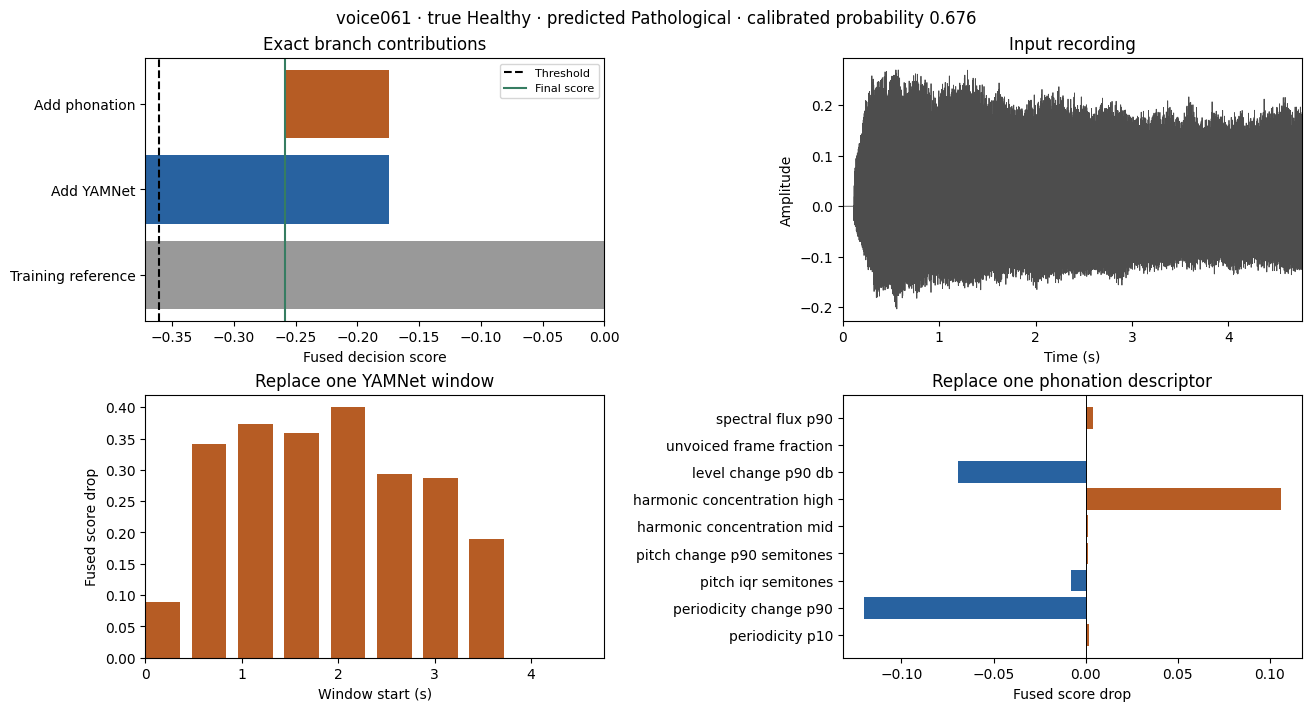

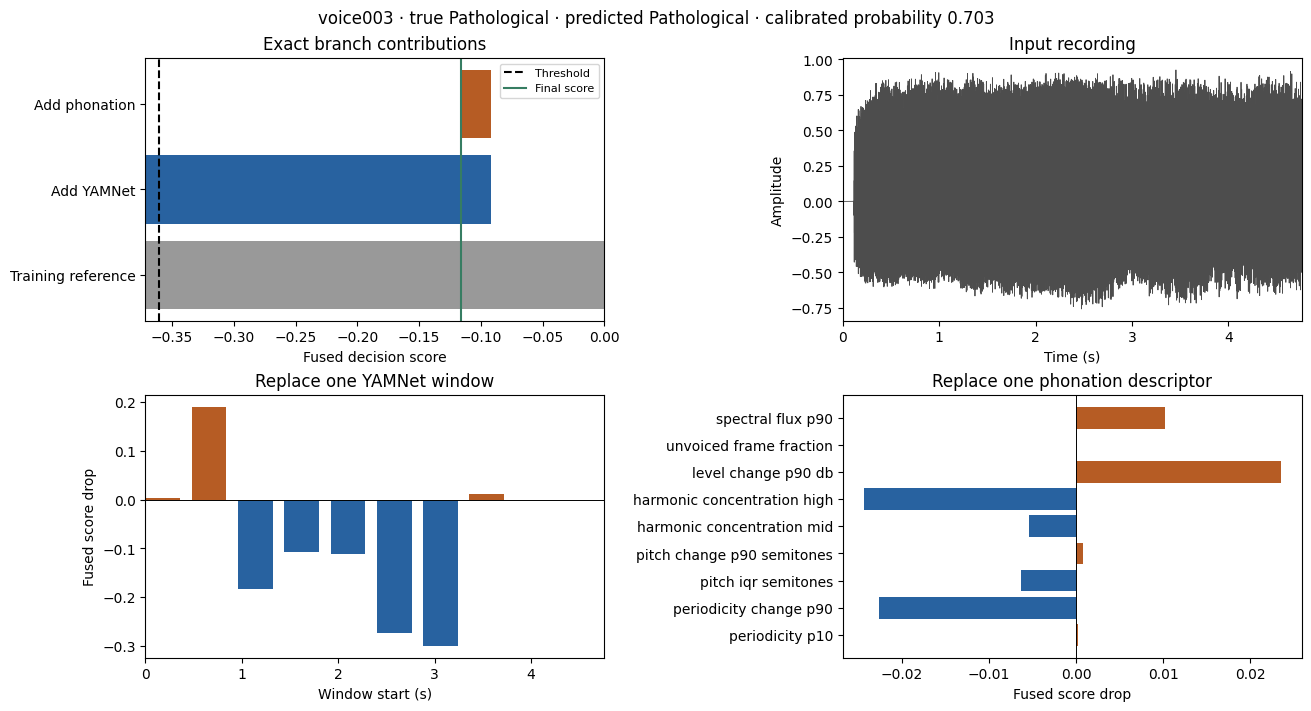

In [ ]:
contribution_columns = ['YAMNet contribution vs reference', 'Phonation contribution vs reference']
branch_summary = (fusion_branches[contribution_columns].abs()
                  .agg(['mean', 'median']).T.rename_axis('Branch'))
branch_summary.columns = ['Mean absolute contribution', 'Median absolute contribution']
branch_summary.to_csv(OUT / 'score_fusion_branch_summary.csv')

descriptor_summary = (fusion_descriptors.assign(Absolute_drop=fusion_descriptors['Score drop'].abs())
                      .groupby('Descriptor', as_index=False)
                      .agg(Mean_absolute_drop=('Absolute_drop', 'mean'),
                           Median_absolute_drop=('Absolute_drop', 'median'),
                           Decision_changes=('Decision changed', 'sum'),
                           Participants=('subject_id', 'nunique'))
                      .sort_values('Mean_absolute_drop', ascending=False))
descriptor_summary.to_csv(OUT / 'score_fusion_descriptor_summary.csv', index=False)
window_summary = (fusion_windows.assign(Absolute_drop=fusion_windows['Score drop'].abs())
                  .groupby('subject_id', as_index=False)
                  .agg(Mean_absolute_window_drop=('Absolute_drop', 'mean'),
                       Max_absolute_window_drop=('Absolute_drop', 'max'),
                       Windows=('Window index (0-based)', 'size'),
                       Any_decision_change=('Decision changed', 'any')))
window_summary.to_csv(OUT / 'score_fusion_window_summary_by_participant.csv', index=False)
display(branch_summary.round(4))
display(descriptor_summary.round(4))

# Use the first participant of each true class in outer fold 1, regardless of prediction correctness.
for label in (0, 1):
    available = fusion_branches[(fusion_branches.Fold == 1) & (fusion_branches['True label'] == label)]
    example = available.sort_values('subject_id').iloc[0]
    person = example.subject_id
    windows = fusion_windows[fusion_windows.subject_id == person]
    first_record = windows[windows['Recording index (0-based)'] == windows['Recording index (0-based)'].min()]
    descriptors = fusion_descriptors[fusion_descriptors.subject_id == person]
    record = recording_rows[int(first_record['Recording index (0-based)'].iloc[0])]
    waveform, sr = load_voice(record)
    time_axis = np.arange(len(waveform)) / sr
    fig, axes = plt.subplots(2, 2, figsize=(13, 7), layout='constrained')

    ax = axes[0, 0]
    reference = example['Reference fused score']
    cnn_delta, acoustic_delta = example[contribution_columns].to_numpy(dtype=float)
    ax.barh(['Training reference', 'Add YAMNet', 'Add phonation'],
            [reference, cnn_delta, acoustic_delta], left=[0, reference, reference + cnn_delta],
            color=['0.6', '#2862a0', '#b65c24'])
    ax.axvline(example['Decision threshold'], ls='--', color='black', label='Threshold')
    ax.axvline(example['Reconstructed fused score'], color='#367d62', label='Final score')
    ax.set(xlabel='Fused decision score', title='Exact branch contributions')
    ax.legend(fontsize=8)

    ax = axes[0, 1]
    ax.plot(time_axis, waveform, color='0.3', lw=0.6)
    ax.set(xlabel='Time (s)', ylabel='Amplitude', title='Input recording', xlim=(0, len(waveform) / sr))

    ax = axes[1, 0]
    effects = first_record['Score drop'].to_numpy()
    ax.bar(first_record['Window start (s)'], effects, width=0.36, align='edge',
           color=np.where(effects >= 0, '#b65c24', '#2862a0'))
    ax.axhline(0, color='black', lw=0.7)
    ax.set(xlabel='Window start (s)', ylabel='Fused score drop',
           title='Replace one YAMNet window', xlim=(0, len(waveform) / sr))

    ax = axes[1, 1]
    effects = descriptors['Score drop'].to_numpy()
    ax.barh(descriptors.Descriptor.str.replace('_', ' '), effects,
            color=np.where(effects >= 0, '#b65c24', '#2862a0'))
    ax.axvline(0, color='black', lw=0.7)
    ax.set(xlabel='Fused score drop', title='Replace one phonation descriptor')

    fig.suptitle(f'{person} · true {LABEL_NAME[label]} · '
                 f'predicted {LABEL_NAME[int(example.Prediction)]} · '
                 f'calibrated probability {example["Calibrated probability"]:.3f}')
    fig.savefig(OUT / f'score_fusion_explanation_class_{label}.png', dpi=300)
    plt.show()

## 23. ZIP results and download

The results archive contains the generated spectrograms, CSVs, graphs, and trained model.

In [ ]:
archive = ROOT / 'voice_image_ml_results.zip'
with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.rglob('*')):
        if f.is_file(): z.write(f, f.relative_to(ROOT))
    for f in sorted(IMAGES.glob('*.png')):
        z.write(f, f.relative_to(ROOT))
print('Created', archive, f'({archive.stat().st_size/1024/1024:.1f} MB)')
from google.colab import files
files.download(str(archive))

Created /content/voice_image_ml/voice_image_ml_results.zip (8.8 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>